# Simulating Timed Transfers and Bus Holding at Borella for Kadawatha-Pettah Metro Passengers

*Provenance: Human-written (wording edited with AI; see the provenance log).*

Running direct Metro buses between every origin and destination is impractical and would put more buses on already congested roads; coordinating existing Metro routes at shared stops, so passengers can transfer reliably, is a cheaper alternative. This notebook tests that idea at Borella, where Lanka Metro Transit routes CM01 (Makumbura-Colombo Fort/Pettah) and CM03 (Makumbura-Kadawatha) meet, and where Kadawatha-Pettah Metro passengers must transfer because no direct Metro service links the two. When traffic delays a feeder bus, transferring passengers miss their connection, but holding the connecting bus delays passengers already on board. A three-layer stochastic discrete-event simulation models this trade-off: a discrete-time Markov chain for road congestion estimated from the open cmb_traffic dataset, stop-by-stop Poisson boarding and alighting with an 80-passenger capacity, and a Borella interchange layer for transfer queueing and holding rules. After passing fifteen analytical, limiting-case, conservation and variance-reduction checks, the model compares schedule-based holding, real-time ETA-based holding and timetable shifts using common random numbers and 95% confidence intervals. On the current timetable, with peak buses full and passengers willing to wait about 20 minutes, 18.2% of through passengers miss their planned connection (about 51 a day). Letting connecting buses wait up to 5 min at Borella, using live bus positions, reduces this to 13.2% (about 37 a day) and cuts total passenger time by 8% on the existing 12 CM01 and 11 CM03 buses, with no timetable change. Timetable shifts add no significant gain, and one extra CM03 bus would save slightly more passenger time but miss more connections and needs an extra bus.

In [1]:
!pip install -q numpy pandas scipy matplotlib

In [2]:
import heapq
import bisect
from collections import defaultdict, namedtuple
import math
import zlib
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy
from scipy.stats import norm

SEED = 42  # master seed: every random number in the notebook comes from this

# Run sizes: simulated days (replications) per experiment. Larger values give narrower confidence intervals
# but a longer run; with these values Run all takes about 1 min on a laptop. Change them here only.
# The reduced side-experiment sizes give the same results, within the 95% CIs, as the larger 'full run' sizes.
R_CONV_POOL = 2000  # verification pool, also reused by E1 and E2 (must be >= R_FINAL)
R_FINAL = 1000      # E1 baseline and the final policy comparison
R_SWEEP = 400       # E2 holding sweep
R_GRID = 200        # E3 shift x hold grid, per cell (chooses the best policy)
R_E4 = 250          # E4 ETA-noise study (full run: 500)
R_E6 = 150          # E6 ticket validity (full run: 300)
R_OPS = 150         # operating-assumption check, early connectors wait or not (full run: 300)
R_FLEET = 500       # E7 current fleet vs one extra bus (full run: 1000)
R_SENS = 150        # X5 one-at-a-time sensitivity (full run: 250)
R_SENS_2D = 50      # X5 two-parameter grid, per cell (full run: 100)
assert R_CONV_POOL >= R_FINAL

# Policy limits tested: longest hold a connector may wait at Borella, and largest shift of a connecting direction's timetable.
MAX_HOLD_MIN = 5.0    # min, cap used for the policy search (E3) and the recommendation
HOLD_SWEEP_MAX_MIN = 10.0  # min, the E2 holding sweep goes further to show what longer holds would give
MAX_SHIFT_MIN = 10.0  # min, shifts tested in 5-min steps from -MAX_SHIFT_MIN to +MAX_SHIFT_MIN


def experiment_seeds(experiment_name, n_streams):
    # Each experiment gets its own seed streams, keyed by its name,
    # so re-running or changing one experiment does not change another's results.
    stream_key = zlib.crc32(experiment_name.encode("utf-8"))
    return np.random.SeedSequence(SEED, spawn_key=(stream_key,)).spawn(n_streams)

plt.rcParams.update({
    "figure.dpi": 130,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.25,
    "font.size": 10,
    "axes.titlesize": 11.5,
    "axes.labelsize": 10,
})

# Save figures to <repo>/figures when run from notebook/, otherwise to ./figures (repo root or Colab's /content)
FIGURES_DIR = Path("../figures") if Path("../data/timetables").exists() else Path("figures")
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

print(f"SEED = {SEED}")
print(f"numpy {np.__version__}, scipy {scipy.__version__}, matplotlib {plt.matplotlib.__version__}, pandas {pd.__version__}")

SEED = 42
numpy 2.5.5, scipy 1.18.1, matplotlib 3.11.2, pandas 3.1.1


## 1. Problem and question

*Provenance: AI-generated then modified.*

Two Lanka Metro Transit routes both stop at Borella in Colombo, at two nearby stops: Borella 02 (YMBA) on Baseline Road and Borella (Singer Mega) at Senanayake Junction, about 370 m apart:

- **Route CM01:** Makumbura to Pettah via Sethsiripaya, Rajagiriya, **Borella (Singer Mega)**, Town Hall and Colombo Fort (31 daily trips per direction, 12 buses).
- **Route CM03:** Makumbura to Kadawatha via Apeksha Hospital, Nawinna, Narahenpita Junction, **Borella 02 (YMBA)**, Campbell Park and Kelaniya University (27 daily trips per direction, 11 buses).

No single route connects Kadawatha directly with Pettah. A part-paid through-ticket with one transfer at Borella would serve this trip in both directions. The passenger pays part of the fare on the first bus and the balance on the connecting bus, provided they board it within the ticket validity window (proposed: 2 hours). Seats are not reserved, so boarding at Borella is first come, first served: a passenger who cannot board waits for the next Metro bus or leaves to use other transport.

| Transfer group | Trip direction | Feeder bus leg | Connecting bus leg |
|---|---|---|---|
| Group A | Kadawatha to Pettah | `CM03_KAD_to_MAK` | `CM01_MAK_to_FOR` |
| Group B | Pettah to Kadawatha | `CM01_FOR_to_MAK` | `CM03_MAK_to_KAD` |

Only Lanka Metro Transit buses are modelled, because the through-ticket works within one operator; private and CTB buses count as other transport.

CM01 and CM03 run every 15 to 35 minutes, but their timetables are not coordinated at Borella. Traffic variability, stop dwell times and full buses ($C = 80$) make connections unreliable, and a missed connection adds up to half an hour of waiting, more if the next bus is also full. The LMT-GO app already suggests this transfer in its journey planner, but gives no connection time and no coordination.

**Question:** What holding rule (no holding, schedule-based or real-time ETA-based holding) and timetable adjustment at Borella keep missed connections low in both directions, without delaying passengers already on board too much, using only the current Metro fleet?

## 2. Model, assumptions and equations

*Provenance: AI-generated then modified.*

### Concepts and Methods Applied

| Modelling concept | Role in this simulator | Equations and code routines |
|---|---|---|
| Discrete-event simulation and queueing | Primary: stop-level FIFO passenger queues and `heapq` Borella transfer event loop with tie-breaking [1] | `simulate_leg_day`, `simulate_direction_transfers` |
| Input modelling and random variate generation | Primary: inverse-transform exponential arrivals with thinning for the time-varying rate, uniform destinations, discrete Markov lookup, Knuth Poisson counts, Box-Muller normal ETA noise [6] | `sample_thinned_arrival_times`, `sample_discrete_state`, `sample_poisson_knuth`, `sample_standard_normal_box_muller` |
| Markov chains (DTMC) | Supporting: 3-state traffic chain whose 30-min transition matrices are estimated from consecutive cmb_traffic observations [3] (maximum likelihood, five time-of-day bands); stationary distributions and hourly validation | `estimate_transition_matrix`, `compute_stationary_distribution`, `generate_daily_traffic_grid` |
| Monte Carlo integration and law of large numbers | Supporting: multi-day replication ensembles with common random numbers (`SeedSequence`), 95% confidence intervals, and $O(R^{-1/2})$ convergence scaling [1] | `precompute_day_inputs`, `summarize_ci`, convergence check X2 |

### Timetable Cleaning, Borella Interpolation, and Target Mapping

- **Run times and Borella times:** The LMT-GO app [4] gives departure times only. Each leg $\ell$ is given a scheduled run time $R_\ell$ (75 min for CM01 Makumbura-Pettah, 120 min for CM03; metrobus.lk travel times [4]), and Borella is placed in proportion to road distance $d$ from OSRM routing on OpenStreetMap roads:

$$f_\ell = \frac{d_{\text{origin}\to B}}{d_{\text{origin}\to\text{terminal}}}, \qquad T_{\text{Borella,sched}} = T_{\text{dep}} + f_\ell R_\ell$$

  This gives $f = 0.746$ (CM01 to Pettah), $0.253$ (CM01 to Makumbura), $0.519$ (CM03 to Kadawatha) and $0.478$ (CM03 to Makumbura). It assumes constant scheduled speed along the leg. The bus duties in the app (each bus alternating between terminals) are consistent with these run times.

- **Target connector mapping:** Each feeder trip $f$ is assigned to the earliest opposite-direction connector trip $c(f)$ whose scheduled Borella time satisfies $T_{c,\text{sched}} \ge T_{f,\text{sched}}$ (or labelled `out_of_window` if no later connector exists). With walking time $w = 5.0\text{ min}$, the scheduled transfer slack is:

$$s_f = T_{c(f),\text{sched}} - \left(T_{f,\text{sched}} + w\right)$$

  Positive slack ($s_f > 0$) gives a scheduled buffer. With buses every 15-35 min, the median slack is 8.3 min and 13 of the 56 planned connections have under 6 min. Five pairs are scheduled shorter than the walk: four Pettah-to-Kadawatha pairs (`CM01-PET-04`, `-20`, `-23`, `-25`) by 1.7 min and one Kadawatha-to-Pettah pair (`CM03-KAD-11`) by 1.4 min, so they are always missed unless the connector waits. Two late Kadawatha feeders (`CM03-KAD-26`, `-27`) reach Borella after the last CM01 to Pettah (19:11) and have no Metro connection (`out_of_window`).

### Layer 1: Discrete-Time Markov Traffic Model (estimated from cmb_traffic)

Each route direction has its own traffic state $S_t \in \{0:\text{Free},\, 1:\text{Slow},\, 2:\text{Jammed}\}$ on $\Delta t = 30\text{ min}$ slots, the sampling interval of the open `cmb_traffic` dataset [3] (about 68,000 observations, Nov 2025-May 2026, 05:00-22:00, of the 12 route directions on the roads CM01 and CM03 use: Borella-Fort, Borella-Dematagoda-Kiribathgoda, Kottawa-Pamankada via Maharagama and Nawinna, and Borella-Aturugiriya and Borella-Kaduwela via Rajagiriya and Battaramulla). An observation is Free, Slow or Jammed when the corridor's travel-time ratio (free-flow speed / speed) is below 1.3, between 1.3 and 2.0, or at least 2.0, with free-flow speed the 90th percentile of all its observations.

**Transition matrices.** For each time-of-day band $b$ (early 05:00-07:00, morning peak 07:00-09:00, midday 09:00-16:00, evening peak 16:00-19:00, evening 19:00-22:00), the maximum-likelihood estimate of the 30-min matrix counts consecutive observations of the same corridor 20-40 min apart. A pair is counted in the band of its first observation, which is how the simulation applies the matrices (a step from slot $t$ uses the band of slot $t$). Pairs from 06:30-06:59 into the morning peak therefore carry the start of the morning build-up in the early matrix (12 of its 54 slow pairs become jammed, $\hat{P}^{(\text{early})}_{\text{slow,jammed}} = 0.22$). Counting only pairs inside one band was tested and fits the observed morning traffic worse (07:00 jammed share 1% vs 7% observed; it fails Check 2a). The estimate is:

$$\hat{P}^{(b)}_{ij} = \frac{n^{(b)}_{ij}}{\sum_k n^{(b)}_{ik}}$$

A row with fewer than 30 observed pairs in a band (jammed in the early morning) uses the all-day row. Traffic is free until 05:00 (the first hour of data, almost all free), then each step uses the matrix of its slot's band, so traffic builds up and clears through the day. Given state $i$ and $U \sim \text{Uniform}(0, 1)$, the next state uses inverse-transform lookup:

$$j = \min\left\{k \in \{0, 1, 2\} : \sum_{m=0}^{k} \hat{P}_{i,m} \ge U\right\}$$

**State speeds.** The speed in state $k$ during band $b$ is the mean observed speed of those observations (free 28.8-35.8 km/h, slow 22.7-27.0 km/h, jammed 17.5-18.9 km/h). The stationary distribution $\pi^*$ solves $\pi^* \hat{P} = \pi^*$, $\sum_k \pi^*_k = 1$, and is used in the journey-speed check.

Per-leg bus speed factors $\alpha_{\ell}$ are calibrated by bisection so the mean simulated delay at Borella over 120 calibration days is zero, given the scheduled run times.

### Layer 2: Stop-by-Stop Bus Journey, Arrivals, and Dwell Time

At each stop $s$, passenger arrivals begin $30\text{ min}$ before the first bus is scheduled at that stop (scheduled times placed by road distance, as for Borella) with rate $\lambda_s(t) = \lambda_{s,0} \cdot m(t)$, where $m(t) = 1.35$ during peak periods and $0.85$ off-peak. This non-homogeneous Poisson process is sampled exactly by thinning (Lewis-Shedler) [6]: candidates are drawn at the maximum rate $\lambda^{\max}_s = 1.35\,\lambda_{s,0}$ by inverse transform and each is kept with probability $\lambda_s(t)/\lambda^{\max}_s$:

$$\Delta\tau = -\frac{\ln(1 - U_1)}{\lambda^{\max}_s}, \qquad \text{accept if } U_2 \le \frac{\lambda_s(t)}{\lambda^{\max}_s}, \qquad d \sim \text{Uniform}\{s+1, \dots, n_{\text{stops}}-1\}$$

At stop $s$, $a_s$ on-board passengers alight, and $b_s = \min(q_s, C - (\text{load}_s - a_s))$ waiting passengers board in FIFO order up to bus capacity $C = 80$. Stop dwell time is linear:

$$t_{\text{dwell},s} = \frac{t_{\text{door}} + t_{\text{alight}}\, a_s + t_{\text{board}}\, b_s}{60}\quad [\text{min}]$$

with $t_{\text{door}} = 12\text{ s}$, $t_{\text{alight}} = 2\text{ s/pax}$, and $t_{\text{board}} = 2\text{ s/pax}$.

### Layer 3: Borella Transfer Queueing, Holding Policies, and Objective

Each feeder trip $f$ carries $m_f \sim \text{Poisson}(5)$ through-ticket passengers (Knuth algorithm) who become ready at $T_{f,\text{ready}} = T_{f,\text{arr,Borella}} + w$. Buses keep their published times only at the origin terminal, so a connector leaves Borella as soon as it has served the stop:

$$T_{c,\text{base}} = T_{c,\text{arr,Borella}} + t_{c,\text{dwell}}$$

Holding a connecting bus for late feeders at a transfer point trades the transferring passengers' wait against delay to riders already on board [5]. Let $\mathcal{F}_c = \{f : c(f) = c\}$ be the protected feeders targeting connector $c$, and let $T_{c,\text{cap}} = T_{c,\text{base}} + h$ be the latest departure allowed by holding:

1. **No holding (`none`):** Connector $c$ departs at $T_{c,\text{dep}} = T_{c,\text{base}}$.
2. **Schedule holding (`schedule`):** Connector $c$ waits for all protected feeders, up to the cap:

$$T_{c,\text{dep}} = \min\left(T_{c,\text{cap}},\; \max\left(T_{c,\text{base}},\; \max_{f \in \mathcal{F}_c} T_{f,\text{ready}}\right)\right)$$

3. **Real-time ETA holding (`realtime`):** Using estimated feeder ready time $\hat{T}_{f,\text{ready}} = T_{f,\text{ready}} + \varepsilon_f$ with $\varepsilon_f \sim \mathcal{N}(0, \sigma_{\text{eta}}^2)$ generated via Box-Muller transform, the connector protects only feeders predicted to be catchable, $\mathcal{F}_c^{\text{ETA}} = \{f \in \mathcal{F}_c : \hat{T}_{f,\text{ready}} \le T_{c,\text{cap}}\}$, and skips holding if $\mathcal{F}_c^{\text{ETA}}$ is empty or already ready.

**First-come, first-served boarding.** Local Borella passengers and through-ticket passengers form one queue ordered by arrival time and board up to $C - N_c$ free places, where $N_c$ is the connector load after Borella alighting. No seats are reserved.

**Patience and ticket validity.** A passenger who misses the planned connector (timing miss) or is refused by a full bus (capacity miss) waits for the next connector only if it is scheduled within the patience limit $P$ of the current time $t$ and within the ticket validity $V$ of their arrival at Borella:

$$\text{wait} \iff T_{\text{next,sched}} - t \le P \quad\text{and}\quad T_{\text{next,sched}} - T_{f,\text{ready}} \le V$$

Otherwise the passenger is **lost** to other transport and is charged the time already waited plus an alternative-travel penalty $\pi_{\text{alt}}$. The same patience rule applies to local passengers left behind by full buses at every stop. Feeder trips with no later connector in the day (`out_of_window`) send all their passengers to other transport at cost $\pi_{\text{alt}}$, so a timetable shift cannot lower the cost by pushing passengers out of the analysis window.

Policy performance is evaluated via expected daily equivalent passenger-minutes:

$$J(h, \Delta) = w_{\text{wait}}\, \mathbb{E}\left[\sum_{i} (w + W_i) + \pi_{\text{alt}} N_{\text{oow}}\right] + w_{\text{hold}}\, \mathbb{E}\left[\sum_{b} N_b \cdot \text{hold}_b\right], \qquad w_{\text{wait}} = 2.0,\; w_{\text{hold}} = 1.0$$

where $w$ is the walk between the two Borella stops, $W_i$ is the wait at the connector stop of in-window passenger $i$ (including $\pi_{\text{alt}}$ when lost) and $N_{\text{oow}}$ is the number of out-of-window passengers. Counting the walk keeps a longer interchange walk from looking cheaper.

### Fleet, Timing Point and Extra Bus

- **Bus duties and fleet:** the bus registration numbers in the app give each bus's trips for the day (its duty): 12 CM01 buses and 11 CM03 buses, each alternating between its two terminals. A duty is feasible when every trip starts after the previous one is scheduled to arrive. A timetable shift moves only the trips of the connecting direction (CM01 to Pettah for Group A, CM03 to Kadawatha for Group B) and is allowed only if every duty keeps a non-negative layover, so the bus count is unchanged.
- **Borella timing point:** a connector never leaves Borella before its published Borella time: $T_{c,\text{base}} = \max(T_{c,\text{sched}},\, T_{c,\text{arr}} + t_{c,\text{dwell}})$. Time spent waiting for the published time is charged as on-board hold time in $J$.
- **One extra bus:** the extra bus makes round trips from Makumbura with the route's scheduled run times and a turnaround of $\tau = 10$ min, until its next Makumbura departure would be after the route's last one. Its first departure (5-min grid) minimises $\sum_k h_k^2$ over the terminal headways $h_k$ (a random passenger waits $\sum h_k^2 / 2\sum h_k$ on average). The rule uses the timetable only, never transfer results. Through demand stays fixed: extra feeder trips carry no through passengers.
- **Turnaround reliability:** a planned turnaround is late when the simulated terminal arrival is after the bus's next published departure. Borella holding is not added, so this is a lower bound.

### Parameter Summary and Data Provenance

| Parameter | Baseline value | Unit | Provenance / status |
|---|---|---|---|
| Schedules (CM01, CM03) | 116 daily trips, 12 + 11 buses | HH:MM | Empirical: departure times and bus numbers from the LMT-GO app (19 Nov 2026) [4] |
| Scheduled run time $R_\ell$ | 75 (CM01), 120 (CM03) | min | metrobus.lk travel times (19 Nov 2026) [4]; consistent with the app's bus duties |
| Bus capacity $C$ | 80 | pax | Assumption: unofficial figure reported in news and wiki pages about the Metro buses (seats plus standing) |
| Peak windows | 07:00-09:00, 16:00-19:00 | HH:MM | Empirical: slowest hours in cmb_traffic [3]; used for traffic bands and passenger demand |
| Dwell parameters ($t_{\text{door}}, t_{\text{alight}}, t_{\text{board}}$) | 12, 2, 2 | s, s/pax | Assumption; boarding is quick because fares are collected on board after boarding (author's observation) |
| Segment distances | Leg arrays | km | Empirical: OSRM road routing on OpenStreetMap between geocoded stops (`scripts/build_corridor_geometry.py`) |
| Borella fraction $f_\ell$ | 0.746, 0.253, 0.519, 0.478 | - | Derived from the road distances above |
| Walk time $w$ | 5.0 (2.0-6.5 swept) | min | Estimate: the walk along Baseline Road via Senanayake Junction is about 370 m (about 4.7 min at 1.3 m/s) plus the junction crossing |
| Traffic chain and state speeds | 5 time bands, 30-min steps | - | Empirical: estimated from consecutive cmb_traffic observations [3] (`data/traffic/traffic_transitions.csv`, `traffic_states.csv`) |
| Base stop arrival rates $\lambda_{s,0}$ | 0.20-1.30 | pax/min | Assumption, scaled so the busiest bus in each direction fills to capacity at peak (author's observation that Metro buses are packed at peak; crowded peak buses are also reported for the Western Province [2]); tested at 0.75x-1.25x |
| Peak and off-peak demand multipliers $m(t)$ | 1.35, 0.85 | - | Assumption |
| Transfer demand mean $m$ | 5.0 | pax/feeder | Synthetic assumption (tested across 3-8 in sensitivity analysis) |
| Passenger patience $P$ | 20 (10-30 swept) | min | Assumption based on the author's experience: passengers wait about 10-20 min for the next bus |
| Real-time ETA error $\sigma_{\text{eta}}$ | 1.0 (0-4 tested) | min | Assumption |
| Ticket validity $V$ | 120 | min | Proposed fare-integration rule (part-paid ticket valid for 2 hours) |
| Alternative-travel penalty $\pi_{\text{alt}}$ | 60 | min | Assumption |
| Connector waits for Borella schedule | No (Yes tested as a scenario) | - | Observed: Metro buses do not currently wait at Borella when early (author's observation, 19 Nov 2026) |

## 3. Implementation

*Provenance: AI-generated then modified.*

In [3]:
WALK_TIME_MIN = 5.0  # min, Borella 02 (YMBA) to Borella (Singer Mega): 370 m at about 1.3 m/s plus the junction crossing

# Stop-to-stop road distances (km) along each direction, from OSRM routing on OpenStreetMap roads
# (scripts/build_corridor_geometry.py, side-street detours to off-road stop coordinates removed).
# base_arrival_rate_pax_per_min: assumed stop demand (pax/min) before the peak/off-peak multiplier, doubled from the first
# guess so the busiest bus in each direction fills to capacity at peak, as observed on Metro buses.
# scheduled_run_min: origin-to-terminal scheduled run time (min), metrobus.lk travel times accessed 19 Nov 2026:
# CM01 72 min Makumbura-Colombo Fort plus 3 min Fort-Pettah, CM03 120 min. The app gives departure times only.
ROUTE_LEGS_CONFIG = {
    "CM01_MAK_to_FOR": {
        "route": "CM01", "origin": "Makumbura", "destination": "Pettah",
        "stops": ["Makumbura", "Sethsiripaya", "Rajagiriya", "Borella (Singer Mega)", "Town Hall", "Colombo Fort", "Pettah"],
        "segment_distances_km": [11.45, 2.76, 1.95, 1.88, 3.11, 0.51],
        "borella_idx": 3,
        "base_arrival_rate_pax_per_min": [0.90, 0.70, 0.60, 0.40, 0.24, 0.00, 0.00],
        "scheduled_run_min": 75.0,
    },
    "CM01_FOR_to_MAK": {
        "route": "CM01", "origin": "Pettah", "destination": "Makumbura",
        "stops": ["Pettah", "Town Hall", "Borella (Singer Mega)", "Rajagiriya", "Sethsiripaya", "Makumbura"],
        "segment_distances_km": [3.68, 1.85, 2.40, 2.67, 11.29],
        "borella_idx": 2,
        "base_arrival_rate_pax_per_min": [1.30, 0.50, 0.40, 0.30, 0.20, 0.00],
        "scheduled_run_min": 75.0,
    },
    "CM03_MAK_to_KAD": {
        "route": "CM03", "origin": "Makumbura", "destination": "Kadawatha",
        "stops": ["Makumbura", "Apeksha Hospital", "Nawinna", "Narahenpita Junction", "Borella 02 (YMBA)", "Campbell Park", "Kelaniya University", "Kadawatha"],
        "segment_distances_km": [5.98, 1.12, 7.20, 2.36, 0.73, 8.96, 5.78],
        "borella_idx": 4,
        "base_arrival_rate_pax_per_min": [0.64, 0.40, 0.40, 0.50, 0.40, 0.30, 0.20, 0.00],
        "scheduled_run_min": 120.0,
    },
    "CM03_KAD_to_MAK": {
        "route": "CM03", "origin": "Kadawatha", "destination": "Makumbura",
        "stops": ["Kadawatha", "Kelaniya University", "Campbell Park", "Borella 02 (YMBA)", "Narahenpita Junction", "Nawinna", "Apeksha Hospital", "Makumbura"],
        "segment_distances_km": [5.90, 8.44, 0.80, 2.35, 7.17, 1.18, 5.85],
        "borella_idx": 3,
        "base_arrival_rate_pax_per_min": [0.56, 0.40, 0.40, 0.40, 0.30, 0.24, 0.20, 0.00],
        "scheduled_run_min": 120.0,
    },
}


def parse_hhmm_to_minutes(hhmm_str):
    hours, minutes = map(int, hhmm_str.strip().split(":"))
    return float(hours * 60 + minutes)


def format_minutes_to_hhmm(total_min):
    if pd.isna(total_min):
        return "--:--"
    rounded_min = int(round(total_min))
    return f"{rounded_min // 60:02d}:{rounded_min % 60:02d}"


GITHUB_RAW_BASE_URL = "https://raw.githubusercontent.com/nayanthanethsara/metro-transfer-simulator/main"


def load_departures(filename="lmt_go_departures.csv"):
    for candidate in (Path("data/timetables") / filename, Path("../data/timetables") / filename):
        if candidate.exists():
            return pd.read_csv(candidate), str(candidate)
    raw_url = f"{GITHUB_RAW_BASE_URL}/data/timetables/{filename}"
    return pd.read_csv(raw_url), raw_url


def borella_road_fraction(leg_cfg):
    # Share of the leg's road distance that lies before Borella.
    distances_km = leg_cfg["segment_distances_km"]
    return sum(distances_km[: leg_cfg["borella_idx"]]) / sum(distances_km)


def build_borella_schedule(departures_df, leg_name):
    # Published departure times only; Borella and terminal times follow from the scheduled run time,
    # with Borella placed in proportion to road distance (constant scheduled speed along the leg).
    leg_cfg = ROUTE_LEGS_CONFIG[leg_name]
    trips = departures_df[
        (departures_df["route"] == leg_cfg["route"])
        & (departures_df["origin"] == leg_cfg["origin"])
        & (departures_df["destination"] == leg_cfg["destination"])
    ]
    origin_min = trips["departure"].map(parse_hhmm_to_minutes).to_numpy()
    assert np.all(np.diff(origin_min) > 0), f"{leg_name}: departures must be strictly increasing"
    run_min = leg_cfg["scheduled_run_min"]
    out = pd.DataFrame({
        "leg": leg_name,
        "trip_id": trips["trip_id"].to_numpy(),
        "bus": trips["bus"].to_numpy(),
        "origin_sched_min": origin_min,
        "borella_sched_min": origin_min + run_min * borella_road_fraction(leg_cfg),
        "dest_sched_min": origin_min + run_min,
    })
    out["borella_sched_hhmm"] = out["borella_sched_min"].map(format_minutes_to_hhmm)
    return out


def map_target_connectors(feeders_df, connectors_df, walk_time_min, group_name):
    # Target = first connector scheduled at Borella no earlier than the feeder. The walk is not required
    # to fit, so a negative slack marks a connection that is infeasible on paper.
    conn_sorted = connectors_df.sort_values("borella_sched_min").reset_index(drop=True)
    rows = []
    for _, feeder in feeders_df.sort_values("borella_sched_min").iterrows():
        feeder_sched = float(feeder["borella_sched_min"])
        ready_min = feeder_sched + walk_time_min
        eligible = conn_sorted[conn_sorted["borella_sched_min"] >= feeder_sched - 1e-9]
        if eligible.empty:
            target_id = None
            target_borella_min = np.nan
            slack_min = np.nan
            status = "out_of_window"
        else:
            target = eligible.iloc[0]
            target_id = target["trip_id"]
            target_borella_min = float(target["borella_sched_min"])
            slack_min = round(target_borella_min - ready_min, 2)
            status = "in_window"
        rows.append({
            "group": group_name,
            "feeder_trip_id": feeder["trip_id"],
            "feeder_borella_hhmm": feeder["borella_sched_hhmm"],
            "ready_hhmm": format_minutes_to_hhmm(ready_min),
            "target_connector_id": target_id,
            "connector_borella_hhmm": format_minutes_to_hhmm(target_borella_min),
            "scheduled_slack_min": slack_min,
            "window_status": status,
        })
    return pd.DataFrame(rows)


departures_df, departures_source = load_departures()
sched_cm01_mak = build_borella_schedule(departures_df, "CM01_MAK_to_FOR")
sched_cm01_for = build_borella_schedule(departures_df, "CM01_FOR_to_MAK")
sched_cm03_mak = build_borella_schedule(departures_df, "CM03_MAK_to_KAD")
sched_cm03_kad = build_borella_schedule(departures_df, "CM03_KAD_to_MAK")
print("Data source:", departures_source)
print("Trips per leg:", {leg: len(df) for leg, df in zip(ROUTE_LEGS_CONFIG, (sched_cm01_mak, sched_cm01_for, sched_cm03_mak, sched_cm03_kad))})
print("Borella road-distance fractions:", {leg: round(borella_road_fraction(cfg), 3) for leg, cfg in ROUTE_LEGS_CONFIG.items()})

transfers_group_a = map_target_connectors(sched_cm03_kad, sched_cm01_mak, WALK_TIME_MIN, "A_Kadawatha_to_Pettah")
transfers_group_b = map_target_connectors(sched_cm01_for, sched_cm03_mak, WALK_TIME_MIN, "B_Pettah_to_Kadawatha")

slack_cols = ["feeder_trip_id", "feeder_borella_hhmm", "ready_hhmm", "target_connector_id", "connector_borella_hhmm", "scheduled_slack_min", "window_status"]
print(f"\nGroup A in-window: {(transfers_group_a['window_status'] == 'in_window').sum()}/{len(transfers_group_a)}")
print(transfers_group_a[slack_cols].to_string(index=False))
print(f"\nGroup B in-window: {(transfers_group_b['window_status'] == 'in_window').sum()}/{len(transfers_group_b)}")
print(transfers_group_b[slack_cols].to_string(index=False))


Data source: ../data/timetables/lmt_go_departures.csv
Trips per leg: {'CM01_MAK_to_FOR': 31, 'CM01_FOR_to_MAK': 31, 'CM03_MAK_to_KAD': 27, 'CM03_KAD_to_MAK': 27}
Borella road-distance fractions: {'CM01_MAK_to_FOR': 0.746, 'CM01_FOR_to_MAK': 0.253, 'CM03_MAK_to_KAD': 0.519, 'CM03_KAD_to_MAK': 0.478}

Group A in-window: 25/27
feeder_trip_id feeder_borella_hhmm ready_hhmm target_connector_id connector_borella_hhmm  scheduled_slack_min window_status
   CM03-KAD-01               05:57      06:02         CM01-MAK-01                  06:11                 8.63     in_window
   CM03-KAD-02               06:27      06:32         CM01-MAK-02                  06:41                 8.63     in_window
   CM03-KAD-03               06:57      07:02         CM01-MAK-03                  07:11                 8.63     in_window
   CM03-KAD-04               07:17      07:22         CM01-MAK-04                  07:26                 3.63     in_window
   CM03-KAD-05               07:37      07:42         

In [4]:
STATE_NAMES = ("Free", "Slow", "Jammed")
STATE_KEYS = ("free", "slow", "jammed")
TRAFFIC_STEP_MIN = 30.0  # min per traffic state; cmb_traffic observes each corridor about every 30 min
# Time-of-day bands for the traffic chain, min after midnight (each band has its own transition matrix).
TRAFFIC_BANDS_MIN = (("early", 0.0, 420.0), ("am_peak", 420.0, 540.0), ("midday", 540.0, 960.0),
                     ("pm_peak", 960.0, 1140.0), ("evening", 1140.0, float("inf")))
MIN_PAIRS_PER_ROW = 30  # observed pairs needed to estimate a transition-matrix row within a band
PEAK_WINDOWS_MIN = ((420.0, 540.0), (960.0, 1140.0))  # 07:00-09:00 and 16:00-19:00, the slowest hours in cmb_traffic (also used for demand)


def load_traffic_table(filename):
    for candidate in (Path("data/traffic") / filename, Path("../data/traffic") / filename):
        if candidate.exists():
            return pd.read_csv(candidate), str(candidate)
    raw_url = f"{GITHUB_RAW_BASE_URL}/data/traffic/{filename}"
    return pd.read_csv(raw_url), raw_url


def transition_counts(transitions_df, band=None):
    rows = transitions_df if band is None else transitions_df[transitions_df["band"] == band]
    return np.array(rows.groupby(["from_state", "to_state"])["n_pairs"].sum().unstack()
                    .reindex(index=list(STATE_KEYS), columns=list(STATE_KEYS)).fillna(0), dtype=float)


def estimate_transition_matrix(transitions_df, band):
    # Maximum-likelihood estimate of the 30-min matrix: pairs i -> j divided by all pairs that start in state i.
    # A state seen at the start of fewer than MIN_PAIRS_PER_ROW pairs in this band (slow or jammed in the early
    # morning) uses the all-day row instead.
    counts = transition_counts(transitions_df, band)
    all_day = transition_counts(transitions_df)
    sparse = counts.sum(axis=1) < MIN_PAIRS_PER_ROW
    counts[sparse] = all_day[sparse]
    return counts / counts.sum(axis=1, keepdims=True)


def traffic_band(time_min):
    return next(name for name, start, end in TRAFFIC_BANDS_MIN if start <= time_min < end)


def compute_stationary_distribution(transition_matrix):
    # Solve pi P = pi with sum(pi) = 1 by replacing one row of (P^T - I) pi = 0 with the normalisation.
    n_states = transition_matrix.shape[0]
    system_matrix = transition_matrix.T - np.eye(n_states)
    system_matrix[-1, :] = 1.0
    rhs = np.zeros(n_states)
    rhs[-1] = 1.0
    pi_star = np.linalg.solve(system_matrix, rhs)
    assert np.all(pi_star >= -1e-12) and np.isclose(pi_star.sum(), 1.0)
    return np.clip(pi_star, 0.0, 1.0)


def sample_discrete_state(cdf_row, uniform_draw):
    # Inverse-transform sampling on one cumulative transition row.
    for state_idx, cum_prob in enumerate(cdf_row):
        if uniform_draw <= cum_prob:
            return state_idx
    return len(cdf_row) - 1


def simulate_markov_chain_loop(transition_matrix, n_steps, rng, initial_state=0):
    cdf = np.cumsum(transition_matrix, axis=1)
    uniforms = rng.random(n_steps)
    states = np.empty(n_steps, dtype=int)
    state = initial_state
    for step in range(n_steps):
        states[step] = state
        state = sample_discrete_state(cdf[state], uniforms[step])
    return states


def simulate_markov_chain_vectorized(transition_matrix, n_steps, n_chains, rng, initial_state=0):
    cdf = np.cumsum(transition_matrix, axis=1)
    uniforms = rng.random((n_chains, n_steps))
    states = np.empty((n_chains, n_steps), dtype=int)
    current = np.full(n_chains, initial_state, dtype=int)
    for step in range(n_steps):
        states[:, step] = current
        row_cdfs = cdf[current]
        u_col = uniforms[:, step : step + 1]
        current = np.sum(u_col > row_cdfs[:, :-1], axis=1)
    return states


def is_peak_time(time_min):
    return any(start <= time_min < end for start, end in PEAK_WINDOWS_MIN)


traffic_states_df, traffic_source = load_traffic_table("traffic_states.csv")
traffic_transitions_df, _ = load_traffic_table("traffic_transitions.csv")
traffic_hourly_df, _ = load_traffic_table("traffic_hourly.csv")
# One speed per state (km/h): the mean observed speed in that state, pooled over the day.
STATE_SPEEDS_KMPH = np.array([
    float(np.average(traffic_states_df.loc[traffic_states_df["state"] == key, "mean_speed_kmph"],
                     weights=traffic_states_df.loc[traffic_states_df["state"] == key, "n_observations"]))
    for key in STATE_KEYS
])
# Speed in each state by band (km/h): early-morning free flow is faster than midday free flow. A state with too few
# observations in a band (jammed in the early morning) uses the pooled speed.
STATE_SPEEDS_BY_BAND = {}
for band, _, _ in TRAFFIC_BANDS_MIN:
    rows = traffic_states_df[traffic_states_df["band"] == band].set_index("state").loc[list(STATE_KEYS)]
    enough = rows["n_observations"].to_numpy() >= MIN_PAIRS_PER_ROW
    STATE_SPEEDS_BY_BAND[band] = np.where(enough, rows["mean_speed_kmph"].to_numpy(dtype=float), STATE_SPEEDS_KMPH)
TRAFFIC_MATRICES = {band: estimate_transition_matrix(traffic_transitions_df, band) for band, _, _ in TRAFFIC_BANDS_MIN}
TRAFFIC_CDFS = {band: np.cumsum(P_mat, axis=1) for band, P_mat in TRAFFIC_MATRICES.items()}
P_offpeak, P_peak = TRAFFIC_MATRICES["midday"], TRAFFIC_MATRICES["pm_peak"]  # used by the chain checks and the benchmark
pi_offpeak, pi_peak = compute_stationary_distribution(P_offpeak), compute_stationary_distribution(P_peak)

print(f"Traffic data source: {traffic_source}")
print(f"State speeds (Free, Slow, Jammed) = {np.round(STATE_SPEEDS_KMPH, 2)} km/h")
for band, P_mat in TRAFFIC_MATRICES.items():
    n_pairs = int(transition_counts(traffic_transitions_df, band).sum())
    print(f"{band:8s} ({n_pairs:5d} pairs) speeds {np.round(STATE_SPEEDS_BY_BAND[band], 1)} km/h, 30-min matrix {np.round(P_mat, 3).tolist()}")


Traffic data source: ../data/traffic/traffic_states.csv
State speeds (Free, Slow, Jammed) = [31.75 24.11 17.84] km/h
early    ( 2877 pairs) speeds [35.8 27.  17.8] km/h, 30-min matrix [[0.891, 0.106, 0.002], [0.056, 0.722, 0.222], [0.0, 0.376, 0.624]]
am_peak  (  584 pairs) speeds [31.6 23.6 18.6] km/h, 30-min matrix [[0.78, 0.22, 0.0], [0.053, 0.933, 0.014], [0.0, 0.376, 0.624]]
midday   (17100 pairs) speeds [28.8 24.4 18.9] km/h, 30-min matrix [[0.767, 0.233, 0.0], [0.029, 0.95, 0.022], [0.0, 0.63, 0.37]]
pm_peak  ( 9437 pairs) speeds [29.2 22.7 17.5] km/h, 30-min matrix [[0.754, 0.245, 0.001], [0.016, 0.845, 0.138], [0.0, 0.284, 0.716]]
evening  ( 7473 pairs) speeds [30.2 25.  18.4] km/h, 30-min matrix [[0.968, 0.032, 0.0], [0.268, 0.728, 0.004], [0.0, 0.741, 0.259]]


In [5]:
CAPACITY_PAX = 80
DOOR_TIME_SEC = 12.0
BOARD_TIME_SEC = 2.0  # s per boarding passenger; fares are collected on board after boarding
ALIGHT_TIME_SEC = 2.0
BUS_SPEED_FACTOR_ALPHA = 0.75  # bus speed / car speed before per-leg calibration
DAY_START_MIN = 240.0  # 04:00, min after midnight
TRAFFIC_DATA_START_MIN = 300.0  # 05:00, first hour of cmb_traffic data used
DAY_END_MIN = 1440.0  # 24:00
PRE_DEPARTURE_ACCUM_MIN = 30.0
PASSENGER_PATIENCE_MIN = 20.0  # min, longest a passenger waits for the next bus (author's observation: 10-20 min)
PEAK_ARRIVAL_MULTIPLIER = 1.35  # x base stop arrival rate
OFFPEAK_ARRIVAL_MULTIPLIER = 0.85

leg_schedules = {
    "CM01_MAK_to_FOR": sched_cm01_mak,
    "CM01_FOR_to_MAK": sched_cm01_for,
    "CM03_MAK_to_KAD": sched_cm03_mak,
    "CM03_KAD_to_MAK": sched_cm03_kad,
}

N_TRAFFIC_SLOTS = int((DAY_END_MIN - DAY_START_MIN) / TRAFFIC_STEP_MIN) + 8
SLOT_TRAFFIC_CDFS = tuple(
    None
    if DAY_START_MIN + slot * TRAFFIC_STEP_MIN < TRAFFIC_DATA_START_MIN
    else tuple(
        tuple(float(p) for p in row)
        for row in TRAFFIC_CDFS[traffic_band(DAY_START_MIN + slot * TRAFFIC_STEP_MIN)]
    )
    for slot in range(N_TRAFFIC_SLOTS)
)
SLOT_SPEEDS_KMPH = tuple(
    tuple(float(v) for v in STATE_SPEEDS_BY_BAND[traffic_band(DAY_START_MIN + slot * TRAFFIC_STEP_MIN)])
    for slot in range(N_TRAFFIC_SLOTS)
)


def generate_daily_traffic_grid(rng):
    # One state per 30-min slot from 04:00 (+4 h spare so late trips stay on the grid). Traffic stays free until
    # 05:00, the first hour in cmb_traffic (almost all free), then each step uses its time-of-day band's matrix.
    uniforms = rng.random(N_TRAFFIC_SLOTS).tolist()
    states = [0] * N_TRAFFIC_SLOTS
    state = 0
    for slot, slot_cdf in enumerate(SLOT_TRAFFIC_CDFS):
        states[slot] = state
        if slot_cdf is not None:
            state = sample_discrete_state(slot_cdf[state], uniforms[slot])
    return states


def travel_segment_minutes(start_time_min, distance_km, traffic_states, alpha=BUS_SPEED_FACTOR_ALPHA, speeds_kmph=None):
    # Drive slot by slot: km covered = (alpha * state speed km/h / 60) * min available in the slot. State speeds come
    # from the slot's time-of-day band unless one fixed speed vector is given (used by the journey-speed check).
    day_start = DAY_START_MIN
    step_min = TRAFFIC_STEP_MIN
    last_slot = len(traffic_states) - 1
    slot_speeds_table = SLOT_SPEEDS_KMPH
    n_table = N_TRAFFIC_SLOTS
    fixed_speeds = None if speeds_kmph is None else tuple(float(v) for v in speeds_kmph)
    remaining_km = float(distance_km)
    current_time_min = float(start_time_min)
    while remaining_km > 1e-9:
        slot = int((current_time_min - day_start) // step_min)
        if slot < 0:
            slot = 0
        elif slot > last_slot:
            slot = last_slot
        slot_end_min = day_start + (slot + 1) * step_min
        avail_min = slot_end_min - current_time_min
        if avail_min < 0.01:
            avail_min = 0.01
        if fixed_speeds is not None:
            slot_speeds = fixed_speeds
        elif slot < n_table:
            slot_speeds = slot_speeds_table[slot]
        else:
            slot_speeds = STATE_SPEEDS_BY_BAND[traffic_band(slot_end_min - step_min)]
        speed_km_per_min = (alpha * slot_speeds[traffic_states[slot]]) / 60.0
        max_dist_km = speed_km_per_min * avail_min
        if max_dist_km >= remaining_km:
            current_time_min += remaining_km / speed_km_per_min
            return current_time_min - start_time_min
        remaining_km -= max_dist_km
        current_time_min = slot_end_min
    return current_time_min - start_time_min


def arrival_rate_multipliers(times_min):
    in_peak = np.zeros(times_min.shape, dtype=bool)
    for start, end in PEAK_WINDOWS_MIN:
        in_peak |= (times_min >= start) & (times_min < end)
    return np.where(in_peak, PEAK_ARRIVAL_MULTIPLIER, OFFPEAK_ARRIVAL_MULTIPLIER)


def sample_thinned_arrival_times(base_rate, start_min, end_min, rng):
    # Lewis-Shedler thinning: homogeneous Poisson candidates at the peak rate (pax/min), each kept with
    # probability lambda(t) / lambda_max. Drawn in vectorised batches until end_min is passed.
    max_rate = base_rate * PEAK_ARRIVAL_MULTIPLIER
    accepted = []
    t0 = start_min
    while t0 < end_min:
        n_draw = int(max_rate * (end_min - t0) * 1.2) + 20
        gaps = -np.log(1.0 - rng.random(n_draw)) / max_rate
        candidates = t0 + np.cumsum(gaps)
        keep_prob = base_rate * arrival_rate_multipliers(candidates) / max_rate
        keep = (candidates < end_min) & (rng.random(n_draw) <= keep_prob)
        accepted.append(candidates[keep])
        t0 = candidates[-1]
    if not accepted:
        return np.empty(0)
    return accepted[0] if len(accepted) == 1 else np.concatenate(accepted)


def stop_schedule_offsets_min(leg_cfg):
    # Scheduled min from the origin to each stop at constant scheduled speed (the same rule that places Borella).
    distances = leg_cfg.get("segment_distances_km")
    if not distances:
        return np.zeros(len(leg_cfg["stops"]))
    cum_km = np.concatenate([[0.0], np.cumsum(distances)])
    return leg_cfg["scheduled_run_min"] * cum_km / cum_km[-1]


LEG_STOP_OFFSETS_MIN = {
    leg_name: stop_schedule_offsets_min(cfg) for leg_name, cfg in ROUTE_LEGS_CONFIG.items()
}


def generate_stop_arrival_arrays(
    leg_cfg,
    first_origin_min,
    arr_rng,
    dest_rng,
    arrival_rate_scale=1.0,
    end_time_min=DAY_END_MIN,
    stop_offsets_min=None,
):
    n_stops = len(leg_cfg["stops"])
    times_by_stop = [[] for _ in range(n_stops)]
    dests_by_stop = [[] for _ in range(n_stops)]
    if stop_offsets_min is None:
        stop_offsets_min = stop_schedule_offsets_min(leg_cfg)
    base_rates = leg_cfg["base_arrival_rate_pax_per_min"]
    first_origin = float(first_origin_min)
    for stop_idx in range(n_stops - 1):
        base_rate = base_rates[stop_idx] * arrival_rate_scale
        if base_rate <= 0.0:
            continue
        # Passengers start arriving 30 min before the first bus is scheduled at this stop.
        start_window_min = max(DAY_START_MIN, first_origin + stop_offsets_min[stop_idx] - PRE_DEPARTURE_ACCUM_MIN)
        times = sample_thinned_arrival_times(base_rate, start_window_min, end_time_min, arr_rng)
        # Destination drawn uniformly over the downstream stops.
        n_downstream = n_stops - 1 - stop_idx
        offsets = np.minimum((dest_rng.random(times.size) * n_downstream).astype(int), n_downstream - 1)
        times_by_stop[stop_idx] = times.tolist()
        dests_by_stop[stop_idx] = (stop_idx + 1 + offsets).tolist()
    return times_by_stop, dests_by_stop


def generate_stop_arrivals(leg_cfg, first_origin_min, arr_rng, dest_rng, arrival_rate_scale=1.0, end_time_min=DAY_END_MIN):
    times_by_stop, dests_by_stop = generate_stop_arrival_arrays(
        leg_cfg,
        first_origin_min,
        arr_rng,
        dest_rng,
        arrival_rate_scale=arrival_rate_scale,
        end_time_min=end_time_min,
    )
    return [list(zip(t, d)) for t, d in zip(times_by_stop, dests_by_stop)]


PreparedLegSchedule = namedtuple(
    "PreparedLegSchedule",
    ("trip_ids", "origin_mins", "borella_sched_mins", "borella_sched_hhmms", "next_headways_min", "orig_indices"),
)


def prepare_leg_schedule(sched_df):
    sorted_sched = sched_df.reset_index(drop=True).sort_values("origin_sched_min")
    origin_arr = sorted_sched["origin_sched_min"].to_numpy(dtype=float)
    return PreparedLegSchedule(
        trip_ids=tuple(sorted_sched["trip_id"].tolist()),
        origin_mins=tuple(origin_arr.tolist()),
        borella_sched_mins=tuple(sorted_sched["borella_sched_min"].to_numpy(dtype=float).tolist()),
        borella_sched_hhmms=tuple(sorted_sched["borella_sched_hhmm"].tolist()),
        next_headways_min=tuple(np.append(np.diff(origin_arr), np.inf).tolist()),
        orig_indices=tuple(int(i) for i in sorted_sched.index),
    )


def simulate_leg_day_fast(
    prepared_sched,
    leg_cfg,
    traffic_states,
    stop_times,
    stop_dests,
    capacity_pax=CAPACITY_PAX,
    alpha=BUS_SPEED_FACTOR_ALPHA,
    patience_min=PASSENGER_PATIENCE_MIN,
    deferred_boarding_stop_idx=None,
):
    n_stops = len(leg_cfg["stops"])
    borella_idx = leg_cfg["borella_idx"]
    last_stop_idx = n_stops - 1
    segment_distances_km = tuple(float(d) for d in leg_cfg["segment_distances_km"])
    queue_cursors = [0] * n_stops
    trip_rows = []
    max_onboard_observed = 0
    total_abandoned_pax = 0
    total_boarded_all = 0
    total_alighted_all = 0
    total_left_behind_all = 0
    bisect_right = bisect.bisect_right
    door_sec = DOOR_TIME_SEC
    alight_sec = ALIGHT_TIME_SEC
    board_sec = BOARD_TIME_SEC
    travel_fn = travel_segment_minutes

    for trip_id, origin_min, borella_sched_min, next_headway_min in zip(
        prepared_sched.trip_ids,
        prepared_sched.origin_mins,
        prepared_sched.borella_sched_mins,
        prepared_sched.next_headways_min,
    ):
        t_curr = origin_min
        onboard_by_dest = [0] * n_stops
        onboard_count = 0
        total_left_behind = 0
        trip_boarded = 0
        trip_alighted = 0
        borella_arr_min = 0.0
        borella_dwell_min = 0.0
        borella_onboard_pax = 0
        terminal_arr_min = 0.0

        for stop_idx in range(n_stops):
            if stop_idx > 0:
                t_curr += travel_fn(t_curr, segment_distances_km[stop_idx - 1], traffic_states, alpha=alpha)

            n_alighting = onboard_by_dest[stop_idx]
            if n_alighting:
                trip_alighted += n_alighting
                onboard_by_dest[stop_idx] = 0
                onboard_count -= n_alighting

            q_times = stop_times[stop_idx]
            cursor = queue_cursors[stop_idx]
            # Connector legs skip boarding at Borella here; it happens in simulate_direction_transfers.
            if stop_idx == deferred_boarding_stop_idx or cursor >= len(q_times):
                waiting_count = 0
            else:
                waiting_count = bisect_right(q_times, t_curr, cursor) - cursor

            if capacity_pax is None:
                n_boarding = waiting_count
            else:
                free_seats = capacity_pax - onboard_count
                if free_seats < 0:
                    free_seats = 0
                n_boarding = waiting_count if waiting_count < free_seats else free_seats

            left_here = waiting_count - n_boarding
            total_left_behind += left_here
            if n_boarding:
                trip_boarded += n_boarding
                onboard_count += n_boarding
                for d_idx in stop_dests[stop_idx][cursor : cursor + n_boarding]:
                    onboard_by_dest[d_idx] += 1
            queue_cursors[stop_idx] = cursor + n_boarding
            # Left-behind passengers give up if the next scheduled bus is more than patience_min away.
            if left_here > 0 and next_headway_min > patience_min:
                queue_cursors[stop_idx] += left_here
                total_abandoned_pax += left_here

            if onboard_count > max_onboard_observed:
                max_onboard_observed = onboard_count
            if capacity_pax is not None:
                assert onboard_count <= capacity_pax, f"Capacity exceeded: {onboard_count} > {capacity_pax}"

            # Dwell (min) = door time + 2 s per alighting + 2 s per boarding passenger.
            dwell_min = (door_sec + alight_sec * n_alighting + board_sec * n_boarding) / 60.0
            if stop_idx == borella_idx:
                borella_arr_min = t_curr
                borella_dwell_min = dwell_min
                borella_onboard_pax = onboard_count
            if stop_idx == last_stop_idx:
                terminal_arr_min = t_curr
            t_curr += dwell_min

        assert onboard_count == 0, "Passengers remained on board past terminal stop"
        total_boarded_all += trip_boarded
        total_alighted_all += trip_alighted
        total_left_behind_all += total_left_behind
        trip_rows.append((
            trip_id,
            borella_sched_min,
            borella_arr_min,
            round(borella_arr_min - borella_sched_min, 2),
            round(borella_dwell_min, 2),
            borella_onboard_pax,
            terminal_arr_min,
            total_left_behind,
            trip_boarded,
            trip_alighted,
        ))

    return trip_rows, (
        queue_cursors,
        max_onboard_observed,
        total_abandoned_pax,
        total_boarded_all,
        total_alighted_all,
        total_left_behind_all,
    )


def simulate_leg_day(
    leg_name,
    sched_df,
    leg_cfg,
    traffic_states,
    arr_rng,
    dest_rng,
    capacity_pax=CAPACITY_PAX,
    alpha=BUS_SPEED_FACTOR_ALPHA,
    arrival_rate_scale=1.0,
    return_stats=False,
    pregenerated_queues=None,
    patience_min=PASSENGER_PATIENCE_MIN,
    deferred_boarding_stop_idx=None,
):
    prepared = prepare_leg_schedule(sched_df)
    if pregenerated_queues is None:
        stop_times, stop_dests = generate_stop_arrival_arrays(
            leg_cfg,
            prepared.origin_mins[0],
            arr_rng,
            dest_rng,
            arrival_rate_scale=arrival_rate_scale,
            stop_offsets_min=LEG_STOP_OFFSETS_MIN.get(leg_name),
        )
    else:
        stop_times = [[t for t, _ in q] for q in pregenerated_queues]
        stop_dests = [[d for _, d in q] for q in pregenerated_queues]

    trip_rows, (
        queue_cursors,
        max_onboard_observed,
        total_abandoned_pax,
        total_boarded_all,
        total_alighted_all,
        total_left_behind_all,
    ) = simulate_leg_day_fast(
        prepared,
        leg_cfg,
        traffic_states,
        stop_times,
        stop_dests,
        capacity_pax=capacity_pax,
        alpha=alpha,
        patience_min=patience_min,
        deferred_boarding_stop_idx=deferred_boarding_stop_idx,
    )
    trip_df = pd.DataFrame([
        {
            "leg": leg_name,
            "trip_id": trip_id,
            "borella_sched_hhmm": sched_hhmm,
            "borella_sim_hhmm": format_minutes_to_hhmm(borella_arr_min),
            "borella_delay_min": delay_min,
            "borella_dwell_min": dwell_min,
            "borella_onboard_pax": borella_onboard_pax,
            "terminal_arr_min": terminal_arr_min,
            "left_behind_pax": total_left_behind,
            "boarded_pax": trip_boarded,
            "alighted_pax": trip_alighted,
        }
        for (
            trip_id,
            _,
            borella_arr_min,
            delay_min,
            dwell_min,
            borella_onboard_pax,
            terminal_arr_min,
            total_left_behind,
            trip_boarded,
            trip_alighted,
        ), sched_hhmm in zip(trip_rows, prepared.borella_sched_hhmms)
    ])
    if return_stats:
        served_stop_indices = [i for i in range(len(leg_cfg["stops"])) if i != deferred_boarding_stop_idx]
        stats = {
            "total_generated_stop_pax": sum(len(stop_times[i]) for i in served_stop_indices),
            "total_boarded_pax": total_boarded_all,
            "total_alighted_pax": total_alighted_all,
            "end_of_day_unserved_pax": sum(len(stop_times[i]) - queue_cursors[i] for i in served_stop_indices),
            "abandoned_pax": total_abandoned_pax,
            "max_onboard_observed": max_onboard_observed,
            "total_left_behind_events": total_left_behind_all,
        }
        return trip_df, stats
    return trip_df


N_CAL_DAYS = 120


def calibrate_leg_alphas(n_cal_days=N_CAL_DAYS, tol=0.001):
    # Bisection on alpha per leg so the mean simulated Borella delay over the calibration days is zero.
    cal_seeds = experiment_seeds("calibration", n_cal_days)
    alphas = {}
    cal_rel_errors = {}
    for leg_name, sched_df in leg_schedules.items():
        leg_cfg = ROUTE_LEGS_CONFIG[leg_name]
        prepared = prepare_leg_schedule(sched_df)
        first_origin_min = prepared.origin_mins[0]
        target_runtime_min = float((sched_df["borella_sched_min"] - sched_df["origin_sched_min"]).mean())
        stop_offsets_min = LEG_STOP_OFFSETS_MIN[leg_name]
        cal_days = []
        for s in cal_seeds:
            sub = s.spawn(3)
            t_grid = generate_daily_traffic_grid(np.random.default_rng(sub[0]))
            stop_times, stop_dests = generate_stop_arrival_arrays(
                leg_cfg,
                first_origin_min,
                np.random.default_rng(sub[1]),
                np.random.default_rng(sub[2]),
                stop_offsets_min=stop_offsets_min,
            )
            cal_days.append((t_grid, stop_times, stop_dests))

        low, high = 0.25, 2.50
        best_alpha = 0.5 * (low + high)
        best_rel_err = float("inf")
        for _ in range(28):
            mid = 0.5 * (low + high)
            all_delays = [
                row[3]
                for t_grid, stop_times, stop_dests in cal_days
                for row in simulate_leg_day_fast(prepared, leg_cfg, t_grid, stop_times, stop_dests, alpha=mid)[0]
            ]
            mean_err = float(np.mean(all_delays))
            rel_err = abs(mean_err) / target_runtime_min
            if rel_err < best_rel_err:
                best_rel_err = rel_err
                best_alpha = mid
            if best_rel_err < tol:
                break
            if mean_err > 0.0:
                low = mid
            else:
                high = mid
        alphas[leg_name] = best_alpha
        cal_rel_errors[leg_name] = best_rel_err
    return alphas, cal_rel_errors


LEG_ALPHAS, LEG_CAL_REL_ERRORS = calibrate_leg_alphas(n_cal_days=N_CAL_DAYS, tol=0.001)
print("Calibrated leg speed factors (alpha):", {k: round(v, 3) for k, v in LEG_ALPHAS.items()})
print("Calibration ensemble relative errors (%):", {k: round(100.0 * v, 3) for k, v in LEG_CAL_REL_ERRORS.items()})

day_streams = experiment_seeds("single_day_preview", 3)
traffic_rng = np.random.default_rng(day_streams[0])
arrivals_rng = np.random.default_rng(day_streams[1])
destinations_rng = np.random.default_rng(day_streams[2])

for leg_name, sched_df in leg_schedules.items():
    t_grid = generate_daily_traffic_grid(traffic_rng)
    sim_df = simulate_leg_day(
        leg_name, sched_df, ROUTE_LEGS_CONFIG[leg_name], t_grid,
        arrivals_rng, destinations_rng, alpha=LEG_ALPHAS[leg_name]
    )
    print(f"\n--- {leg_name} (one simulated day, alpha={LEG_ALPHAS[leg_name]:.3f}) ---")
    print(sim_df[["trip_id", "borella_sched_hhmm", "borella_sim_hhmm", "borella_delay_min", "borella_dwell_min", "borella_onboard_pax", "left_behind_pax"]].to_string(index=False))

Calibrated leg speed factors (alpha): {'CM01_MAK_to_FOR': 0.726, 'CM01_FOR_to_MAK': 0.832, 'CM03_MAK_to_KAD': 0.676, 'CM03_KAD_to_MAK': 0.646}
Calibration ensemble relative errors (%): {'CM01_MAK_to_FOR': 0.002, 'CM01_FOR_to_MAK': 0.054, 'CM03_MAK_to_KAD': 0.049, 'CM03_KAD_to_MAK': 0.006}

--- CM01_MAK_to_FOR (one simulated day, alpha=0.726) ---
    trip_id borella_sched_hhmm borella_sim_hhmm  borella_delay_min  borella_dwell_min  borella_onboard_pax  left_behind_pax
CM01-MAK-01              06:11            05:54             -16.67               0.80                   26                0
CM01-MAK-02              06:41            06:25             -15.47               0.93                   50                0
CM01-MAK-03              07:11            07:03              -7.79               1.07                   49                0
CM01-MAK-04              07:26            07:24              -1.55               0.77                   30                0
CM01-MAK-05              07:46  

In [6]:
TRANSFER_MEAN_PAX = 5.0  # mean through passengers per feeder trip (Poisson), placeholder
WAIT_WEIGHT = 2.0  # weight on transfer passenger-minutes in J
HOLD_WEIGHT = 1.0  # weight on on-board hold passenger-minutes in J
ALTERNATIVE_TRAVEL_PENALTY_MIN = 60.0  # min charged to a passenger who gives up and travels another way
TICKET_VALIDITY_MIN = 120.0  # min after becoming ready at Borella
ETA_NOISE_SD_DEFAULT_MIN = 1.0  # min, SD of the real-time feeder ETA error
TRANSFER_CONNECTOR_LEGS = ("CM01_MAK_to_FOR", "CM03_MAK_to_KAD")
HOLDING_POLICIES = ("none", "schedule", "realtime")

TripRecord = namedtuple(
    "TripRecord",
    (
        "trip_id",
        "borella_sched_min",
        "borella_delay_min",
        "borella_dwell_min",
        "borella_onboard_pax",
        "terminal_arr_min",
        "borella_arr_min",
        "borella_natural_dep_min",
        "borella_base_dep_min",
    ),
)


def sample_poisson_knuth(mean_val, rng):
    # Knuth: multiply uniforms until the product drops below exp(-mean).
    limit = np.exp(-mean_val)
    k = 0
    prod = 1.0
    while True:
        k += 1
        prod *= rng.random()
        if prod <= limit:
            return k - 1


def sample_standard_normal_box_muller(rng):
    # Box-Muller; 1 - u keeps the log argument above zero.
    u1 = max(1e-12, 1.0 - rng.random())
    u2 = rng.random()
    return float(np.sqrt(-2.0 * np.log(u1)) * np.cos(2.0 * np.pi * u2))


def build_target_lookup(transfers_df):
    return {
        k: (None if pd.isna(v) else str(v))
        for k, v in zip(transfers_df["feeder_trip_id"], transfers_df["target_connector_id"])
    }


TARGET_LOOKUP_CACHE = {}
PREPARED_LEG_CACHE = {}


def get_prepared_leg_schedule(leg_name, shift_min, extra_df=None):
    if extra_df is not None and not extra_df.empty:
        extra_sig = tuple(
            extra_df[["trip_id", "origin_sched_min", "borella_sched_min", "dest_sched_min"]].itertuples(index=False, name=None)
        )
    else:
        extra_sig = ()
    cache_key = (leg_name, float(shift_min), extra_sig)
    cached = PREPARED_LEG_CACHE.get(cache_key)
    if cached is None:
        df = leg_schedules[leg_name].copy()
        if shift_min != 0.0:
            for col in ("origin_sched_min", "borella_sched_min", "dest_sched_min"):
                df[col] += shift_min
            df["borella_sched_hhmm"] = df["borella_sched_min"].map(format_minutes_to_hhmm)
        # First departure before extra trips keeps stop-arrival RNG windows aligned across fleet tests.
        base_first_origin_min = float(df["origin_sched_min"].min())
        if extra_sig:
            # Extra trips are already in final timetable times, so they are not shifted again.
            df = pd.concat([df, extra_df], ignore_index=True)
        cached = (prepare_leg_schedule(df), base_first_origin_min, df)
        PREPARED_LEG_CACHE[cache_key] = cached
    return cached


def get_target_lookups(shifted_scheds, shift_a_min, shift_b_min, walk_time_min=WALK_TIME_MIN, extra_key=()):
    cache_key = (float(shift_a_min), float(shift_b_min), extra_key)
    if cache_key not in TARGET_LOOKUP_CACHE:
        TARGET_LOOKUP_CACHE[cache_key] = (
            build_target_lookup(map_target_connectors(shifted_scheds["CM03_KAD_to_MAK"], shifted_scheds["CM01_MAK_to_FOR"], walk_time_min, "A")),
            build_target_lookup(map_target_connectors(shifted_scheds["CM01_FOR_to_MAK"], shifted_scheds["CM03_MAK_to_KAD"], walk_time_min, "B")),
        )
    return TARGET_LOOKUP_CACHE[cache_key]


def precompute_day_inputs(
    rep_seed_seq,
    shift_a_min=0.0,
    shift_b_min=0.0,
    capacity_pax=CAPACITY_PAX,
    walk_time_min=WALK_TIME_MIN,
    transfer_mean_pax=TRANSFER_MEAN_PAX,
    arrival_rate_scale=1.0,
    leg_alphas=None,
    eta_noise_sd_min=ETA_NOISE_SD_DEFAULT_MIN,
    patience_min=PASSENGER_PATIENCE_MIN,
    connector_waits_for_schedule=False,
    extra_trips=None,
):
    # Draws every random input of one day once. Policies are then evaluated on the same day (common random numbers).
    if leg_alphas is None:
        leg_alphas = LEG_ALPHAS
    if extra_trips is None:
        extra_trips = {}
    extra_trip_ids = {tid for extra_df in extra_trips.values() for tid in extra_df["trip_id"]}

    # Same child streams on every call with this seed (spawn() would give new ones each time), so every
    # scenario built from the same seed sees the same day (common random numbers).
    stream_traffic, stream_arrivals, stream_destinations, stream_transfers, stream_eta = [
        np.random.SeedSequence(rep_seed_seq.entropy, spawn_key=rep_seed_seq.spawn_key + (k,), pool_size=rep_seed_seq.pool_size)
        for k in range(5)
    ]
    t_rng = np.random.default_rng(stream_traffic)
    a_rng = np.random.default_rng(stream_arrivals)
    d_rng = np.random.default_rng(stream_destinations)
    tr_rng = np.random.default_rng(stream_transfers)
    eta_rng = np.random.default_rng(stream_eta)

    # Only the connecting direction of each group is shifted: CM01 towards Pettah (Group A), CM03 towards Kadawatha (Group B).
    shifts = {"CM01_MAK_to_FOR": shift_a_min, "CM01_FOR_to_MAK": 0.0, "CM03_MAK_to_KAD": shift_b_min, "CM03_KAD_to_MAK": 0.0}

    shifted_scheds = {}
    leg_records = {}
    borella_local_queues = {}
    for leg_name in leg_schedules:
        prepared, first_origin_min, sched_df = get_prepared_leg_schedule(
            leg_name, shifts[leg_name], extra_trips.get(leg_name)
        )
        shifted_scheds[leg_name] = sched_df
        leg_cfg = ROUTE_LEGS_CONFIG[leg_name]
        traffic_grid = generate_daily_traffic_grid(t_rng)
        stop_times, stop_dests = generate_stop_arrival_arrays(
            leg_cfg,
            first_origin_min,
            a_rng,
            d_rng,
            arrival_rate_scale=arrival_rate_scale,
            stop_offsets_min=LEG_STOP_OFFSETS_MIN[leg_name],
        )
        deferred_stop_idx = leg_cfg["borella_idx"] if leg_name in TRANSFER_CONNECTOR_LEGS else None
        trip_rows, _ = simulate_leg_day_fast(
            prepared,
            leg_cfg,
            traffic_grid,
            stop_times,
            stop_dests,
            capacity_pax=capacity_pax,
            alpha=leg_alphas[leg_name],
            patience_min=patience_min,
            deferred_boarding_stop_idx=deferred_stop_idx,
        )
        if deferred_stop_idx is not None:
            borella_local_queues[leg_name] = stop_times[deferred_stop_idx]

        # Scatter back into timetable order so event tie-breaks and transfer RNG order match the merged schedule.
        ordered_records = [None] * len(trip_rows)
        for orig_idx, (trip_id, borella_sched_min, _, delay_min, dwell_min, borella_onboard_pax, terminal_arr_min, _, _, _) in zip(
            prepared.orig_indices, trip_rows
        ):
            borella_arr_min = borella_sched_min + delay_min
            # Holding is measured from the natural departure (arrival + dwell), not the timetable.
            natural_dep_min = borella_arr_min + dwell_min
            base_dep_min = max(borella_sched_min, natural_dep_min) if connector_waits_for_schedule else natural_dep_min
            ordered_records[orig_idx] = TripRecord(
                trip_id=trip_id,
                borella_sched_min=borella_sched_min,
                borella_delay_min=delay_min,
                borella_dwell_min=dwell_min,
                borella_onboard_pax=borella_onboard_pax,
                terminal_arr_min=terminal_arr_min,
                borella_arr_min=borella_arr_min,
                borella_natural_dep_min=natural_dep_min,
                borella_base_dep_min=base_dep_min,
            )
        leg_records[leg_name] = ordered_records

    target_a, target_b = get_target_lookups(
        shifted_scheds, shift_a_min, shift_b_min, walk_time_min, extra_key=tuple(sorted(extra_trip_ids))
    )

    transfer_counts = {}
    eta_errors = {}
    for leg_name in ("CM03_KAD_to_MAK", "CM01_FOR_to_MAK"):
        for rec in leg_records[leg_name]:
            trip_id = rec.trip_id
            if trip_id in extra_trip_ids:
                # Through demand stays fixed: extra feeder trips carry no through passengers.
                transfer_counts[trip_id] = 0
                eta_errors[trip_id] = 0.0
                continue
            transfer_counts[trip_id] = sample_poisson_knuth(transfer_mean_pax, tr_rng)
            eta_errors[trip_id] = eta_noise_sd_min * sample_standard_normal_box_muller(eta_rng)

    return {
        "leg_records": leg_records,
        "target_a": target_a,
        "target_b": target_b,
        "transfer_counts": transfer_counts,
        "eta_errors": eta_errors,
        "borella_local_queues": borella_local_queues,
        "patience_min": patience_min,
    }


def with_timing_point(days_pool):
    out = []
    for day in days_pool:
        updated_day = day.copy()
        updated_day["leg_records"] = {
            leg: [
                rec._replace(borella_base_dep_min=max(rec.borella_sched_min, rec.borella_natural_dep_min))
                for rec in records
            ]
            for leg, records in day["leg_records"].items()
        }
        out.append(updated_day)
    return out


def with_eta_scale(unit_eta_days_pool, eta_noise_sd_min):
    out = []
    for day in unit_eta_days_pool:
        updated_day = day.copy()
        updated_day["eta_errors"] = {fid: eta_noise_sd_min * z for fid, z in day["eta_errors"].items()}
        out.append(updated_day)
    return out


def as_records(trips):
    return trips if isinstance(trips, list) else list(trips.itertuples(index=False))


def simulate_direction_transfers(
    feeders_df,
    connectors_df,
    target_lookup,
    transfer_counts,
    eta_errors,
    policy,
    hold_max_min,
    walk_time_min,
    capacity_pax,
    local_arrival_times=(),
    patience_min=PASSENGER_PATIENCE_MIN,
    ticket_validity_min=TICKET_VALIDITY_MIN,
    wait_weight=WAIT_WEIGHT,
    hold_weight=HOLD_WEIGHT,
):
    # Borella event loop for one transfer direction. At equal times FEEDER_READY (priority 0) runs before
    # CONNECTOR_CHECK (priority 1), so a passenger ready exactly at departure still boards.
    if policy not in HOLDING_POLICIES:
        raise ValueError(f"Unknown holding policy: {policy}")
    is_holding_active = policy != "none" and hold_max_min > 0.0

    connectors = as_records(connectors_df)
    feeders = as_records(feeders_df)
    connector_order = [c.trip_id for c in sorted(connectors, key=lambda c: c.borella_sched_min)]
    conn_info = {
        c.trip_id: {
            "sched_min": float(c.borella_sched_min),
            "t_base": float(c.borella_base_dep_min),
            # Departure without any waiting at Borella; hold cost is measured from here.
            "t_natural": float(getattr(c, "borella_natural_dep_min", c.borella_base_dep_min)),
            "onboard_pax": int(c.borella_onboard_pax),
            "departed": False,
        }
        for c in connectors
    }

    feeder_ready = {}
    protected_feeders = {cid: set() for cid in conn_info}
    for f in feeders:
        feeder_ready[f.trip_id] = float(f.borella_arr_min) + walk_time_min
        target_cid = target_lookup.get(f.trip_id)
        if target_cid in protected_feeders:
            protected_feeders[target_cid].add(f.trip_id)

    promising_feeders = {}
    for cid, info in conn_info.items():
        if policy == "realtime" and is_holding_active:
            # Real-time holding waits only for feeders whose noisy ETA reaches Borella before the hold deadline.
            latest_dep_min = info["t_base"] + hold_max_min
            promising_feeders[cid] = {
                fid for fid in protected_feeders[cid]
                if feeder_ready[fid] + float(eta_errors.get(fid, 0.0)) <= latest_dep_min + 1e-9
            }
        else:
            promising_feeders[cid] = protected_feeders[cid]

    event_heap = [
        (ready_min, 0, seq, "FEEDER_READY", fid)
        for seq, (fid, ready_min) in enumerate(feeder_ready.items())
    ]
    base_seq = len(event_heap)
    event_heap.extend(
        (info["t_base"], 1, base_seq + idx, "CONNECTOR_CHECK", cid)
        for idx, (cid, info) in enumerate(conn_info.items())
    )
    heapq.heapify(event_heap)
    seq = base_seq + len(conn_info)

    counts = {"made": 0, "missed_timing": 0, "missed_capacity": 0, "lost_timing": 0, "lost_capacity": 0, "out_of_window": 0}
    totals = {"wait_min": 0.0, "hold_pax_min": 0.0, "local_abandoned": 0}
    waiting_queue = []
    ready_feeders = set()
    boarded_wait_mins = []
    held_durations = []
    local_cursor = 0
    first_open_idx = 0
    bisect_right = bisect.bisect_right
    n_local_total = len(local_arrival_times)

    def next_open_connector():
        nonlocal first_open_idx
        while first_open_idx < len(connector_order) and conn_info[connector_order[first_open_idx]]["departed"]:
            first_open_idx += 1
        return connector_order[first_open_idx] if first_open_idx < len(connector_order) else None

    def will_wait_for_next_bus(now_min, ready_min):
        # Stay only if the next bus is within patience and departs inside ticket validity.
        next_cid = next_open_connector()
        if next_cid is None:
            return False
        next_sched_min = conn_info[next_cid]["sched_min"]
        return next_sched_min - now_min <= patience_min and next_sched_min - ready_min <= ticket_validity_min

    def finalize_lost(reason, now_min, ready_min):
        counts[f"missed_{reason}"] += 1
        counts[f"lost_{reason}"] += 1
        totals["wait_min"] += (now_min - ready_min) + ALTERNATIVE_TRAVEL_PENALTY_MIN

    def finalize_boarded(pax, dep_min):
        wait_min = max(0.0, dep_min - pax["ready_min"])
        totals["wait_min"] += wait_min
        boarded_wait_mins.append(wait_min)
        if pax["miss_reason"] is None:
            counts["made"] += 1
        else:
            counts[f"missed_{pax['miss_reason']}"] += 1

    def depart_connector(cid, dep_min):
        nonlocal local_cursor
        info = conn_info[cid]
        if info["departed"]:
            return
        info["departed"] = True
        hold_min = max(0.0, dep_min - info["t_natural"])
        totals["hold_pax_min"] += info["onboard_pax"] * hold_min
        if hold_min > 1e-6:
            held_durations.append(hold_min)

        if local_cursor < n_local_total:
            n_local_present = bisect_right(local_arrival_times, dep_min + 1e-9, local_cursor) - local_cursor
        else:
            n_local_present = 0

        if capacity_pax is None or info["onboard_pax"] + n_local_present + len(waiting_queue) <= capacity_pax:
            for pax in waiting_queue:
                finalize_boarded(pax, dep_min)
            waiting_queue.clear()
            local_cursor += n_local_present
            return

        # First come first served by ready time; at a tie, transfer passengers (0) board before locals (1).
        boarding_queue = sorted(
            [(local_arrival_times[local_cursor + k], 1, -1) for k in range(n_local_present)]
            + [(pax["ready_min"], 0, idx) for idx, pax in enumerate(waiting_queue)]
        )
        free_seats = max(0, capacity_pax - info["onboard_pax"])
        boarded = boarding_queue[:free_seats]
        boarded_transfer_idx = {idx for _, kind, idx in boarded if kind == 0}
        n_local_boarded = sum(1 for _, kind, _ in boarded if kind == 1)

        remaining_queue = []
        for idx, pax in enumerate(waiting_queue):
            if idx in boarded_transfer_idx:
                finalize_boarded(pax, dep_min)
                continue
            if pax["miss_reason"] is None and pax["target_cid"] == cid:
                pax["miss_reason"] = "capacity"
            if pax["miss_reason"] is None or will_wait_for_next_bus(dep_min, pax["ready_min"]):
                remaining_queue.append(pax)
            else:
                finalize_lost(pax["miss_reason"], dep_min, pax["ready_min"])
        waiting_queue[:] = remaining_queue

        n_local_left = n_local_present - n_local_boarded
        if n_local_left > 0 and not will_wait_for_next_bus(dep_min, dep_min):
            totals["local_abandoned"] += n_local_left
            local_cursor += n_local_present
        else:
            local_cursor += n_local_boarded

    while event_heap:
        t_curr, _, _, event_type, obj_id = heapq.heappop(event_heap)
        if event_type == "FEEDER_READY":
            fid = obj_id
            ready_feeders.add(fid)
            n_pax = transfer_counts[fid]
            target_cid = target_lookup.get(fid)
            if target_cid is None:
                counts["out_of_window"] += n_pax
                continue
            target_info = conn_info[target_cid]
            if target_info["departed"]:
                stays = will_wait_for_next_bus(t_curr, t_curr)
                for _ in range(n_pax):
                    if stays:
                        waiting_queue.append({"ready_min": t_curr, "target_cid": target_cid, "miss_reason": "timing"})
                    else:
                        finalize_lost("timing", t_curr, t_curr)
                continue
            waiting_queue.extend({"ready_min": t_curr, "target_cid": target_cid, "miss_reason": None} for _ in range(n_pax))
            if (
                t_curr >= target_info["t_base"] - 1e-9
                and fid in promising_feeders[target_cid]
                and promising_feeders[target_cid] <= ready_feeders
            ):
                depart_connector(target_cid, t_curr)
        else:
            cid = obj_id
            info = conn_info[cid]
            if info["departed"]:
                continue
            deadline_min = info["t_base"] + hold_max_min
            if not is_holding_active or promising_feeders[cid] <= ready_feeders or t_curr >= deadline_min - 1e-9:
                depart_connector(cid, t_curr)
            else:
                heapq.heappush(event_heap, (deadline_min, 1, seq, "CONNECTOR_CHECK", cid))
                seq += 1

    for pax in waiting_queue:
        finalize_lost(pax["miss_reason"] or "timing", pax["ready_min"], pax["ready_min"])

    in_window_total = counts["made"] + counts["missed_timing"] + counts["missed_capacity"]
    out_of_window_penalty_min = counts["out_of_window"] * ALTERNATIVE_TRAVEL_PENALTY_MIN
    total_walk_min = walk_time_min * in_window_total
    # J (pax-min) = wait_weight * (walk + wait + penalties) + hold_weight * on-board hold.
    wait_cost = wait_weight * (total_walk_min + totals["wait_min"] + out_of_window_penalty_min)
    hold_cost = hold_weight * totals["hold_pax_min"]
    return {
        **counts,
        "missed_total": counts["missed_timing"] + counts["missed_capacity"],
        "lost_total": counts["lost_timing"] + counts["lost_capacity"],
        "in_window_total": in_window_total,
        "total_generated": in_window_total + counts["out_of_window"],
        "total_wait_min": totals["wait_min"],
        "total_walk_min": total_walk_min,
        "mean_wait_min": totals["wait_min"] / max(1, in_window_total),
        "boarded_wait_mins": boarded_wait_mins,
        "total_hold_pax_min": totals["hold_pax_min"],
        "wait_cost": wait_cost,
        "hold_cost": hold_cost,
        "total_cost": wait_cost + hold_cost,
        "n_connectors_held": len(held_durations),
        "mean_hold_when_held_min": float(np.mean(held_durations)) if held_durations else 0.0,
        "local_borella_abandoned": totals["local_abandoned"],
    }


TRANSFER_DIRECTIONS = {
    "A": ("CM03_KAD_to_MAK", "CM01_MAK_to_FOR", "target_a"),
    "B": ("CM01_FOR_to_MAK", "CM03_MAK_to_KAD", "target_b"),
}


def evaluate_day(
    day_inputs,
    policy="schedule",
    hold_max_min=0.0,
    walk_time_min=WALK_TIME_MIN,
    capacity_pax=CAPACITY_PAX,
    wait_weight=WAIT_WEIGHT,
    hold_weight=HOLD_WEIGHT,
    ticket_validity_min=TICKET_VALIDITY_MIN,
):
    return {
        group: simulate_direction_transfers(
            day_inputs["leg_records"][feeder_leg],
            day_inputs["leg_records"][connector_leg],
            day_inputs[target_key],
            day_inputs["transfer_counts"],
            day_inputs["eta_errors"],
            policy,
            hold_max_min,
            walk_time_min,
            capacity_pax,
            local_arrival_times=day_inputs["borella_local_queues"][connector_leg],
            patience_min=day_inputs["patience_min"],
            ticket_validity_min=ticket_validity_min,
            wait_weight=wait_weight,
            hold_weight=hold_weight,
        )
        for group, (feeder_leg, connector_leg, target_key) in TRANSFER_DIRECTIONS.items()
    }


sample_day = precompute_day_inputs(experiment_seeds("sample_day", 1)[0])
for policy_test, h_test in (("none", 0.0), ("schedule", 3.0), ("realtime", 3.0), ("schedule", 6.0)):
    out = evaluate_day(sample_day, policy=policy_test, hold_max_min=h_test)
    miss_a = out["A"]["missed_total"] / max(1, out["A"]["in_window_total"])
    miss_b = out["B"]["missed_total"] / max(1, out["B"]["in_window_total"])
    lost_all = (out["A"]["lost_total"] + out["B"]["lost_total"]) / max(1, out["A"]["in_window_total"] + out["B"]["in_window_total"])
    tot_j = out["A"]["total_cost"] + out["B"]["total_cost"]
    hold_cost_tot = out["A"]["hold_cost"] + out["B"]["hold_cost"]
    print(f"Sample day [{policy_test:8s}, h={h_test:.1f}] -> miss_A={miss_a:5.1%}, miss_B={miss_b:5.1%}, lost={lost_all:5.1%}, hold_cost={hold_cost_tot:6.1f}, J={tot_j:7.1f} pax-min")

Sample day [none    , h=0.0] -> miss_A=41.6%, miss_B=13.0%, lost=20.8%, hold_cost=   0.0, J=20157.7 pax-min
Sample day [schedule, h=3.0] -> miss_A=31.4%, miss_B=11.8%, lost=15.4%, hold_cost=1086.9, J=19450.6 pax-min
Sample day [realtime, h=3.0] -> miss_A=31.4%, miss_B=13.0%, lost=16.1%, hold_cost=  69.9, J=18547.6 pax-min
Sample day [schedule, h=6.0] -> miss_A=26.3%, miss_B= 8.7%, lost= 9.4%, hold_cost=1986.5, J=18304.9 pax-min


In [7]:
MIN_TURNAROUND_MIN = 10.0  # min, turnaround used to build the extra bus's duty
ROUTES = ("CM01", "CM03")


def bus_duties(scheds, extra=None):
    # Each bus's trips in departure order, from the bus numbers in the app timetable. Extra-bus trips
    # (no bus number) form one more duty per route. Trip = (trip_id, from, to, departure, arrival), min after midnight.
    trips_by_bus = defaultdict(list)
    for leg_name, df in with_extra_trips(scheds, extra or {}).items():
        route, from_term, _, to_term = leg_name.split("_")
        for row in df.itertuples(index=False):
            bus = row.bus if isinstance(row.bus, str) else f"extra-{route}"
            trips_by_bus[(route, bus)].append((row.trip_id, from_term, to_term, float(row.origin_sched_min), float(row.dest_sched_min)))
    return {
        route: [sorted(trips, key=lambda t: t[3]) for (bus_route, _), trips in sorted(trips_by_bus.items()) if bus_route == route]
        for route in ROUTES
    }


def duty_layovers_min(duty):
    # Scheduled layover between consecutive trips of one bus; negative means the bus cannot make its next trip.
    return [next_trip[3] - prev_trip[4] for prev_trip, next_trip in zip(duty, duty[1:])]


def shifted_schedules(shift_a_min=0.0, shift_b_min=0.0):
    # Published timetables with the connecting direction of each group shifted (as in precompute_day_inputs).
    deltas = {"CM01_MAK_to_FOR": shift_a_min, "CM03_MAK_to_KAD": shift_b_min}
    out = {}
    for leg_name, base_df in leg_schedules.items():
        delta = deltas.get(leg_name, 0.0)
        df = base_df.copy()
        for col in ("origin_sched_min", "borella_sched_min", "dest_sched_min"):
            df[col] += delta
        df["borella_sched_hhmm"] = df["borella_sched_min"].map(format_minutes_to_hhmm)
        out[leg_name] = df
    return out


def with_extra_trips(scheds, extra):
    return {leg: pd.concat([df, extra[leg]], ignore_index=True) if leg in extra else df for leg, df in scheds.items()}


def extra_bus_trips(scheds, route, first_dep_min):
    # One extra bus making round trips from Makumbura with the route's scheduled run times and a
    # MIN_TURNAROUND_MIN turnaround, until its next Makumbura departure would be after the route's last one.
    out_leg = next(leg for leg in scheds if leg.startswith(route + "_MAK_to_"))
    back_leg = next(leg for leg in scheds if leg.startswith(route) and leg.endswith("_to_MAK"))
    last_mak_dep_min = float(scheds[out_leg]["origin_sched_min"].max())
    rows = {out_leg: [], back_leg: []}
    t = float(first_dep_min)
    while t <= last_mak_dep_min + 1e-9:
        for leg in (out_leg, back_leg):
            base = scheds[leg]
            run_min = float((base["dest_sched_min"] - base["origin_sched_min"]).median())
            to_borella_min = float((base["borella_sched_min"] - base["origin_sched_min"]).median())
            rows[leg].append({
                "leg": leg,
                "trip_id": f"X-{leg}-{format_minutes_to_hhmm(t)}",
                "origin_sched_min": t,
                "borella_sched_min": t + to_borella_min,
                "dest_sched_min": t + run_min,
                "borella_sched_hhmm": format_minutes_to_hhmm(t + to_borella_min),
            })
            t += run_min + MIN_TURNAROUND_MIN
    return {leg: pd.DataFrame(r) for leg, r in rows.items()}


def headway_score(scheds, route, extra):
    # Sum of squared gaps between departures at each terminal; a passenger arriving at random waits on
    # average sum(h^2) / (2 sum(h)), so smaller is better. Uses the timetable only, never transfer results.
    score = 0.0
    for leg, df in with_extra_trips(scheds, extra).items():
        if leg.startswith(route):
            gaps = np.diff(np.sort(df["origin_sched_min"].to_numpy(dtype=float)))
            score += float(np.sum(gaps ** 2))
    return score


def best_extra_bus(scheds, route, step_min=5.0):
    # Place the extra bus by its first Makumbura departure (5-min grid) to even out the headways.
    out_leg = next(leg for leg in scheds if leg.startswith(route + "_MAK_to_"))
    first_mak_dep_min = float(scheds[out_leg]["origin_sched_min"].min())
    cycle_min = sum(
        float((scheds[leg]["dest_sched_min"] - scheds[leg]["origin_sched_min"]).median()) + MIN_TURNAROUND_MIN
        for leg in scheds if leg.startswith(route)
    )
    candidates = np.arange(first_mak_dep_min, first_mak_dep_min + cycle_min, step_min)
    best_dep = min(candidates, key=lambda dep: headway_score(scheds, route, extra_bus_trips(scheds, route, dep)))
    return extra_bus_trips(scheds, route, best_dep)


def late_turnaround_pct(day_inputs, blocks_by_route):
    # Share of planned turnarounds where the simulated bus reaches the terminal after its next trip's
    # published departure. Borella holding is not included, so this is a lower bound.
    arrival_min = {}
    for records in day_inputs["leg_records"].values():
        for rec in records:
            arrival_min[rec.trip_id] = rec.terminal_arr_min
    late, total = 0, 0
    for blocks in blocks_by_route.values():
        for block in blocks:
            for prev_trip, next_trip in zip(block, block[1:]):
                total += 1
                late += arrival_min[prev_trip[0]] > next_trip[3] + 1e-9
    return 100.0 * late / max(1, total)


BASE_FLEET = {route: len(duties) for route, duties in bus_duties(leg_schedules).items()}
print(f"Buses in the app timetable (distinct bus numbers): {BASE_FLEET}")
for route, duties in bus_duties(leg_schedules).items():
    layovers = [lay for duty in duties for lay in duty_layovers_min(duty)]
    print(f"{route}: {sum(len(d) for d in duties)} trips on {len(duties)} buses; scheduled layovers {min(layovers):.0f}-{max(layovers):.0f} min")


Buses in the app timetable (distinct bus numbers): {'CM01': 12, 'CM03': 11}
CM01: 62 trips on 12 buses; scheduled layovers 30-150 min
CM03: 54 trips on 11 buses; scheduled layovers 0-210 min


## 4. Verification

*Provenance: AI-generated then modified.*

We verify the simulation against fifteen independent checks before running policy experiments:

1. **Markov sampler:** Simulated transition frequencies match each band's estimated matrix within 4 binomial standard errors.
2. **Traffic validation and leg runtimes:** (a) simulated daily traffic reproduces the observed cmb_traffic state shares (within 0.20) and mean speeds (within 12%) for every hour 05:00-22:00; (b) calibrated per-leg $\alpha_{\ell}$ keeps the mean Borella arrival error within $2\%$ of the scheduled runtime.
3. **Zero-variance limiting case:** Deterministic travel with zero noise and $\text{offset} \ge w$ gives $P(\text{miss}) = 0.0$.
4. **Closed-form Gaussian transfer probability check:** Running the full Borella event loop `simulate_direction_transfers` on 12,000 isolated feeder-connector pairs with normal delays, simulated transfer success matches $\Phi\left(\frac{\text{offset} + h - w - (\mu_f - \mu_c)}{\sqrt{\sigma_f^2 + \sigma_c^2}}\right)$ within the $99\%$ CI.
5. **Passenger conservation:** Every stop-level and transfer passenger is accounted for across mutually exclusive states.
6. **Limiting case $h = 0$ equivalence:** `schedule(h=0)` and `realtime(h=0)` match `none` identically on the same seed.
7. **Capacity invariant and uncapped equivalence:** Bus load never exceeds $C = 80$, and `capacity_pax = None` produces zero capacity rejections.
8. **CRN variance reduction:** Common random numbers strictly reduce the variance of $J(h=3) - J(h=0)$ relative to independent streams.
9. **Thinning arrival intensity:** Mean daily peak and off-peak arrival counts at a test stop match the integral of $\lambda(t)$ within 3 standard errors.
10. **Journey speed vs harmonic mean:** Because traffic states change with time, the distance/time of a long simulated journey matches the time-mean speed $\pi^* \cdot v$ within $0.5\%$ and is closer to it than to the harmonic mean $1 / \sum_i (\pi^*_i / v_i)$. A 20 km journey falls between the two.
11. **Exact-ETA limit of real-time holding (X3):** With ETA error $\sigma = 0$, real-time holding makes exactly the same connections as schedule holding on isolated feeder-connector pairs, and never holds a connector longer on 100 full days ($h \in \{3, 10\}$ min).
12. **Bus duties:** every real bus duty from the app (12 CM01 and 11 CM03 buses) alternates between terminals with non-negative scheduled layovers, so the timetable runs on the current fleet.
13. **Extra-bus duty:** the extra bus's trips add exactly one bus and keep every turnaround $\ge 10$ min.
14. **Isolation of random draws:** extra Pettah-to-Makumbura trips leave Kadawatha-to-Pettah results identical, so added trips do not shift other trips' random numbers.
15. **Fixed demand:** adding trips keeps the number of through passengers per day the same, so scenarios are compared on equal demand.

Additionally, we check **Monte Carlo error scaling** across $R \in \{25, 50, 100, 250, 500, 1000, 2000\}$ replications to verify that the $95\%$ CI half-width decreases with log-log slope near $-0.5$.

PASS [Check 1 - Markov sampler]: simulated transition frequencies match all 5 band matrices within 4 standard errors.
PASS [Check 2a - traffic by hour]: simulated state shares within 0.19 and mean speeds within 7.9% of cmb_traffic for every hour 05:00-22:00; largest speed gaps at 08:00, 21:00


  Check 2 [CM01_MAK_to_FOR]: cal_err=0.00%, test_delay=+0.67 +/- 0.59m (rel=1.19%, 99% comb lim=1.01m)
  Check 2 [CM01_FOR_to_MAK]: cal_err=0.05%, test_delay=-0.12 +/- 0.19m (rel=0.63%, 99% comb lim=0.32m)
  Check 2 [CM03_MAK_to_KAD]: cal_err=0.05%, test_delay=+0.30 +/- 0.53m (rel=0.49%, 99% comb lim=0.90m)
  Check 2 [CM03_KAD_to_MAK]: cal_err=0.01%, test_delay=-0.25 +/- 0.70m (rel=0.43%, 99% comb lim=1.19m)
PASS [Check 2b - leg calibration]: all 4 legs calibrated < 2% and test delays match scheduled runtime within Monte Carlo CI.
PASS [Check 9 - NHPP thinning, peak    ]: mean daily arrivals 162.3 vs integral of lambda(t) 162.0 (3 SE = 1.9)
PASS [Check 9 - NHPP thinning, off-peak]: mean daily arrivals 304.7 vs integral of lambda(t) 306.0 (3 SE = 2.6)
PASS [Check 3 - zero-variance limit]: offset >= walk_time (uncapped) yields 0 missed transfers (P(miss) = 0.0) and wait = 0.5 min.


PASS [Check 4 - Gaussian transfer probability (full event loop)]:
         label   h  p_sim     ci  p_analytic
One-sided h=0m 0.0 0.3059 0.0082      0.3085
One-sided h=2m 2.0 0.5636 0.0089      0.5662
One-sided h=4m 4.0 0.8027 0.0071      0.7977
Two-sided h=0m 0.0 0.7017 0.0082      0.7021
PASS [Check 5 - passenger conservation]: stop queues (boarded + unserved + abandoned) and all transfer outcomes conserved exactly.
PASS [Check 6 - h=0 equivalence]: schedule(h=0) and realtime(h=0) match none identically.
PASS [Check 7 - capacity invariant]: capped max load = 78 <= 80; uncapped produced 0 capacity misses.


PASS [Check 8 - CRN variance]: paired Var = 792710.8 < independent Var = 8115205.7 (90.2% reduction).
PASS [Check 10 - journey speed, off-peak]: long-run distance/time = 24.74 km/h vs pi.v = 24.74 (harmonic mean 24.48); 20 km journeys average 24.54 km/h
PASS [Check 10 - journey speed, peak    ]: long-run distance/time = 22.46 km/h vs pi.v = 22.47 (harmonic mean 21.92); 20 km journeys average 22.08 km/h


PASS [Check 11 - X3 exact-ETA limit]: with sigma = 0, real-time holding makes the same connections as schedule holding on 8,000 isolated pairs and never holds longer on 400 day-direction cases (mean hold saved 310 pax-min; full-day connections differ by 0.42 pax on average).
PASS [Check 12 - bus duties]: {'CM01': 12, 'CM03': 11} buses; every duty alternates terminals with non-negative scheduled layovers.
  Check 13 [CM01]: 10 extra trips on 1 extra bus (base 12), min turnaround 10 min
  Check 13 [CM03]: 6 extra trips on 1 extra bus (base 11), min turnaround 10 min
PASS [Check 13 - extra bus]: each extra-bus duty adds one bus with valid turnarounds.
PASS [Check 14 - isolation]: extra Pettah->Makumbura trips leave Group A results identical.
PASS [Check 15 - fixed demand]: through passengers per day are unchanged when extra trips are added.


PASS [Extension X2 - MC error scaling]: log-log slope = -0.423 (theoretical -0.500).


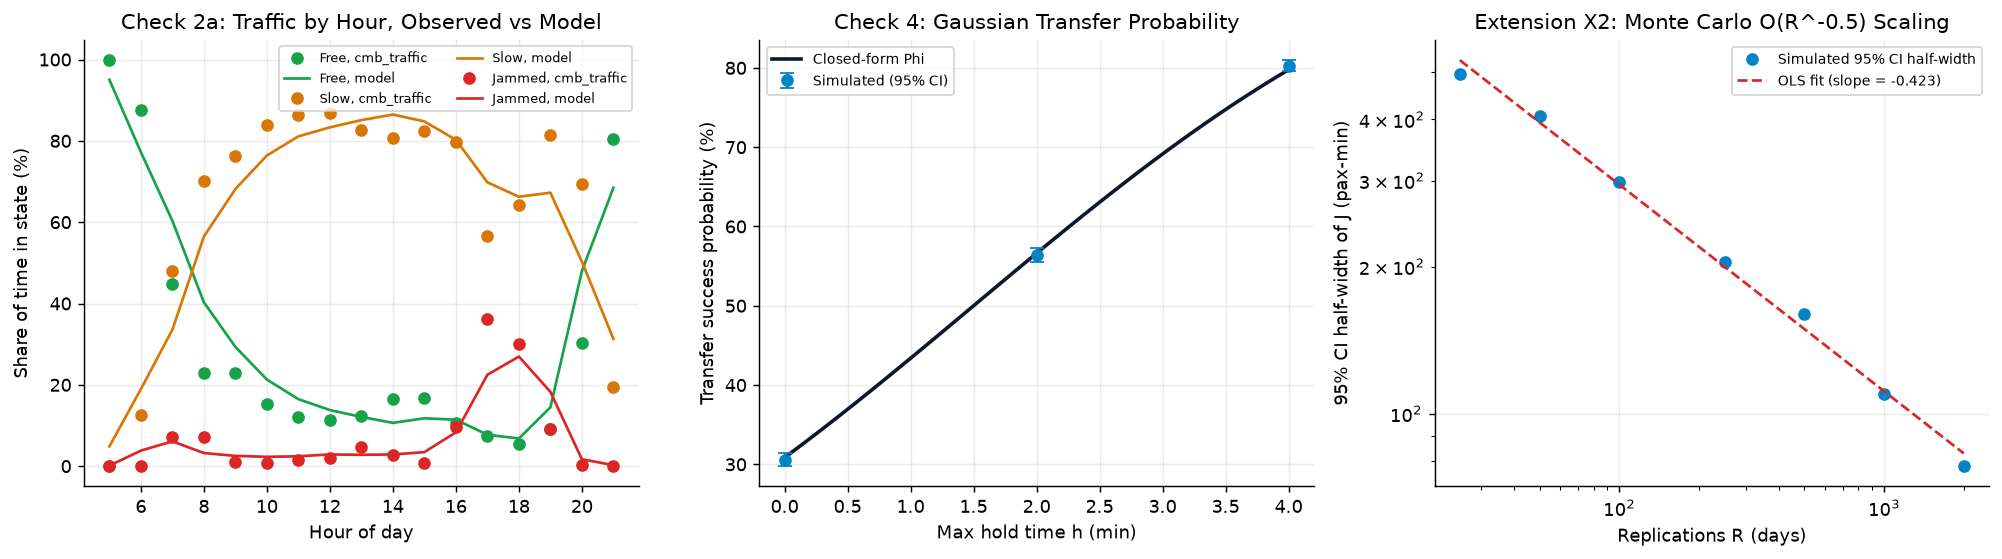

In [8]:
verify_seeds = experiment_seeds("verification", 9)
verify_rng = np.random.default_rng(verify_seeds[0])
N_VERIFY_STEPS = 50_000

# Check 1: the sampler reproduces each band's estimated transition matrix (empirical transition frequencies).
for band, P_mat in TRAFFIC_MATRICES.items():
    states = simulate_markov_chain_loop(P_mat, N_VERIFY_STEPS, verify_rng)
    emp = np.zeros((3, 3))
    np.add.at(emp, (states[:-1], states[1:]), 1)
    n_from = emp.sum(axis=1, keepdims=True)
    visited = n_from[:, 0] > 200
    emp_p = emp[visited] / n_from[visited]
    # Allowed gap per entry: 4 binomial standard errors for the number of visits to that state.
    tol = 4.0 * np.sqrt(P_mat[visited] * (1.0 - P_mat[visited]) / n_from[visited]) + 1e-3
    assert np.all(np.abs(emp_p - P_mat[visited]) <= tol), f"{band}: simulated transitions differ from the estimate"
print(f"PASS [Check 1 - Markov sampler]: simulated transition frequencies match all {len(TRAFFIC_MATRICES)} band matrices within 4 standard errors.")

# Check 2a: simulated daily traffic reproduces the observed traffic by hour (cmb_traffic, service hours).
sim_hour_counts = np.zeros((24, 3))
for _ in range(2000):
    day_states = generate_daily_traffic_grid(verify_rng)
    for slot, state_idx in enumerate(day_states):
        hour = int((DAY_START_MIN + slot * TRAFFIC_STEP_MIN) // 60)
        if hour < 24:
            sim_hour_counts[hour, state_idx] += 1
hours = traffic_hourly_df["hour"].to_numpy()
obs_hour_shares = traffic_hourly_df[["share_free", "share_slow", "share_jammed"]].to_numpy()
sim_hour_shares = sim_hour_counts[hours] / sim_hour_counts[hours].sum(axis=1, keepdims=True)
sim_hour_speed = np.array([sim_hour_shares[k] @ STATE_SPEEDS_BY_BAND[traffic_band(60.0 * h)] for k, h in enumerate(hours)])
obs_hour_speed = traffic_hourly_df["mean_speed_kmph"].to_numpy()
max_share_gap = float(np.max(np.abs(sim_hour_shares - obs_hour_shares)))
max_speed_gap = float(np.max(np.abs(sim_hour_speed - obs_hour_speed) / obs_hour_speed))
worst_hours = hours[np.argsort(-np.abs(sim_hour_speed - obs_hour_speed) / obs_hour_speed)[:2]]
assert max_share_gap < 0.20 and max_speed_gap < 0.12, f"traffic by hour: share gap {max_share_gap:.2f}, speed gap {max_speed_gap:.1%}"
print(f"PASS [Check 2a - traffic by hour]: simulated state shares within {max_share_gap:.2f} and mean speeds within {max_speed_gap:.1%} "
      f"of cmb_traffic for every hour 05:00-22:00; largest speed gaps at {', '.join(f'{h:02d}:00' for h in worst_hours)}")

runtime_check_days = [precompute_day_inputs(s) for s in verify_seeds[1].spawn(80)]
for leg_name in ROUTE_LEGS_CONFIG:
    assert LEG_CAL_REL_ERRORS[leg_name] < 0.02, f"{leg_name} calibration residual {LEG_CAL_REL_ERRORS[leg_name]:.4f} >= 2%"
    sched_rt = float((leg_schedules[leg_name]["borella_sched_min"] - leg_schedules[leg_name]["origin_sched_min"]).mean())
    daily_delays = np.array([np.mean([rec.borella_delay_min for rec in d["leg_records"][leg_name]]) for d in runtime_check_days])
    mean_delay = float(np.mean(daily_delays))
    se_delay = float(np.std(daily_delays, ddof=1) / np.sqrt(len(daily_delays)))
    se_combined = float(np.std(daily_delays, ddof=1) * np.sqrt(1.0 / len(daily_delays) + 1.0 / N_CAL_DAYS))
    rel_rt_err = abs(mean_delay) / sched_rt
    assert abs(mean_delay) <= max(0.02 * sched_rt, 2.58 * se_combined), (
        f"{leg_name} verification runtime delay {mean_delay:.2f}m outside 99% combined CI (2.58*SE_comb={2.58*se_combined:.2f}m)"
    )
    print(f"  Check 2 [{leg_name}]: cal_err={LEG_CAL_REL_ERRORS[leg_name]:.2%}, test_delay={mean_delay:+.2f} +/- {1.96*se_delay:.2f}m (rel={rel_rt_err:.2%}, 99% comb lim={2.58*se_combined:.2f}m)")
print("PASS [Check 2b - leg calibration]: all 4 legs calibrated < 2% and test delays match scheduled runtime within Monte Carlo CI.")

thinning_rng = np.random.default_rng(verify_seeds[6])
thinning_leg_cfg = {"stops": ["S0", "S1"], "base_arrival_rate_pax_per_min": [0.4, 0.0]}
N_THINNING_DAYS = 400
thinning_start_min = DAY_START_MIN
peak_minutes = sum(max(0.0, min(end, DAY_END_MIN) - max(start, thinning_start_min)) for start, end in PEAK_WINDOWS_MIN)
offpeak_minutes = (DAY_END_MIN - thinning_start_min) - peak_minutes
expected_peak = 0.4 * PEAK_ARRIVAL_MULTIPLIER * peak_minutes
expected_offpeak = 0.4 * OFFPEAK_ARRIVAL_MULTIPLIER * offpeak_minutes
peak_counts, offpeak_counts = [], []
for _ in range(N_THINNING_DAYS):
    times = [t for t, _ in generate_stop_arrivals(thinning_leg_cfg, thinning_start_min + PRE_DEPARTURE_ACCUM_MIN, thinning_rng, thinning_rng)[0]]
    n_peak = sum(1 for t in times if is_peak_time(t))
    peak_counts.append(n_peak)
    offpeak_counts.append(len(times) - n_peak)
for label, counts_arr, expected in (("peak", peak_counts, expected_peak), ("off-peak", offpeak_counts, expected_offpeak)):
    mean_count = float(np.mean(counts_arr))
    se_count = math.sqrt(expected / N_THINNING_DAYS)
    assert abs(mean_count - expected) <= 3.0 * se_count, f"Thinning {label} count {mean_count:.1f} vs {expected:.1f}"
    print(f"PASS [Check 9 - NHPP thinning, {label:8s}]: mean daily arrivals {mean_count:.1f} vs integral of lambda(t) {expected:.1f} (3 SE = {3 * se_count:.1f})")

det_feeders_df = pd.DataFrame([{"trip_id": "F1", "borella_arr_min": 500.0}])
det_conns_df = pd.DataFrame([{"trip_id": "C1", "borella_sched_min": 504.0, "borella_base_dep_min": 504.0, "borella_onboard_pax": 20}])
det_res = simulate_direction_transfers(
    det_feeders_df, det_conns_df, {"F1": "C1"}, {"F1": 10}, {"F1": 0.0},
    policy="none", hold_max_min=0.0, walk_time_min=3.5, capacity_pax=None
)
assert det_res["missed_total"] == 0 and det_res["made"] == 10, "Deterministic DES limiting case failed"
assert np.isclose(det_res["mean_wait_min"], 0.5), "Deterministic wait should equal offset - walk time"
print("PASS [Check 3 - zero-variance limit]: offset >= walk_time (uncapped) yields 0 missed transfers (P(miss) = 0.0) and wait = 0.5 min.")


def simulate_isolated_transfer_pairs(feeder_delays_min, connector_delays_min, offset_min, walk_min, policy, hold_max_min):
    n_pairs = len(feeder_delays_min)
    pair_start_min = 1000.0 * np.arange(n_pairs)
    feeder_ids = [f"F{i}" for i in range(n_pairs)]
    connector_ids = [f"C{i}" for i in range(n_pairs)]
    feeders_df = pd.DataFrame({"trip_id": feeder_ids, "borella_arr_min": pair_start_min + feeder_delays_min})
    connectors_df = pd.DataFrame({
        "trip_id": connector_ids,
        "borella_sched_min": pair_start_min + offset_min,
        "borella_base_dep_min": pair_start_min + offset_min + connector_delays_min,
        "borella_onboard_pax": 0,
    })
    res = simulate_direction_transfers(
        feeders_df, connectors_df, dict(zip(feeder_ids, connector_ids)),
        dict.fromkeys(feeder_ids, 1), dict.fromkeys(feeder_ids, 0.0),
        policy=policy, hold_max_min=hold_max_min, walk_time_min=walk_min, capacity_pax=None,
    )
    return res["made"] / n_pairs


gauss_rng = np.random.default_rng(verify_seeds[2])
N_GAUSS = 12_000
gaussian_check_rows = []
offset_min, walk_min = 4.0, 3.5
mu_f, sd_f = 2.0, 3.0
for h_val in (0.0, 2.0, 4.0):
    feeder_delays = np.array([mu_f + sd_f * sample_standard_normal_box_muller(gauss_rng) for _ in range(N_GAUSS)])
    p_sim = simulate_isolated_transfer_pairs(feeder_delays, np.zeros(N_GAUSS), offset_min, walk_min, "schedule", h_val)
    se = math.sqrt(p_sim * (1.0 - p_sim) / N_GAUSS)
    p_analytic = float(norm.cdf((offset_min + h_val - walk_min - mu_f) / sd_f))
    assert abs(p_sim - p_analytic) <= max(2.58 * se, 0.015), f"Gaussian check mismatch at h={h_val}"
    gaussian_check_rows.append({"label": f"One-sided h={h_val:.0f}m", "h": h_val, "p_sim": p_sim, "ci": 1.96 * se, "p_analytic": p_analytic})

mu_f2, sd_f2 = 12.0, 2.0
mu_c2, sd_c2 = 12.0, 2.0
offset_2, walk_2 = 5.0, 3.5
feeder_delays_2 = np.array([mu_f2 + sd_f2 * sample_standard_normal_box_muller(gauss_rng) for _ in range(N_GAUSS)])
connector_delays_2 = np.array([mu_c2 + sd_c2 * sample_standard_normal_box_muller(gauss_rng) for _ in range(N_GAUSS)])
p_sim_2 = simulate_isolated_transfer_pairs(feeder_delays_2, connector_delays_2, offset_2, walk_2, "none", 0.0)
se_2 = math.sqrt(p_sim_2 * (1.0 - p_sim_2) / N_GAUSS)
p_ana_2 = float(norm.cdf((offset_2 - walk_2 - (mu_f2 - mu_c2)) / math.sqrt(sd_f2**2 + sd_c2**2)))
assert abs(p_sim_2 - p_ana_2) <= max(2.58 * se_2, 0.015), "Two-sided Gaussian check mismatch"
gaussian_check_rows.append({"label": "Two-sided h=0m", "h": 0.0, "p_sim": p_sim_2, "ci": 1.96 * se_2, "p_analytic": p_ana_2})
gauss_df = pd.DataFrame(gaussian_check_rows)
print("PASS [Check 4 - Gaussian transfer probability (full event loop)]:")
print(gauss_df.round(4).to_string(index=False))

cons_streams = verify_seeds[3].spawn(3)
cons_traffic = generate_daily_traffic_grid(np.random.default_rng(cons_streams[0]))
cons_leg_df, cons_leg_stats = simulate_leg_day(
    "CM01_MAK_to_FOR",
    sched_cm01_mak,
    ROUTE_LEGS_CONFIG["CM01_MAK_to_FOR"],
    cons_traffic,
    np.random.default_rng(cons_streams[1]),
    np.random.default_rng(cons_streams[2]),
    capacity_pax=CAPACITY_PAX,
    alpha=LEG_ALPHAS["CM01_MAK_to_FOR"],
    return_stats=True,
)
assert cons_leg_stats["total_generated_stop_pax"] == (
    cons_leg_stats["total_boarded_pax"] + cons_leg_stats["end_of_day_unserved_pax"] + cons_leg_stats["abandoned_pax"]
)
assert cons_leg_stats["total_boarded_pax"] == cons_leg_stats["total_alighted_pax"]
assert cons_leg_stats["max_onboard_observed"] <= CAPACITY_PAX

check_day = precompute_day_inputs(verify_seeds[3])
for pol in ("none", "schedule", "realtime"):
    cons_out = evaluate_day(check_day, policy=pol, hold_max_min=3.0)
    for grp in ("A", "B"):
        g = cons_out[grp]
        accounted = g["made"] + g["missed_timing"] + g["missed_capacity"] + g["out_of_window"]
        assert accounted == g["total_generated"], f"Conservation failed for {pol} group {grp}"
        assert g["lost_timing"] <= g["missed_timing"] and g["lost_capacity"] <= g["missed_capacity"]
print("PASS [Check 5 - passenger conservation]: stop queues (boarded + unserved + abandoned) and all transfer outcomes conserved exactly.")

out_none = evaluate_day(check_day, policy="none", hold_max_min=0.0)
out_sched0 = evaluate_day(check_day, policy="schedule", hold_max_min=0.0)
out_rt0 = evaluate_day(check_day, policy="realtime", hold_max_min=0.0)
assert out_none == out_sched0 == out_rt0, "h=0 under schedule/realtime differs from none"
print("PASS [Check 6 - h=0 equivalence]: schedule(h=0) and realtime(h=0) match none identically.")

uncapped_df, uncapped_stats = simulate_leg_day(
    "CM03_KAD_to_MAK",
    sched_cm03_kad,
    ROUTE_LEGS_CONFIG["CM03_KAD_to_MAK"],
    cons_traffic,
    np.random.default_rng(cons_streams[1]),
    np.random.default_rng(cons_streams[2]),
    capacity_pax=None,
    alpha=LEG_ALPHAS["CM03_KAD_to_MAK"],
    return_stats=True,
)
assert uncapped_stats["total_left_behind_events"] == 0
uncapped_day = precompute_day_inputs(verify_seeds[3], capacity_pax=None)
uncapped_out = evaluate_day(uncapped_day, policy="schedule", hold_max_min=3.0, capacity_pax=None)
assert uncapped_out["A"]["missed_capacity"] == 0 and uncapped_out["B"]["missed_capacity"] == 0
print(f"PASS [Check 7 - capacity invariant]: capped max load = {cons_leg_stats['max_onboard_observed']} <= {CAPACITY_PAX}; uncapped produced 0 capacity misses.")

n_crn_test = 80
crn_seeds = verify_seeds[4].spawn(n_crn_test * 2)
paired_diffs, indep_diffs = [], []
for i in range(n_crn_test):
    d_a = precompute_day_inputs(crn_seeds[2 * i])
    d_b = precompute_day_inputs(crn_seeds[2 * i + 1])
    j0_a = evaluate_day(d_a, "none", 0.0)["A"]["total_cost"] + evaluate_day(d_a, "none", 0.0)["B"]["total_cost"]
    j3_a = evaluate_day(d_a, "schedule", 3.0)["A"]["total_cost"] + evaluate_day(d_a, "schedule", 3.0)["B"]["total_cost"]
    j3_b = evaluate_day(d_b, "schedule", 3.0)["A"]["total_cost"] + evaluate_day(d_b, "schedule", 3.0)["B"]["total_cost"]
    paired_diffs.append(j3_a - j0_a)
    indep_diffs.append(j3_b - j0_a)
var_paired = float(np.var(paired_diffs, ddof=1))
var_indep = float(np.var(indep_diffs, ddof=1))
assert var_paired < var_indep, f"CRN failed to reduce variance: {var_paired:.1f} >= {var_indep:.1f}"
print(f"PASS [Check 8 - CRN variance]: paired Var = {var_paired:.1f} < independent Var = {var_indep:.1f} ({100*(1 - var_paired/var_indep):.1f}% reduction).")

# Traffic states change with time, not distance, so a long journey's distance/time converges to the
# time-mean pi . v. The harmonic mean 1 / (pi . 1/v) would apply only to states indexed by distance.
journey_rng = np.random.default_rng(verify_seeds[7])
JOURNEY_TEST_LEG_KM = 20.0
for label, P_mat, pi_star in (("off-peak", P_offpeak, pi_offpeak), ("peak", P_peak, pi_peak)):
    states = simulate_markov_chain_loop(P_mat, 100_000, journey_rng)
    time_mean_kmph = float(np.dot(pi_star, STATE_SPEEDS_KMPH))
    harmonic_kmph = float(1.0 / np.dot(pi_star, 1.0 / STATE_SPEEDS_KMPH))
    long_km = 0.9 * time_mean_kmph * len(states) * TRAFFIC_STEP_MIN / 60.0
    long_speed_kmph = long_km / (travel_segment_minutes(DAY_START_MIN, long_km, states, alpha=1.0, speeds_kmph=STATE_SPEEDS_KMPH) / 60.0)
    starts_min = DAY_START_MIN + TRAFFIC_STEP_MIN * journey_rng.integers(0, len(states) - 2000, 2000)
    leg_time_min = np.mean([travel_segment_minutes(t, JOURNEY_TEST_LEG_KM, states, alpha=1.0, speeds_kmph=STATE_SPEEDS_KMPH) for t in starts_min])
    leg_speed_kmph = JOURNEY_TEST_LEG_KM / (leg_time_min / 60.0)
    assert abs(long_speed_kmph - time_mean_kmph) / time_mean_kmph < 0.005, f"{label} journey speed {long_speed_kmph:.2f} != pi.v"
    assert abs(long_speed_kmph - time_mean_kmph) < abs(long_speed_kmph - harmonic_kmph), f"{label} journey speed closer to the harmonic mean"
    assert harmonic_kmph < leg_speed_kmph <= time_mean_kmph + 0.5
    print(f"PASS [Check 10 - journey speed, {label:8s}]: long-run distance/time = {long_speed_kmph:.2f} km/h vs pi.v = {time_mean_kmph:.2f} "
          f"(harmonic mean {harmonic_kmph:.2f}); {JOURNEY_TEST_LEG_KM:.0f} km journeys average {leg_speed_kmph:.2f} km/h")

# Check 11: with exact ETAs (sigma = 0), real-time holding waits only for feeders that will arrive before the hold
# deadline, so on isolated feeder-connector pairs it makes exactly the same connections as schedule holding while
# never holding longer. On full days it still never holds longer; connection counts can differ slightly there,
# because a held connector can also pick up passengers who were planning to take the next connector.
x3_rng = np.random.default_rng(verify_seeds[8])
for h_val in (3.0, 10.0):
    feeder_delays = 2.0 + 6.0 * x3_rng.standard_normal(4000)
    made_sched = simulate_isolated_transfer_pairs(feeder_delays, np.zeros(4000), 4.0, 3.5, "schedule", h_val)
    made_rt = simulate_isolated_transfer_pairs(feeder_delays, np.zeros(4000), 4.0, 3.5, "realtime", h_val)
    assert made_rt == made_sched, f"Isolated pairs: real-time {made_rt:.4f} vs schedule {made_sched:.4f} at h={h_val}"
x3_days = [precompute_day_inputs(s, eta_noise_sd_min=0.0) for s in verify_seeds[8].spawn(100)]
x3_hold_saved, x3_made_diff = [], []
for d in x3_days:
    for h_val in (3.0, 10.0):
        rt_out = evaluate_day(d, "realtime", h_val)
        sc_out = evaluate_day(d, "schedule", h_val)
        for grp in ("A", "B"):
            assert rt_out[grp]["total_hold_pax_min"] <= sc_out[grp]["total_hold_pax_min"] + 1e-9, "Real-time held longer than schedule"
            x3_hold_saved.append(sc_out[grp]["total_hold_pax_min"] - rt_out[grp]["total_hold_pax_min"])
            x3_made_diff.append(abs(rt_out[grp]["made"] - sc_out[grp]["made"]))
print(f"PASS [Check 11 - X3 exact-ETA limit]: with sigma = 0, real-time holding makes the same connections as schedule holding "
      f"on 8,000 isolated pairs and never holds longer on {len(x3_hold_saved)} day-direction cases "
      f"(mean hold saved {np.mean(x3_hold_saved):.0f} pax-min; full-day connections differ by {np.mean(x3_made_diff):.2f} pax on average).")

# Check 12: every real bus duty alternates terminals and fits the scheduled run times (shifted timetables are
# checked the same way in E3, and shifts the layovers cannot absorb are skipped).
for route, duties in bus_duties(leg_schedules).items():
    for duty in duties:
        assert all(prev[2] == nxt[1] for prev, nxt in zip(duty, duty[1:])), f"{route} duty does not alternate terminals"
        assert min(duty_layovers_min(duty), default=0.0) >= -1e-9, f"{route} bus {duty[0][0]} cannot make its next trip"
print(f"PASS [Check 12 - bus duties]: {BASE_FLEET} buses; every duty alternates terminals with non-negative scheduled layovers.")

# Check 13: the extra-bus duty adds exactly one bus and keeps every turnaround >= the minimum.
extra_by_route = {route: best_extra_bus(leg_schedules, route) for route in ROUTES}
for route, extra in extra_by_route.items():
    duties = bus_duties(leg_schedules, extra)[route]
    extra_duty = [d for d in duties if d[0][0].startswith("X-")]
    assert len(duties) == BASE_FLEET[route] + 1 and len(extra_duty) == 1
    assert min(duty_layovers_min(extra_duty[0])) >= MIN_TURNAROUND_MIN - 1e-9
    print(f"  Check 13 [{route}]: {len(extra_duty[0])} extra trips on 1 extra bus (base {BASE_FLEET[route]}), min turnaround {min(duty_layovers_min(extra_duty[0])):.0f} min")
print("PASS [Check 13 - extra bus]: each extra-bus duty adds one bus with valid turnarounds.")

# Check 14: extra trips on Pettah->Makumbura only cannot change Kadawatha->Pettah transfers (random draws stay aligned).
d_plain = precompute_day_inputs(verify_seeds[3])
d_b_only = precompute_day_inputs(verify_seeds[3], extra_trips={"CM01_FOR_to_MAK": extra_by_route["CM01"]["CM01_FOR_to_MAK"]})
for pol, h_val in (("none", 0.0), ("realtime", 3.0)):
    assert evaluate_day(d_plain, pol, h_val)["A"] == evaluate_day(d_b_only, pol, h_val)["A"], "Extra trips changed an unrelated direction"
print("PASS [Check 14 - isolation]: extra Pettah->Makumbura trips leave Group A results identical.")

# Check 15: adding trips keeps the number of through passengers the same, so scenarios are compared on equal demand.
d_both = precompute_day_inputs(verify_seeds[3], extra_trips={**extra_by_route["CM01"], **extra_by_route["CM03"]})
for grp in ("A", "B"):
    assert evaluate_day(d_plain, "none", 0.0)[grp]["total_generated"] == evaluate_day(d_both, "none", 0.0)[grp]["total_generated"]
print("PASS [Check 15 - fixed demand]: through passengers per day are unchanged when extra trips are added.")

MAX_R_CONV = R_CONV_POOL
conv_seeds = verify_seeds[5].spawn(MAX_R_CONV)
PRECOMPUTED_POOL = [precompute_day_inputs(s) for s in conv_seeds]
pool_j_vals = np.array([evaluate_day(d, "realtime", 3.0)["A"]["total_cost"] + evaluate_day(d, "realtime", 3.0)["B"]["total_cost"] for d in PRECOMPUTED_POOL])
r_grid = np.array([25, 50, 100, 250, 500, 1000, 2000])
ci_halfwidths = np.array([1.96 * np.std(pool_j_vals[:r], ddof=1) / np.sqrt(r) for r in r_grid])
slope_loglog, intercept_loglog = np.polyfit(np.log10(r_grid), np.log10(ci_halfwidths), 1)
assert -0.60 <= slope_loglog <= -0.40, f"Monte Carlo scaling slope {slope_loglog:.3f} far from -0.5"
print(f"PASS [Extension X2 - MC error scaling]: log-log slope = {slope_loglog:.3f} (theoretical -0.500).")

fig, axes = plt.subplots(1, 3, figsize=(15.5, 4.4))

ax1 = axes[0]
for k, (name, color) in enumerate((("Free", "#16a34a"), ("Slow", "#d97706"), ("Jammed", "#dc2626"))):
    ax1.plot(hours, 100.0 * obs_hour_shares[:, k], "o", color=color, label=f"{name}, cmb_traffic")
    ax1.plot(hours, 100.0 * sim_hour_shares[:, k], "-", color=color, label=f"{name}, model")
ax1.set_xlabel("Hour of day")
ax1.set_ylabel("Share of time in state (%)")
ax1.set_title("Check 2a: Traffic by Hour, Observed vs Model")
ax1.legend(fontsize=7, ncol=2)

ax2 = axes[1]
one_sided = gauss_df[gauss_df["label"].str.startswith("One-sided")]
h_dense = np.linspace(0.0, 4.0, 80)
p_dense = norm.cdf((4.0 + h_dense - 3.5 - 2.0) / 3.0)
ax2.plot(h_dense, 100.0 * p_dense, color="#0f172a", linewidth=2, label="Closed-form Phi")
ax2.errorbar(one_sided["h"], 100.0 * one_sided["p_sim"], yerr=100.0 * one_sided["ci"], fmt="o", color="#0284c7", capsize=4, label="Simulated (95% CI)")
ax2.set_xlabel("Max hold time h (min)")
ax2.set_ylabel("Transfer success probability (%)")
ax2.set_title("Check 4: Gaussian Transfer Probability")
ax2.legend(fontsize=8)

ax3 = axes[2]
ax3.loglog(r_grid, ci_halfwidths, "o", color="#0284c7", label="Simulated 95% CI half-width")
ax3.loglog(r_grid, 10**(intercept_loglog + slope_loglog * np.log10(r_grid)), "--", color="#dc2626", label=f"OLS fit (slope = {slope_loglog:.3f})")
ax3.set_xlabel("Replications R (days)")
ax3.set_ylabel("95% CI half-width of J (pax-min)")
ax3.set_title("Extension X2: Monte Carlo O(R^-0.5) Scaling")
ax3.legend(fontsize=8)

plt.tight_layout()
fig.savefig(FIGURES_DIR / "verification.png", bbox_inches="tight")
plt.show()

## 5. Experiments and results

*Provenance: AI-generated then modified.*

We conduct the following experiments using common random numbers across identical simulated days [1]. All run sizes $R$ are set in one block in the setup cell. Each experiment draws its seeds from its own named stream (`experiment_seeds`), so re-running one cell does not change any other experiment's results:

- **E1 (Baseline diagnosis, $R = 1000$):** Quantify missed timing vs missed capacity rates, mean transfer wait times, and objective cost $J(0, 0)$ on the published timetable without holding.
- **E2 (Holding sweep, $h \in [0, 10]\text{ min}$, $R = 400$):** Compare `schedule` vs `realtime` holding at the current timetable ($\Delta = 0$). The sweep goes beyond the 5-min cap used for the recommendation to show what longer holds would give.
- **E3 (Timetable shift and joint optimization, $\Delta \in [-10, +10]\text{ min}$, $R = 200$):** Shift the connecting direction of each group (CM01 towards Pettah for Group A, CM03 towards Kadawatha for Group B) jointly with real-time holding $h \in [0, 5]\text{ min}$; shifts the real bus layovers cannot absorb are skipped. The recommended policy is the simplest one (smallest total shift, then the shortest hold) that is not significantly worse than the best grid policy in a paired day-by-day test of $J$.
- **E4 (Stretch goal X3 - ETA prediction noise, $R = 250$):** Test how real-time ETA holding performs against schedule-based holding as GPS prediction error $\sigma_{\text{eta}}$ grows from $0$ to $4\text{ min}$.
- **E6 (Ticket validity, $R = 150$):** With patience and validity limits removed, how long each through-ticket passenger would have to wait at Borella to board, compared with the proposed 2-hour validity. Removing the limits keeps the result from being decided by the rule being tested.
- **Operating assumption ($R = 150$):** Repeat the baseline and the recommended policy with early-running connectors waiting at Borella for their timetable time (a Borella timing point). Metro buses do not do this today.
- **E7 (Current fleet vs one extra bus, $R = 500$):** Compare the baseline, the recommended policy, the same with a Borella timing point, one extra CM01 or CM03 bus, and the timing-point policy plus the better extra bus. Report missed connections, the share of through passengers served by Metro, $J$, and the share of late terminal turnarounds, then print the recommended fixed timetable for the current fleet.
- **E5 & Extensions X5/X6:** Isolate the capacity bottleneck ($C=80$ vs $C=\infty$), run a multi-parameter sensitivity tornado on missed transfers and cost per passenger with 95% CIs plus a 2D grid analysis, and benchmark vectorized vs loop Markov traffic generation.

=== E1: Current Timetable Baseline Diagnosis (R = 1000 CRN days, 95% CI) ===
    Miss A (%)     Miss B (%)  Through pax/day  Missed pax/day   Miss All (%)  Timing Miss (%)  Cap Miss (%)       Lost (%)  Wait p95 (min) Mean Wait (min)       J (pax-min)
18.35 +/- 0.96 18.13 +/- 0.44            289.7            51.1 18.24 +/- 0.49            11.04           7.2 14.63 +/- 0.39            40.6  22.00 +/- 0.19 16306.4 +/- 125.4



=== E2: Borella Holding Sweep at Current Timetable (R = 400 CRN days) ===
 h_min  sched_miss_A  sched_miss_B  sched_miss_all  sched_hold_cost  sched_J  rt_miss_all  rt_hold_cost     rt_J
   0.0         17.64         18.29           18.01             0.00 16330.10        18.01          0.00 16330.10
   0.5         16.61         17.87           17.32           110.82 16213.21        17.63          9.18 16210.70
   1.0         15.50         17.45           16.59           213.23 16083.87        17.09         24.14 16050.51
   1.5         14.12         17.08           15.77           306.94 15910.31        16.42         42.75 15849.63
   2.0         12.66         16.83           14.97           391.97 15739.60        15.69         64.22 15635.38
   2.5         11.77         16.60           14.45           469.81 15651.29        15.08         89.68 15464.08
   3.0         10.99         16.32           13.95           542.52 15576.15        14.56        115.79 15326.12
   3.5         10.47 

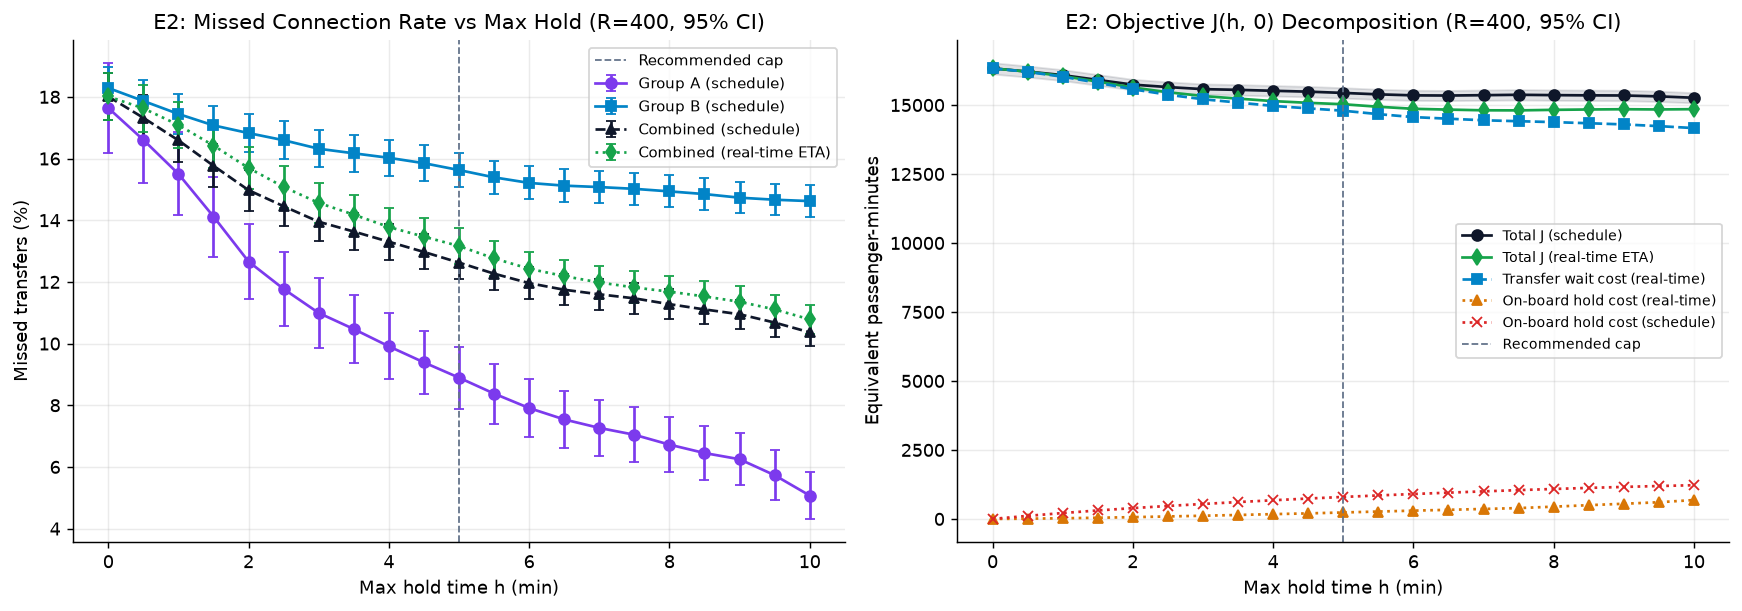

In [9]:
def summarize_ci(values):
    # Mean and normal-approximation 95% CI half-width over replications.
    arr = np.asarray(values, dtype=float)
    mean_val = float(np.mean(arr))
    ci_half = 1.96 * float(np.std(arr, ddof=1)) / np.sqrt(len(arr))
    return mean_val, ci_half


def evaluate_policy_over_days(days_pool, policy, hold_max_min, walk_time_min=WALK_TIME_MIN, capacity_pax=CAPACITY_PAX, wait_weight=WAIT_WEIGHT, hold_weight=HOLD_WEIGHT, ticket_validity_min=TICKET_VALIDITY_MIN):
    miss_a, miss_b, miss_all = [], [], []
    lost_all, boarded_waits = [], []
    miss_timing_all, miss_cap_all = [], []
    wait_min_all, j_all, wait_cost_all, hold_cost_all = [], [], [], []
    j_per_pax_all = []
    served_all = []
    pax_day, missed_day, lost_day = [], [], []

    for day_in in days_pool:
        res = evaluate_day(
            day_in,
            policy=policy,
            hold_max_min=hold_max_min,
            walk_time_min=walk_time_min,
            capacity_pax=capacity_pax,
            wait_weight=wait_weight,
            hold_weight=hold_weight,
            ticket_validity_min=ticket_validity_min,
        )
        a_in = max(1, res["A"]["in_window_total"])
        b_in = max(1, res["B"]["in_window_total"])
        tot_in = max(1, res["A"]["in_window_total"] + res["B"]["in_window_total"])

        miss_a.append(100.0 * res["A"]["missed_total"] / a_in)
        miss_b.append(100.0 * res["B"]["missed_total"] / b_in)
        miss_timing_all.append(100.0 * (res["A"]["missed_timing"] + res["B"]["missed_timing"]) / tot_in)
        miss_cap_all.append(100.0 * (res["A"]["missed_capacity"] + res["B"]["missed_capacity"]) / tot_in)
        miss_all.append(100.0 * (res["A"]["missed_total"] + res["B"]["missed_total"]) / tot_in)
        wait_min_all.append((res["A"]["total_wait_min"] + res["B"]["total_wait_min"]) / tot_in)
        wait_cost_all.append(res["A"]["wait_cost"] + res["B"]["wait_cost"])
        hold_cost_all.append(res["A"]["hold_cost"] + res["B"]["hold_cost"])
        j_all.append(res["A"]["total_cost"] + res["B"]["total_cost"])
        j_per_pax_all.append((res["A"]["total_cost"] + res["B"]["total_cost"]) / max(1, res["A"]["total_generated"] + res["B"]["total_generated"]))
        lost_all.append(100.0 * (res["A"]["lost_total"] + res["B"]["lost_total"]) / tot_in)
        # Served = boarded a Metro connector (first or later bus), out of all through passengers that day.
        boarded = sum(res[g]["made"] + res[g]["missed_total"] - res[g]["lost_total"] for g in ("A", "B"))
        served_all.append(100.0 * boarded / max(1, res["A"]["total_generated"] + res["B"]["total_generated"]))
        # Daily counts (pax/day); they scale with the assumed transfer demand, the percentages do not.
        pax_day.append(res["A"]["total_generated"] + res["B"]["total_generated"])
        missed_day.append(res["A"]["missed_total"] + res["B"]["missed_total"])
        lost_day.append(res["A"]["lost_total"] + res["B"]["lost_total"])
        boarded_waits.extend(res["A"]["boarded_wait_mins"])
        boarded_waits.extend(res["B"]["boarded_wait_mins"])

    ma_m, ma_ci = summarize_ci(miss_a)
    mb_m, mb_ci = summarize_ci(miss_b)
    mall_m, mall_ci = summarize_ci(miss_all)
    mt_m, _ = summarize_ci(miss_timing_all)
    mc_m, _ = summarize_ci(miss_cap_all)
    wm_m, wm_ci = summarize_ci(wait_min_all)
    wc_m, _ = summarize_ci(wait_cost_all)
    hc_m, _ = summarize_ci(hold_cost_all)
    j_m, j_ci = summarize_ci(j_all)
    jpp_m, jpp_ci = summarize_ci(j_per_pax_all)
    lost_m, lost_ci = summarize_ci(lost_all)
    served_m, served_ci = summarize_ci(served_all)
    waits_arr = np.asarray(boarded_waits, dtype=float)
    return {
        "miss_A_pct": ma_m, "miss_A_ci": ma_ci,
        "miss_B_pct": mb_m, "miss_B_ci": mb_ci,
        "miss_all_pct": mall_m, "miss_all_ci": mall_ci,
        "miss_timing_pct": mt_m, "miss_cap_pct": mc_m,
        "mean_wait_min": wm_m, "mean_wait_ci": wm_ci,
        "wait_cost": wc_m, "hold_cost": hc_m,
        "J_mean": j_m, "J_ci": j_ci,
        "J_per_pax": jpp_m, "J_per_pax_ci": jpp_ci,
        "lost_pct": lost_m, "lost_ci": lost_ci,
        "served_pct": served_m, "served_ci": served_ci,
        "pax_per_day": float(np.mean(pax_day)), "missed_per_day": float(np.mean(missed_day)), "lost_per_day": float(np.mean(lost_day)),
        "wait_p95_min": float(np.percentile(waits_arr, 95)) if waits_arr.size else float("nan"),
        "boarded_waits": waits_arr,
    }


FINAL_POOL = PRECOMPUTED_POOL[:R_FINAL]
base_summary = evaluate_policy_over_days(FINAL_POOL, "none", 0.0)

print(f"=== E1: Current Timetable Baseline Diagnosis (R = {R_FINAL} CRN days, 95% CI) ===")
e1_table = pd.DataFrame([{
    "Miss A (%)": f"{base_summary['miss_A_pct']:.2f} +/- {base_summary['miss_A_ci']:.2f}",
    "Miss B (%)": f"{base_summary['miss_B_pct']:.2f} +/- {base_summary['miss_B_ci']:.2f}",
    "Through pax/day": round(base_summary["pax_per_day"], 1),
    "Missed pax/day": round(base_summary["missed_per_day"], 1),
    "Miss All (%)": f"{base_summary['miss_all_pct']:.2f} +/- {base_summary['miss_all_ci']:.2f}",
    "Timing Miss (%)": round(base_summary["miss_timing_pct"], 2),
    "Cap Miss (%)": round(base_summary["miss_cap_pct"], 2),
    "Lost (%)": f"{base_summary['lost_pct']:.2f} +/- {base_summary['lost_ci']:.2f}",
    "Wait p95 (min)": round(base_summary["wait_p95_min"], 1),
    "Mean Wait (min)": f"{base_summary['mean_wait_min']:.2f} +/- {base_summary['mean_wait_ci']:.2f}",
    "J (pax-min)": f"{base_summary['J_mean']:.1f} +/- {base_summary['J_ci']:.1f}",
}])
print(e1_table.to_string(index=False))

SWEEP_POOL = PRECOMPUTED_POOL[:R_SWEEP]
HOLD_GRID_MIN = np.arange(0.0, HOLD_SWEEP_MAX_MIN + 0.25, 0.5)

e2_rows = []
for h_val in HOLD_GRID_MIN:
    pol_s = "none" if h_val == 0.0 else "schedule"
    pol_r = "none" if h_val == 0.0 else "realtime"
    s_res = evaluate_policy_over_days(SWEEP_POOL, pol_s, float(h_val))
    r_res = evaluate_policy_over_days(SWEEP_POOL, pol_r, float(h_val))
    e2_rows.append({
        "h_min": float(h_val),
        "sched_miss_A": s_res["miss_A_pct"], "sched_miss_A_ci": s_res["miss_A_ci"],
        "sched_miss_B": s_res["miss_B_pct"], "sched_miss_B_ci": s_res["miss_B_ci"],
        "sched_miss_all": s_res["miss_all_pct"], "sched_miss_all_ci": s_res["miss_all_ci"],
        "sched_wait_cost": s_res["wait_cost"], "sched_hold_cost": s_res["hold_cost"],
        "sched_J": s_res["J_mean"], "sched_J_ci": s_res["J_ci"],
        "rt_miss_all": r_res["miss_all_pct"], "rt_miss_all_ci": r_res["miss_all_ci"],
        "rt_wait_cost": r_res["wait_cost"], "rt_hold_cost": r_res["hold_cost"],
        "rt_J": r_res["J_mean"], "rt_J_ci": r_res["J_ci"],
    })

e2_df = pd.DataFrame(e2_rows)
print(f"\n=== E2: Borella Holding Sweep at Current Timetable (R = {R_SWEEP} CRN days) ===")
print(e2_df[["h_min", "sched_miss_A", "sched_miss_B", "sched_miss_all", "sched_hold_cost", "sched_J", "rt_miss_all", "rt_hold_cost", "rt_J"]].round(2).to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.8))

ax1 = axes[0]
ax1.errorbar(e2_df["h_min"], e2_df["sched_miss_A"], yerr=e2_df["sched_miss_A_ci"], marker="o", capsize=3, color="#7c3aed", label="Group A (schedule)")
ax1.errorbar(e2_df["h_min"], e2_df["sched_miss_B"], yerr=e2_df["sched_miss_B_ci"], marker="s", capsize=3, color="#0284c7", label="Group B (schedule)")
ax1.errorbar(e2_df["h_min"], e2_df["sched_miss_all"], yerr=e2_df["sched_miss_all_ci"], marker="^", linestyle="--", capsize=3, color="#0f172a", label="Combined (schedule)")
ax1.errorbar(e2_df["h_min"], e2_df["rt_miss_all"], yerr=e2_df["rt_miss_all_ci"], marker="d", linestyle=":", capsize=3, color="#16a34a", label="Combined (real-time ETA)")
ax1.axvline(MAX_HOLD_MIN, color="#64748b", linestyle="--", linewidth=1, label="Recommended cap")
ax1.set_xlabel("Max hold time h (min)")
ax1.set_ylabel("Missed transfers (%)")
ax1.set_title(f"E2: Missed Connection Rate vs Max Hold (R={R_SWEEP}, 95% CI)")
ax1.legend(fontsize=8.5)

ax2 = axes[1]
ax2.plot(e2_df["h_min"], e2_df["sched_J"], marker="o", color="#0f172a", label="Total J (schedule)")
ax2.fill_between(e2_df["h_min"], e2_df["sched_J"] - e2_df["sched_J_ci"], e2_df["sched_J"] + e2_df["sched_J_ci"], color="#0f172a", alpha=0.12)
ax2.plot(e2_df["h_min"], e2_df["rt_J"], marker="d", color="#16a34a", label="Total J (real-time ETA)")
ax2.plot(e2_df["h_min"], e2_df["rt_wait_cost"], marker="s", linestyle="--", color="#0284c7", label="Transfer wait cost (real-time)")
ax2.plot(e2_df["h_min"], e2_df["rt_hold_cost"], marker="^", linestyle=":", color="#d97706", label="On-board hold cost (real-time)")
ax2.plot(e2_df["h_min"], e2_df["sched_hold_cost"], marker="x", linestyle=":", color="#dc2626", label="On-board hold cost (schedule)")
ax2.axvline(MAX_HOLD_MIN, color="#64748b", linestyle="--", linewidth=1, label="Recommended cap")
ax2.set_xlabel("Max hold time h (min)")
ax2.set_ylabel("Equivalent passenger-minutes")
ax2.set_title(f"E2: Objective J(h, 0) Decomposition (R={R_SWEEP}, 95% CI)")
ax2.legend(fontsize=8)

plt.tight_layout()
fig.savefig(FIGURES_DIR / "holding_sweep.png", bbox_inches="tight")
plt.show()

Feasible connector shifts (min): Group A [-10.0, -5.0, 0.0, 5.0, 10.0], Group B [0.0, 5.0, 10.0]
Best grid policy: current timetable, realtime h=5m, J = 14978 +/- 238, missed 13.3%
Best shift alone: CM01 to Pettah +5m, CM03 to Kadawatha +5m, J = 16103, missed 14.6%
Recommended (simplest not significantly worse than the best, paired test): current timetable, realtime h=5m, J = 14978, missed 13.3%

=== E3: Top 8 policies (connector shifts x real-time hold, R = 200) ===
 delta_A_min  delta_B_min  h_min  miss_A_pct  miss_B_pct  miss_all_pct   J_mean   J_ci
         0.0          0.0    5.0        9.69       16.17         13.26 14977.78 237.91
        -5.0          0.0    5.0       15.81       16.17         16.00 14997.92 269.68
         0.0          5.0    5.0        9.69       12.91         11.46 15079.81 247.68
        -5.0          5.0    5.0       15.81       12.91         14.20 15099.96 281.22
         0.0          0.0    4.0       10.77       16.51         13.94 15103.37 244.48
      

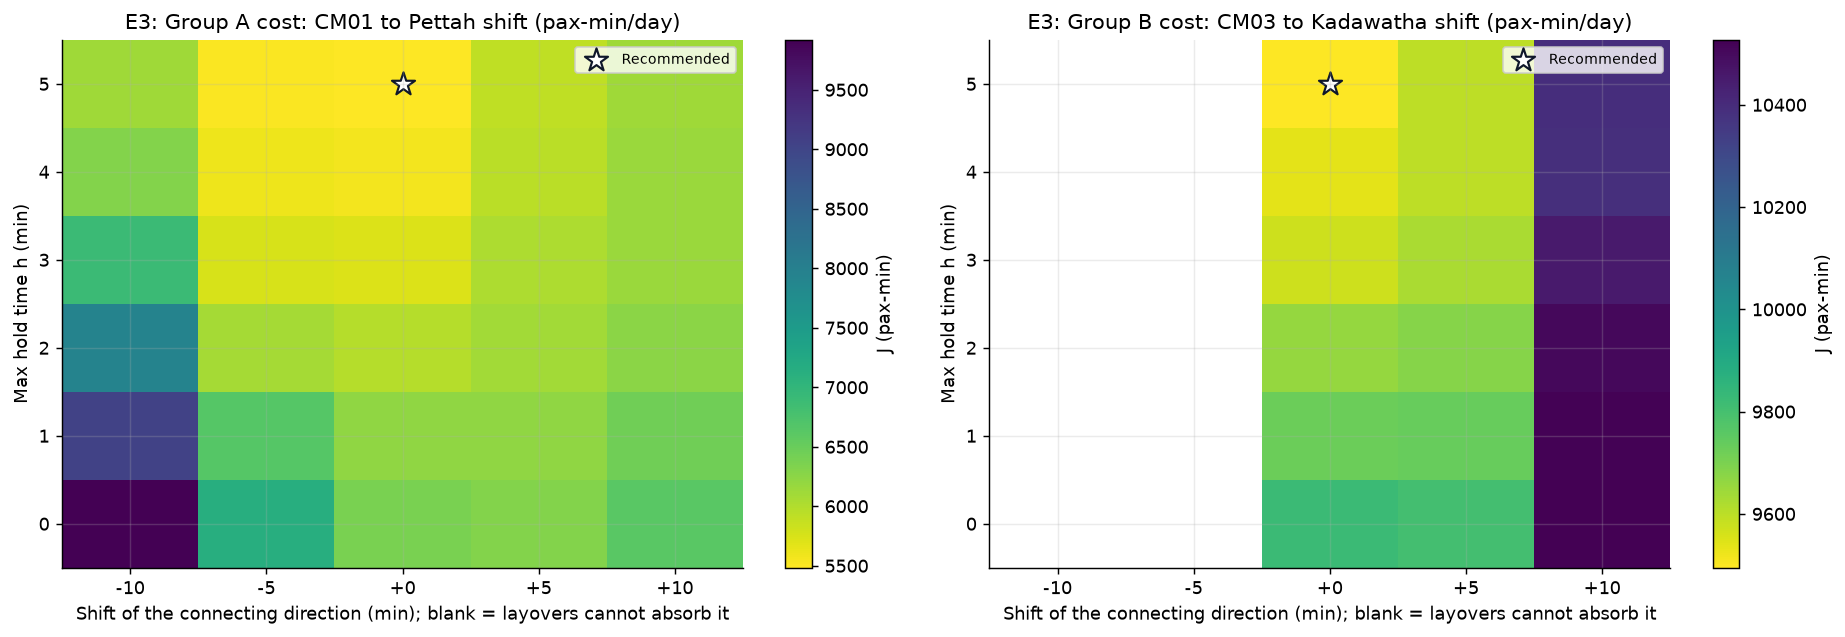


=== E4: Real-Time ETA Holding vs Schedule Holding at the recommended policy (current timetable, h=5.0m, R=250) ===
           policy_mode  eta_noise_sd_min  miss_all_pct  hold_cost_pax_min   J_mean   J_ci
schedule (no ETA skip)               0.0         12.89             862.52 15734.29 250.33
  realtime ETA holding               0.0         13.17             249.44 15198.20 221.99
  realtime ETA holding               1.0         13.42             240.11 15266.47 223.40
  realtime ETA holding               2.0         13.70             241.40 15356.13 224.09
  realtime ETA holding               4.0         14.36             262.72 15586.86 229.87



=== Consolidated Policy Comparison (R = 1000 CRN days, 95% CI) ===
                                                    Scenario     Miss A (%)     Miss B (%)   Miss All (%)  Missed pax/day       Lost (%)  Lost pax/day Mean Wait (min)  Wait p95 (min)  Hold Cost       J (pax-min)
                                    Baseline (current, none) 18.23 +/- 0.94 18.05 +/- 0.45 18.16 +/- 0.48            51.1 14.58 +/- 0.39          41.0  22.03 +/- 0.19            40.5        0.0 16405.9 +/- 124.0
                                  Hold only (schedule, h=5m)  9.40 +/- 0.69 15.35 +/- 0.37 12.71 +/- 0.37            35.8  9.51 +/- 0.27          26.8  19.01 +/- 0.15            39.4      828.2 15540.6 +/- 119.4
                                  Hold only (realtime, h=5m)  9.85 +/- 0.70 15.84 +/- 0.38 13.19 +/- 0.38            37.1 10.06 +/- 0.29          28.3  19.23 +/- 0.15            39.6      240.4 15076.7 +/- 105.9
Best shift alone (CM01 to Pettah +5m, CM03 to Kadawatha +5m) 14.79 +/- 0.71 14.73 +/

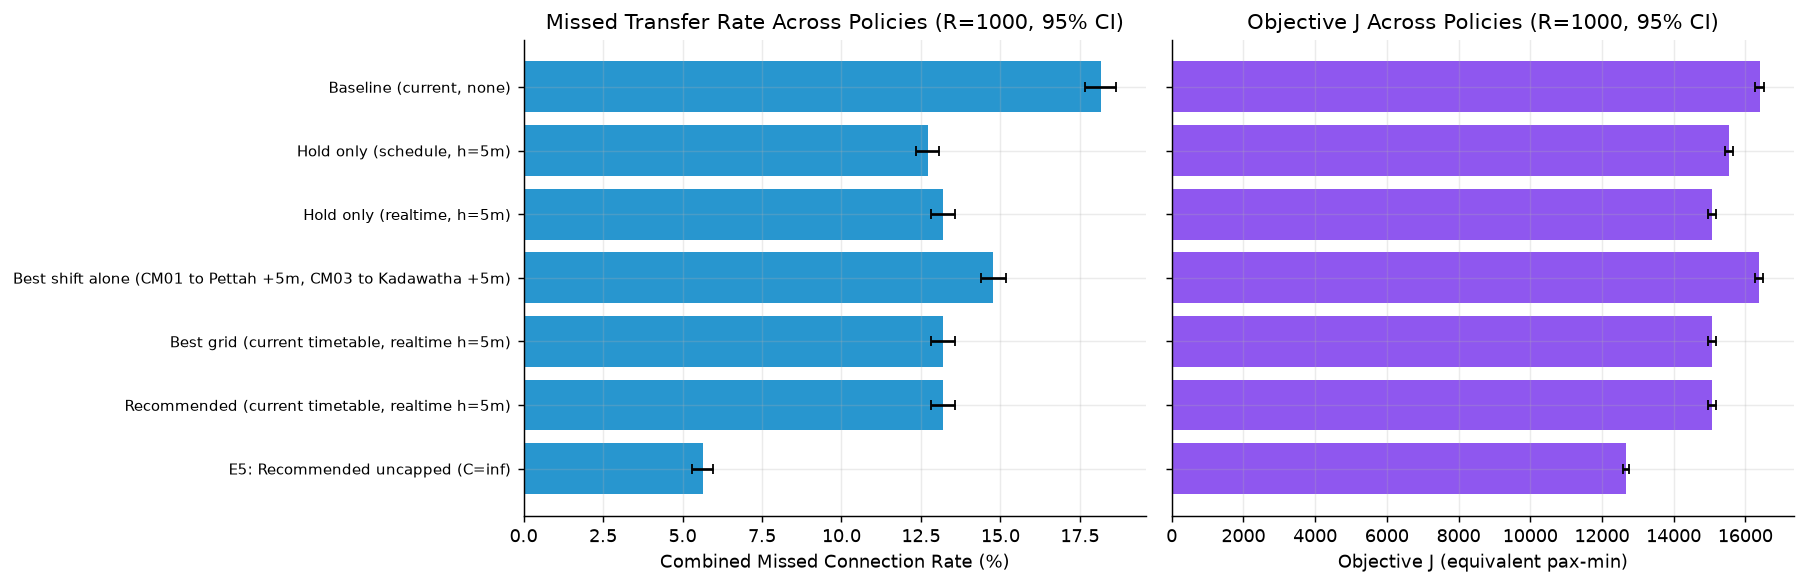

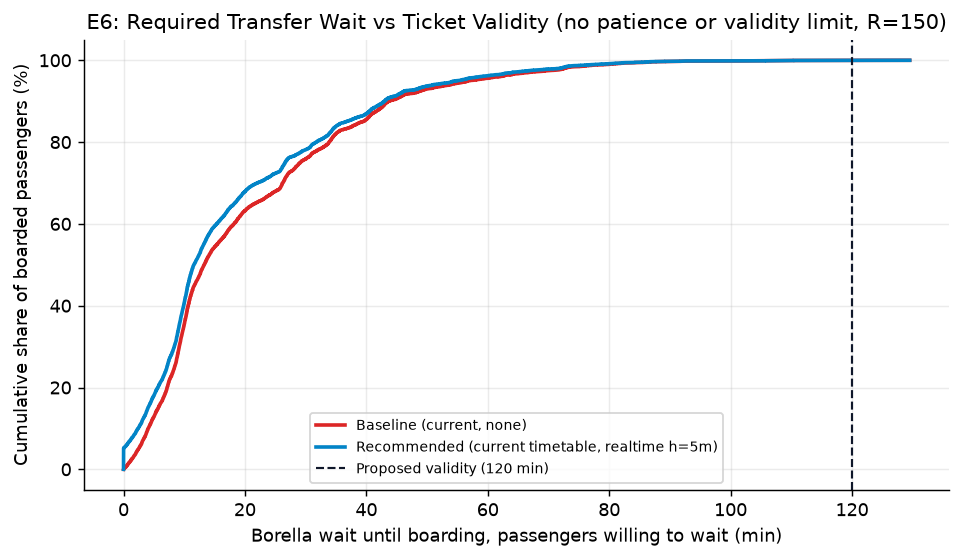


=== E6: Wait Each Through-Ticket Passenger Would Need, With No Patience or Validity Limit (R = 150) ===
                                      Scenario  Median wait (min)  p90 wait (min)  p95 wait (min)  Max wait (min)  Boarded within 120 min (%) No later bus that day (%)
                      Baseline (current, none)               13.3            43.7            57.0           129.5                       99.99             0.55 +/- 0.14
Recommended (current timetable, realtime h=5m)               11.6            43.0            54.8           129.5                       99.99             0.36 +/- 0.12



=== Operating assumption: do early-running connectors wait at Borella for their timetable time? (R = 150) ===
                                      Scenario Early connectors wait for timetable   Miss All (%)  Miss A (%)  Miss B (%)       J (pax-min)
                      Baseline (current, none)                     no (main model) 19.76 +/- 1.27       20.52       19.05 16770.1 +/- 314.0
                      Baseline (current, none)                                 yes 14.01 +/- 0.93       12.39       15.28 21791.7 +/- 416.3
Recommended (current timetable, realtime h=5m)                     no (main model) 14.43 +/- 0.99       11.63       16.64 15332.4 +/- 264.8
Recommended (current timetable, realtime h=5m)                                 yes 10.12 +/- 0.71        5.38       13.93 21031.7 +/- 397.4


In [10]:
SHIFT_VALUES_MIN = np.arange(-MAX_SHIFT_MIN, MAX_SHIFT_MIN + 2.5, 5.0)
HOLD_GRID_COARSE_MIN = np.arange(0.0, MAX_HOLD_MIN + 0.5, 1.0)
GROUPS = ("A", "B")
grid_seeds = experiment_seeds("e3_grid", R_GRID)


def duties_feasible(scheds):
    # Every bus must still be able to make its next trip (non-negative scheduled layover).
    return all(min(duty_layovers_min(d), default=0.0) >= -1e-9 for duties in bus_duties(scheds).values() for d in duties)


# Each connecting direction serves one group only (CM01 towards Pettah: Group A; CM03 towards Kadawatha: Group B),
# so shifting both connectors by the same delta and reading each group separately covers every (delta_A, delta_B)
# pair with one set of simulated days per delta.
feasible = {"A": [], "B": []}
group_daily = {}  # (group, delta, h) -> per-day arrays of J, missed, in-window passengers
for delta in SHIFT_VALUES_MIN:
    delta = float(delta)
    if duties_feasible(shifted_schedules(shift_a_min=delta)):
        feasible["A"].append(delta)
    if duties_feasible(shifted_schedules(shift_b_min=delta)):
        feasible["B"].append(delta)
    days_delta = [precompute_day_inputs(s, shift_a_min=delta, shift_b_min=delta) for s in grid_seeds]
    for h_val in HOLD_GRID_COARSE_MIN:
        pol = "none" if h_val == 0.0 else "realtime"
        results = [evaluate_day(d, pol, float(h_val)) for d in days_delta]
        for grp in GROUPS:
            group_daily[(grp, delta, float(h_val))] = {
                key: np.array([r[grp][field] for r in results], dtype=float)
                for key, field in (("J", "total_cost"), ("missed", "missed_total"), ("in_window", "in_window_total"))
            }

grid_records, combo_days = [], {}
for h_val in HOLD_GRID_COARSE_MIN:
    h_val = float(h_val)
    for d_a in feasible["A"]:
        for d_b in feasible["B"]:
            ga, gb = group_daily[("A", d_a, h_val)], group_daily[("B", d_b, h_val)]
            j_days = ga["J"] + gb["J"]
            miss_days = 100.0 * (ga["missed"] + gb["missed"]) / np.maximum(1, ga["in_window"] + gb["in_window"])
            combo_days[(d_a, d_b, h_val)] = j_days
            grid_records.append({
                "delta_A_min": d_a, "delta_B_min": d_b, "h_min": h_val,
                "miss_A_pct": float(np.mean(100.0 * ga["missed"] / np.maximum(1, ga["in_window"]))),
                "miss_B_pct": float(np.mean(100.0 * gb["missed"] / np.maximum(1, gb["in_window"]))),
                "miss_all_pct": float(np.mean(miss_days)),
                "J_mean": float(np.mean(j_days)), "J_ci": 1.96 * float(np.std(j_days, ddof=1)) / np.sqrt(len(j_days)),
            })
grid_df = pd.DataFrame(grid_records)
best_row = grid_df.loc[grid_df["J_mean"].idxmin()]
best_key = (best_row["delta_A_min"], best_row["delta_B_min"], best_row["h_min"])
shift_only_row = grid_df[grid_df["h_min"] == 0.0].sort_values("J_mean").iloc[0]
# Recommended policy: the simplest one (smallest total shift, then shortest hold) that is not significantly worse
# than the best grid policy. The test uses the paired day-by-day difference in J (all policies share the same days).
def not_worse_than_best(row):
    diff = combo_days[(row["delta_A_min"], row["delta_B_min"], row["h_min"])] - combo_days[best_key]
    return float(np.mean(diff)) <= 1.96 * float(np.std(diff, ddof=1)) / np.sqrt(len(diff)) + 1e-9
within = grid_df[grid_df.apply(not_worse_than_best, axis=1)].copy()
within["total_shift"] = within["delta_A_min"].abs() + within["delta_B_min"].abs()
rec_row = within.sort_values(["total_shift", "h_min", "J_mean"]).iloc[0]
OPT_DELTA_A_MIN, OPT_DELTA_B_MIN, OPT_H_MIN = float(rec_row["delta_A_min"]), float(rec_row["delta_B_min"]), float(rec_row["h_min"])
opt_shift_kw = {"shift_a_min": OPT_DELTA_A_MIN, "shift_b_min": OPT_DELTA_B_MIN}


def shift_label(d_a, d_b):
    return "current timetable" if d_a == 0 and d_b == 0 else f"CM01 to Pettah {d_a:+.0f}m, CM03 to Kadawatha {d_b:+.0f}m"


REC_LABEL = shift_label(OPT_DELTA_A_MIN, OPT_DELTA_B_MIN)
print(f"Feasible connector shifts (min): Group A {feasible['A']}, Group B {feasible['B']}")
print(f"Best grid policy: {shift_label(best_row['delta_A_min'], best_row['delta_B_min'])}, realtime h={best_row['h_min']:.0f}m, J = {best_row['J_mean']:.0f} +/- {best_row['J_ci']:.0f}, missed {best_row['miss_all_pct']:.1f}%")
print(f"Best shift alone: {shift_label(shift_only_row['delta_A_min'], shift_only_row['delta_B_min'])}, J = {shift_only_row['J_mean']:.0f}, missed {shift_only_row['miss_all_pct']:.1f}%")
print(f"Recommended (simplest not significantly worse than the best, paired test): {REC_LABEL}, realtime h={OPT_H_MIN:.0f}m, J = {rec_row['J_mean']:.0f}, missed {rec_row['miss_all_pct']:.1f}%")
print(f"\n=== E3: Top 8 policies (connector shifts x real-time hold, R = {R_GRID}) ===")
print(grid_df.sort_values("J_mean").head(8).round(2).to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(14.5, 5.0))
for ax, grp, rec_delta, title in ((axes[0], "A", OPT_DELTA_A_MIN, "Group A cost: CM01 to Pettah shift"),
                                  (axes[1], "B", OPT_DELTA_B_MIN, "Group B cost: CM03 to Kadawatha shift")):
    j_grid = np.full((len(HOLD_GRID_COARSE_MIN), len(SHIFT_VALUES_MIN)), np.nan)
    for r_idx, h_val in enumerate(HOLD_GRID_COARSE_MIN):
        for c_idx, delta in enumerate(SHIFT_VALUES_MIN):
            if float(delta) in feasible[grp]:
                j_grid[r_idx, c_idx] = group_daily[(grp, float(delta), float(h_val))]["J"].mean()
    im = ax.imshow(j_grid, aspect="auto", origin="lower", cmap="viridis_r")
    ax.set_xticks(range(len(SHIFT_VALUES_MIN)))
    ax.set_xticklabels([f"{int(d):+d}" for d in SHIFT_VALUES_MIN])
    ax.set_yticks(range(len(HOLD_GRID_COARSE_MIN)))
    ax.set_yticklabels([f"{h:.0f}" for h in HOLD_GRID_COARSE_MIN])
    ax.set_xlabel("Shift of the connecting direction (min); blank = layovers cannot absorb it")
    ax.set_ylabel("Max hold time h (min)")
    ax.set_title(f"E3: {title} (pax-min/day)")
    ax.scatter([int(np.where(SHIFT_VALUES_MIN == rec_delta)[0][0])], [int(np.where(HOLD_GRID_COARSE_MIN == OPT_H_MIN)[0][0])],
               marker="*", s=180, color="#ffffff", edgecolor="#0f172a", linewidth=1.2, label="Recommended")
    ax.legend(loc="upper right", fontsize=8)
    plt.colorbar(im, ax=ax, label="J (pax-min)")
plt.tight_layout()
fig.savefig(FIGURES_DIR / "timetable_shift_heatmap.png", bbox_inches="tight")
plt.show()

e4_seeds = experiment_seeds("e4_eta", R_E4)
e4_rows = []
days_e4_unit = [precompute_day_inputs(s, **opt_shift_kw, eta_noise_sd_min=1.0) for s in e4_seeds]
sched_opt_eval = evaluate_policy_over_days(days_e4_unit, "schedule", max(1.0, OPT_H_MIN))
e4_rows.append({
    "policy_mode": "schedule (no ETA skip)",
    "eta_noise_sd_min": 0.0,
    "miss_all_pct": sched_opt_eval["miss_all_pct"],
    "hold_cost_pax_min": sched_opt_eval["hold_cost"],
    "J_mean": sched_opt_eval["J_mean"],
    "J_ci": sched_opt_eval["J_ci"],
})
for sigma_eta in (0.0, 1.0, 2.0, 4.0):
    days_rt = with_eta_scale(days_e4_unit, sigma_eta)
    rt_eval = evaluate_policy_over_days(days_rt, "realtime", max(1.0, OPT_H_MIN))
    e4_rows.append({
        "policy_mode": "realtime ETA holding",
        "eta_noise_sd_min": sigma_eta,
        "miss_all_pct": rt_eval["miss_all_pct"],
        "hold_cost_pax_min": rt_eval["hold_cost"],
        "J_mean": rt_eval["J_mean"],
        "J_ci": rt_eval["J_ci"],
    })
print(f"\n=== E4: Real-Time ETA Holding vs Schedule Holding at the recommended policy ({REC_LABEL}, h={max(1.0, OPT_H_MIN):.1f}m, R={R_E4}) ===")
print(pd.DataFrame(e4_rows).round(2).to_string(index=False))

final_seeds = experiment_seeds("final_comparison", R_FINAL)
day_pool_cache = {}


def final_days(shift_kw, capacity_pax=CAPACITY_PAX):
    # One pool of R_FINAL days per timetable; every policy on that timetable reuses it (CRN).
    shift_kw = {k: v for k, v in shift_kw.items() if v != 0.0}
    key = (tuple(sorted(shift_kw.items())), capacity_pax)
    if key not in day_pool_cache:
        day_pool_cache[key] = [precompute_day_inputs(s, **shift_kw, capacity_pax=capacity_pax) for s in final_seeds]
    return day_pool_cache[key]


shift_only_kw = {"shift_a_min": shift_only_row["delta_A_min"], "shift_b_min": shift_only_row["delta_B_min"]}
best_kw = {"shift_a_min": best_row["delta_A_min"], "shift_b_min": best_row["delta_B_min"]}
rec_pol = "none" if OPT_H_MIN == 0 else "realtime"
policy_specs = [
    ("Baseline (current, none)", final_days({}), "none", 0.0, CAPACITY_PAX),
    (f"Hold only (schedule, h={MAX_HOLD_MIN:.0f}m)", final_days({}), "schedule", MAX_HOLD_MIN, CAPACITY_PAX),
    (f"Hold only (realtime, h={MAX_HOLD_MIN:.0f}m)", final_days({}), "realtime", MAX_HOLD_MIN, CAPACITY_PAX),
    (f"Best shift alone ({shift_label(shift_only_row['delta_A_min'], shift_only_row['delta_B_min'])})", final_days(shift_only_kw), "none", 0.0, CAPACITY_PAX),
    (f"Best grid ({shift_label(best_row['delta_A_min'], best_row['delta_B_min'])}, realtime h={best_row['h_min']:.0f}m)", final_days(best_kw), "none" if best_row["h_min"] == 0 else "realtime", float(best_row["h_min"]), CAPACITY_PAX),
    (f"Recommended ({REC_LABEL}, realtime h={OPT_H_MIN:.0f}m)", final_days(opt_shift_kw), rec_pol, OPT_H_MIN, CAPACITY_PAX),
    ("E5: Recommended uncapped (C=inf)", final_days(opt_shift_kw, None), rec_pol, OPT_H_MIN, None),
]

final_rows = []
scenario_waits = {}
for label, pool, pol, h_v, cap in policy_specs:
    s = evaluate_policy_over_days(pool, pol, h_v, capacity_pax=cap)
    final_rows.append({
        "Scenario": label,
        "Miss A (%)": f"{s['miss_A_pct']:.2f} +/- {s['miss_A_ci']:.2f}",
        "Miss B (%)": f"{s['miss_B_pct']:.2f} +/- {s['miss_B_ci']:.2f}",
        "Miss All (%)": f"{s['miss_all_pct']:.2f} +/- {s['miss_all_ci']:.2f}",
        "Missed pax/day": round(s["missed_per_day"], 1),
        "Lost pax/day": round(s["lost_per_day"], 1),
        "Mean Wait (min)": f"{s['mean_wait_min']:.2f} +/- {s['mean_wait_ci']:.2f}",
        "Hold Cost": round(s["hold_cost"], 1),
        "Lost (%)": f"{s['lost_pct']:.2f} +/- {s['lost_ci']:.2f}",
        "Wait p95 (min)": round(s["wait_p95_min"], 1),
        "J (pax-min)": f"{s['J_mean']:.1f} +/- {s['J_ci']:.1f}",
        "_miss_val": s["miss_all_pct"],
        "_miss_ci": s["miss_all_ci"],
        "_j_val": s["J_mean"],
        "_j_ci": s["J_ci"],
    })
    scenario_waits[label] = s["boarded_waits"]

final_comp_df = pd.DataFrame(final_rows)
print(f"\n=== Consolidated Policy Comparison (R = {R_FINAL} CRN days, 95% CI) ===")
print(final_comp_df[["Scenario", "Miss A (%)", "Miss B (%)", "Miss All (%)", "Missed pax/day", "Lost (%)", "Lost pax/day", "Mean Wait (min)", "Wait p95 (min)", "Hold Cost", "J (pax-min)"]].to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(14.0, 4.6))
y_pos = np.arange(len(final_comp_df))
axes[0].barh(y_pos, final_comp_df["_miss_val"], xerr=final_comp_df["_miss_ci"], color="#0284c7", alpha=0.85, capsize=3)
axes[0].set_yticks(y_pos)
axes[0].set_yticklabels(final_comp_df["Scenario"], fontsize=8.5)
axes[0].invert_yaxis()
axes[0].set_xlabel("Combined Missed Connection Rate (%)")
axes[0].set_title(f"Missed Transfer Rate Across Policies (R={R_FINAL}, 95% CI)")

axes[1].barh(y_pos, final_comp_df["_j_val"], xerr=final_comp_df["_j_ci"], color="#7c3aed", alpha=0.85, capsize=3)
axes[1].set_yticks(y_pos)
axes[1].set_yticklabels([])
axes[1].invert_yaxis()
axes[1].set_xlabel("Objective J (equivalent pax-min)")
axes[1].set_title(f"Objective J Across Policies (R={R_FINAL}, 95% CI)")

plt.tight_layout()
fig.savefig(FIGURES_DIR / "policy_comparison.png", bbox_inches="tight")
plt.show()


UNLIMITED_MIN = 1.0e9  # min, removes the patience and validity limits
e6_seeds = final_seeds[:R_E6]
validity_specs = [
    ("Baseline (current, none)", {}, "none", 0.0, "#dc2626"),
    (policy_specs[5][0], opt_shift_kw, policy_specs[5][2], OPT_H_MIN, "#0284c7"),
]
e6_day_cache = {}
validity_rows = []
fig, ax = plt.subplots(figsize=(7.5, 4.4))
for scenario_label, scenario_shift_kw, pol, h_v, line_color in validity_specs:
    norm_shift_kw = {k: float(v) for k, v in scenario_shift_kw.items() if v != 0.0}
    shift_key = tuple(sorted(norm_shift_kw.items()))
    if shift_key not in e6_day_cache:
        e6_day_cache[shift_key] = [precompute_day_inputs(s, **norm_shift_kw, patience_min=UNLIMITED_MIN) for s in e6_seeds]
    unlimited_days = e6_day_cache[shift_key]
    unlimited = evaluate_policy_over_days(unlimited_days, pol, h_v, ticket_validity_min=UNLIMITED_MIN)
    waits = np.sort(unlimited["boarded_waits"])
    ax.plot(waits, 100.0 * np.arange(1, len(waits) + 1) / len(waits), color=line_color, linewidth=2, label=scenario_label)
    validity_rows.append({
        "Scenario": scenario_label,
        "Median wait (min)": round(float(np.median(waits)), 1),
        "p90 wait (min)": round(float(np.percentile(waits, 90)), 1),
        "p95 wait (min)": round(float(np.percentile(waits, 95)), 1),
        "Max wait (min)": round(float(np.max(waits)), 1),
        f"Boarded within {TICKET_VALIDITY_MIN:.0f} min (%)": round(100.0 * float(np.mean(waits <= TICKET_VALIDITY_MIN)), 2),
        "No later bus that day (%)": f"{unlimited['lost_pct']:.2f} +/- {unlimited['lost_ci']:.2f}",
    })
ax.axvline(TICKET_VALIDITY_MIN, color="#0f172a", linestyle="--", linewidth=1.2, label=f"Proposed validity ({TICKET_VALIDITY_MIN:.0f} min)")
ax.set_xlabel("Borella wait until boarding, passengers willing to wait (min)")
ax.set_ylabel("Cumulative share of boarded passengers (%)")
ax.set_title(f"E6: Required Transfer Wait vs Ticket Validity (no patience or validity limit, R={R_E6})")
ax.legend(fontsize=8)
plt.tight_layout()
fig.savefig(FIGURES_DIR / "ticket_validity.png", bbox_inches="tight")
plt.show()

print(f"\n=== E6: Wait Each Through-Ticket Passenger Would Need, With No Patience or Validity Limit (R = {R_E6}) ===")
print(pd.DataFrame(validity_rows).to_string(index=False))

ops_rows = []
for scenario_label, scenario_shift_kw, pol, h_v in (
    ("Baseline (current, none)", {}, "none", 0.0),
    (policy_specs[5][0], opt_shift_kw, policy_specs[5][2], OPT_H_MIN),
):
    base_ops_days = final_days(scenario_shift_kw)[:R_OPS]
    for waits_for_schedule in (False, True):
        ops_days = with_timing_point(base_ops_days) if waits_for_schedule else base_ops_days
        ops = evaluate_policy_over_days(ops_days, pol, h_v)
        ops_rows.append({
            "Scenario": scenario_label,
            "Early connectors wait for timetable": "yes" if waits_for_schedule else "no (main model)",
            "Miss All (%)": f"{ops['miss_all_pct']:.2f} +/- {ops['miss_all_ci']:.2f}",
            "Miss A (%)": round(ops["miss_A_pct"], 2),
            "Miss B (%)": round(ops["miss_B_pct"], 2),
            "J (pax-min)": f"{ops['J_mean']:.1f} +/- {ops['J_ci']:.1f}",
        })
print(f"\n=== Operating assumption: do early-running connectors wait at Borella for their timetable time? (R = {R_OPS}) ===")
print(pd.DataFrame(ops_rows).to_string(index=False))


=== E7: Current fleet vs one extra bus (R = 500 CRN days, 95% CI) ===
                            Scenario Buses (CM01+CM03)   Miss All (%)  Missed pax/day Served by Metro (%) Mean Wait (min)  Hold Cost       J (pax-min)  Late turnarounds (%)
               1. Baseline (current)             12+11 18.20 +/- 0.68            51.0      82.15 +/- 0.55  22.28 +/- 0.27        0.0 16502.7 +/- 173.8                   0.9
2. current timetable + realtime h=5m             12+11 13.34 +/- 0.52            37.4      86.52 +/- 0.41  19.51 +/- 0.21      226.1 15177.4 +/- 145.0                   0.9
3. Scenario 2 + Borella timing point             12+11  9.39 +/- 0.36            26.3      89.64 +/- 0.28  19.38 +/- 0.18     5776.3 20658.0 +/- 223.7                   0.9
                      4. +1 CM01 bus             13+11 18.12 +/- 0.68            50.7      82.92 +/- 0.51  21.68 +/- 0.25        0.0 16167.3 +/- 163.0                   1.3
                      5. +1 CM03 bus             12+12 15.70 +/- 

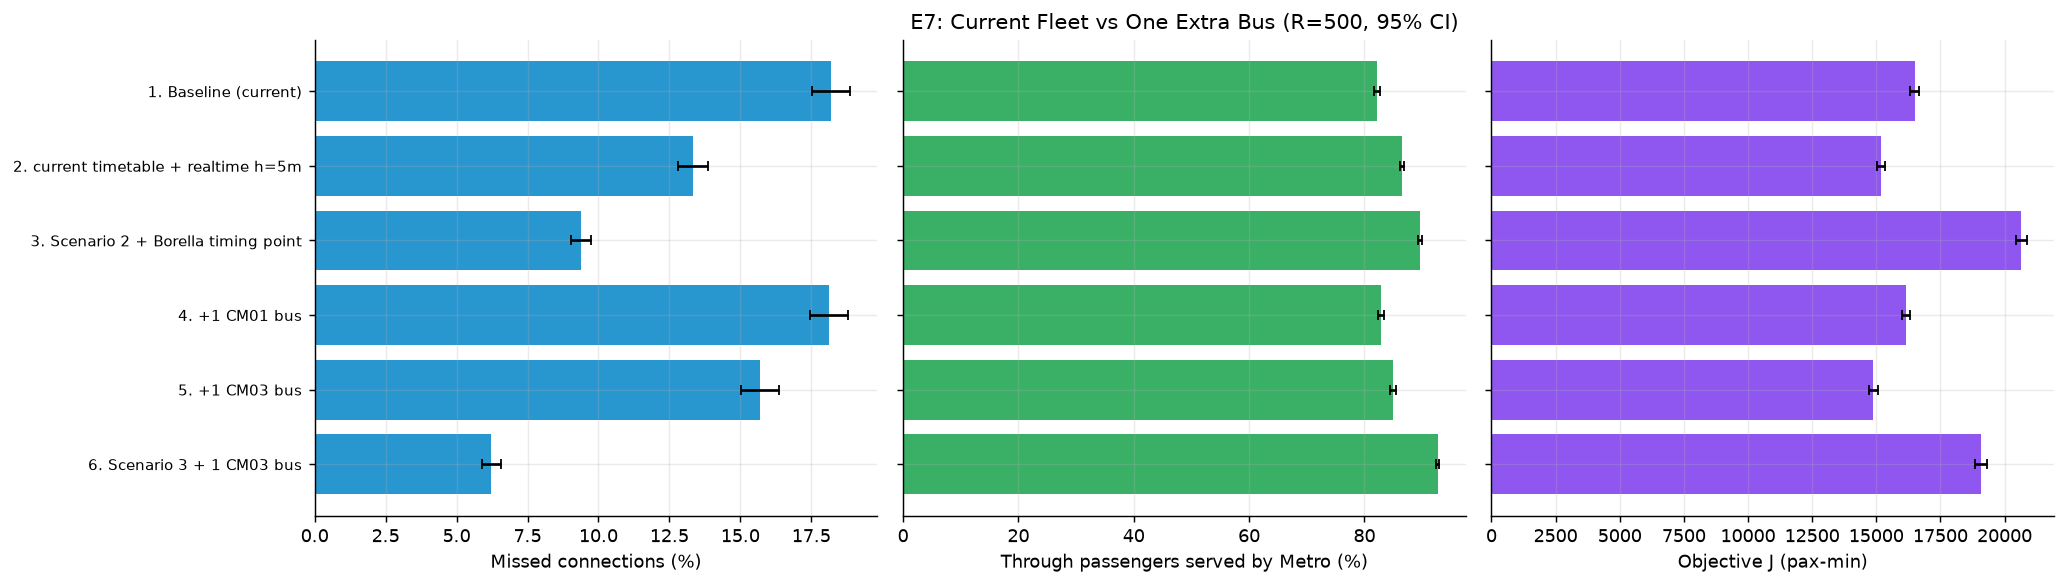


Recommended fixed timetable (2. current timetable + realtime h=5m, buses {'CM01': 12, 'CM03': 11}):
Every trip leaves its terminal at the published time. Connecting buses at Borella wait up to 5 min for a late feeder (real-time ETA).
            leg     trip_id origin_dep borella terminal_arr
CM01_MAK_to_FOR CM01-MAK-01      05:15   06:11        06:30
CM01_MAK_to_FOR CM01-MAK-02      05:45   06:41        07:00
CM01_MAK_to_FOR CM01-MAK-03      06:15   07:11        07:30
CM01_MAK_to_FOR CM01-MAK-04      06:30   07:26        07:45
CM01_MAK_to_FOR CM01-MAK-05      06:50   07:46        08:05
CM01_MAK_to_FOR CM01-MAK-06      07:10   08:06        08:25
CM01_MAK_to_FOR CM01-MAK-07      07:30   08:26        08:45
CM01_MAK_to_FOR CM01-MAK-08      07:50   08:46        09:05
CM01_MAK_to_FOR CM01-MAK-09      08:10   09:06        09:25
CM01_MAK_to_FOR CM01-MAK-10      08:45   09:41        10:00
CM01_MAK_to_FOR CM01-MAK-11      09:15   10:11        10:30
CM01_MAK_to_FOR CM01-MAK-12      09:45   10:4

In [11]:
fleet_seeds = experiment_seeds("e7_fleet", R_FLEET)
opt_pol = "none" if OPT_H_MIN == 0 else "realtime"
base_scheds = shifted_schedules()
opt_scheds = shifted_schedules(**opt_shift_kw)
timing_point_kw = {**opt_shift_kw, "connector_waits_for_schedule": True}


def fleet_of(scheds, extra):
    return {route: len(duties) for route, duties in bus_duties(scheds, extra).items()}


extra_cm01 = best_extra_bus(base_scheds, "CM01")
extra_cm03 = best_extra_bus(base_scheds, "CM03")

# label, timetables (for the bus count), extra trips, day options, policy, max hold (min)
fleet_specs = [
    ("1. Baseline (current)", base_scheds, {}, {}, "none", 0.0),
    (f"2. {REC_LABEL} + realtime h={OPT_H_MIN:.0f}m", opt_scheds, {}, opt_shift_kw, opt_pol, OPT_H_MIN),
    ("3. Scenario 2 + Borella timing point", opt_scheds, {}, timing_point_kw, opt_pol, OPT_H_MIN),
    ("4. +1 CM01 bus", base_scheds, extra_cm01, {}, "none", 0.0),
    ("5. +1 CM03 bus", base_scheds, extra_cm03, {}, "none", 0.0),
]

fleet_day_cache = {}


def fleet_days(day_kw, extra):
    shift_items = tuple(
        sorted((k, float(v)) for k, v in day_kw.items() if k in ("shift_a_min", "shift_b_min") and v != 0.0)
    )
    extra_sig = tuple(
        (leg, tuple(df[["trip_id", "origin_sched_min", "borella_sched_min", "dest_sched_min"]].itertuples(index=False, name=None)))
        for leg, df in sorted(extra.items())
        if not df.empty
    )
    cache_key = (shift_items, extra_sig)
    if cache_key not in fleet_day_cache:
        shift_kw = dict(shift_items)
        fleet_day_cache[cache_key] = [precompute_day_inputs(s, **shift_kw, extra_trips=extra) for s in fleet_seeds]
    pool = fleet_day_cache[cache_key]
    return with_timing_point(pool) if day_kw.get("connector_waits_for_schedule", False) else pool


fleet_rows = []
fleet_results = {}
for label, scheds, extra, day_kw, pol, h_v in fleet_specs:
    blocks_by_route = bus_duties(scheds, extra)
    days = fleet_days(day_kw, extra)
    res = evaluate_policy_over_days(days, pol, h_v)
    late_pct = float(np.mean([late_turnaround_pct(d, blocks_by_route) for d in days]))
    fleet_results[label] = res
    fleet_rows.append({"label": label, "buses": fleet_of(scheds, extra), "res": res, "late_pct": late_pct})

# Scenario 6: the better extra bus (by J) on top of scenario 3; its trips are placed on the shifted timetable.
best_extra_route = "CM01" if fleet_results["4. +1 CM01 bus"]["J_mean"] <= fleet_results["5. +1 CM03 bus"]["J_mean"] else "CM03"
extra_best_opt = best_extra_bus(opt_scheds, best_extra_route)
label6 = f"6. Scenario 3 + 1 {best_extra_route} bus"
blocks6 = bus_duties(opt_scheds, extra_best_opt)
days6 = fleet_days(timing_point_kw, extra_best_opt)
res6 = evaluate_policy_over_days(days6, opt_pol, OPT_H_MIN)
fleet_results[label6] = res6
fleet_rows.append({"label": label6, "buses": fleet_of(opt_scheds, extra_best_opt), "res": res6,
                   "late_pct": float(np.mean([late_turnaround_pct(d, blocks6) for d in days6]))})

e7_df = pd.DataFrame([{
    "Scenario": r["label"],
    "Buses (CM01+CM03)": f"{r['buses']['CM01']}+{r['buses']['CM03']}",
    "Miss All (%)": f"{r['res']['miss_all_pct']:.2f} +/- {r['res']['miss_all_ci']:.2f}",
    "Missed pax/day": round(r["res"]["missed_per_day"], 1),
    "Served by Metro (%)": f"{r['res']['served_pct']:.2f} +/- {r['res']['served_ci']:.2f}",
    "Mean Wait (min)": f"{r['res']['mean_wait_min']:.2f} +/- {r['res']['mean_wait_ci']:.2f}",
    "Hold Cost": round(r["res"]["hold_cost"], 1),
    "J (pax-min)": f"{r['res']['J_mean']:.1f} +/- {r['res']['J_ci']:.1f}",
    "Late turnarounds (%)": round(r["late_pct"], 1),
} for r in fleet_rows])
print(f"=== E7: Current fleet vs one extra bus (R = {R_FLEET} CRN days, 95% CI) ===")
print(e7_df.to_string(index=False))

fig, axes = plt.subplots(1, 3, figsize=(16.0, 4.6))
y_pos = np.arange(len(fleet_rows))
labels = [r["label"] for r in fleet_rows]
for ax, key, ci_key, color, xlabel in (
    (axes[0], "miss_all_pct", "miss_all_ci", "#0284c7", "Missed connections (%)"),
    (axes[1], "served_pct", "served_ci", "#16a34a", "Through passengers served by Metro (%)"),
    (axes[2], "J_mean", "J_ci", "#7c3aed", "Objective J (pax-min)"),
):
    ax.barh(y_pos, [r["res"][key] for r in fleet_rows], xerr=[r["res"][ci_key] for r in fleet_rows], color=color, alpha=0.85, capsize=3)
    ax.set_yticks(y_pos)
    ax.set_yticklabels(labels if ax is axes[0] else [], fontsize=8.5)
    ax.invert_yaxis()
    ax.set_xlabel(xlabel)
axes[1].set_title(f"E7: Current Fleet vs One Extra Bus (R={R_FLEET}, 95% CI)")
plt.tight_layout()
fig.savefig(FIGURES_DIR / "fleet_comparison.png", bbox_inches="tight")
plt.show()

# Recommended fixed timetable: the lowest-J scenario that runs on the current fleet.
current_fleet_rows = [r for r in fleet_rows if r["buses"] == BASE_FLEET]
recommended = min(current_fleet_rows, key=lambda r: r["res"]["J_mean"])
rec_scheds = opt_scheds if recommended["label"] != fleet_rows[0]["label"] else base_scheds
rec_table = pd.concat([
    df.assign(
        origin_dep=df["origin_sched_min"].map(format_minutes_to_hhmm),
        borella=df["borella_sched_min"].map(format_minutes_to_hhmm),
        terminal_arr=df["dest_sched_min"].map(format_minutes_to_hhmm),
    )[["leg", "trip_id", "origin_dep", "borella", "terminal_arr"]]
    for df in rec_scheds.values()
], ignore_index=True)
DATA_OUT_DIR = FIGURES_DIR.parent / "data"
DATA_OUT_DIR.mkdir(parents=True, exist_ok=True)
rec_table.to_csv(DATA_OUT_DIR / "recommended_timetable.csv", index=False)
print(f"\nRecommended fixed timetable ({recommended['label']}, buses {recommended['buses']}):")
print(f"Every trip leaves its terminal at the published time. Connecting buses at Borella wait up to {OPT_H_MIN:.0f} min "
      f"for a late feeder (real-time ETA)" + (" and never leave Borella before their published time." if "timing point" in recommended["label"] else "."))
print(rec_table.to_string(index=False))


=== Extension X5: Sensitivity around the joint optimal policy (base miss = 12.70 +/- 1.02%, base J per passenger = 51.6 +/- 0.8 pax-min, R = 150, 95% CI) ===
                          Parameter  Low Miss (%)  Low Miss CI  High Miss (%)  High Miss CI  Miss Swing (pp)  Low J/pax  Low J/pax CI  High J/pax  High J/pax CI
Stop arrival scale (0.75x vs 1.25x)          6.23         0.89          21.36          1.10            15.13      43.85          0.69       61.55           0.97
     Transfer mean (3.0 vs 8.0 pax)         11.12         1.05          15.73          0.96             4.62      50.57          0.93       54.94           0.79
       Walk time w (2.0 vs 6.5 min)         10.17         0.86          14.16          1.10             4.00      47.45          0.83       53.95           0.89
Passenger patience P (10 vs 30 min)         12.61         1.01          13.25          1.04             0.64      53.18          0.95       49.78           0.70


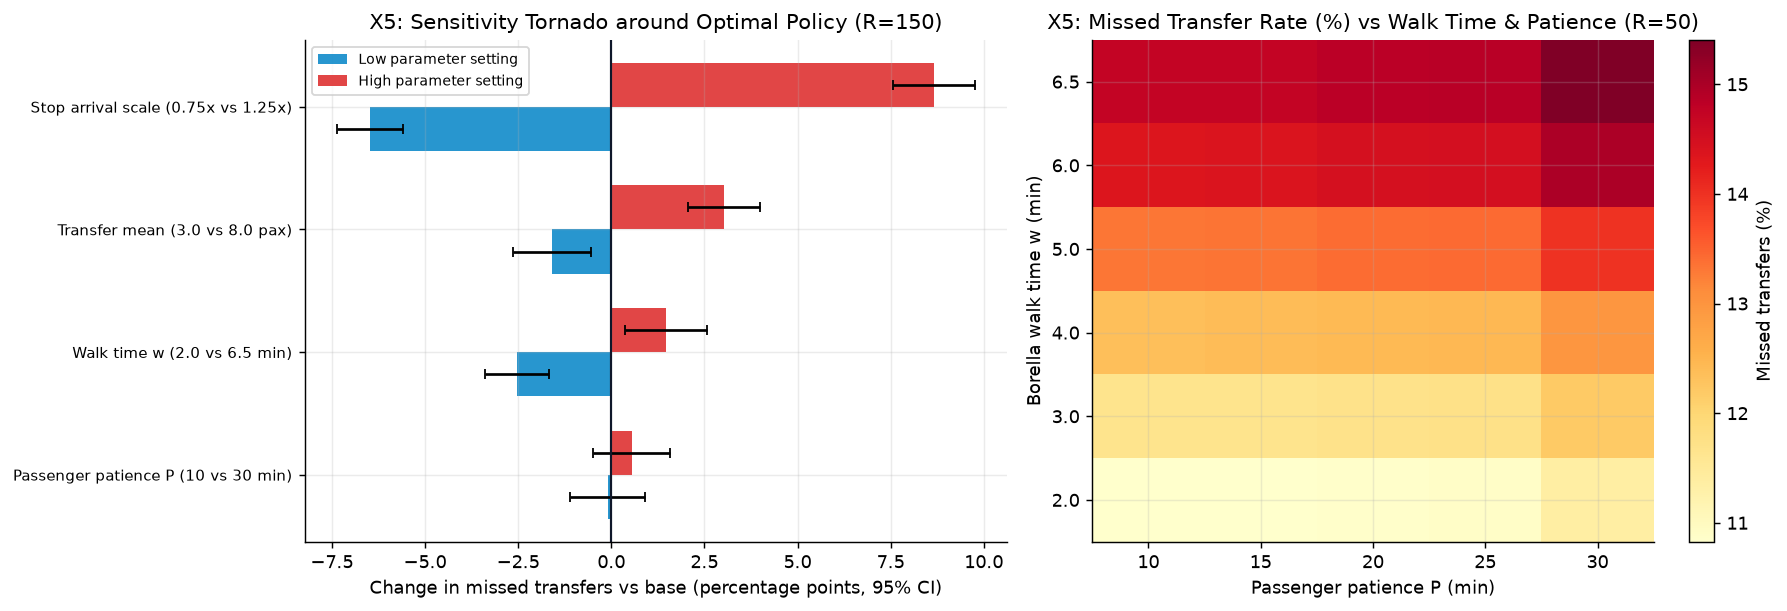


=== Extension X6: Vectorized Markov Chain Benchmark (2000 days x 240 slots) ===
Python loop time: 0.1371 s | Vectorized NumPy time: 0.0107 s | Measured speed-up: 12.8x


In [12]:
sens_seeds = experiment_seeds("sensitivity", R_SENS)
opt_pol = "none" if OPT_H_MIN == 0 else "realtime"

sens_day_cache = {}


def get_sens_days(case_kwargs, n_days):
    # Precomputed days do not depend on walk_time_min (walk is evaluated in Borella transfers only).
    key = (
        float(case_kwargs.get("transfer_mean_pax", TRANSFER_MEAN_PAX)),
        float(case_kwargs.get("arrival_rate_scale", 1.0)),
        float(case_kwargs.get("patience_min", PASSENGER_PATIENCE_MIN)),
    )
    cached = sens_day_cache.get(key, [])
    if len(cached) < n_days:
        cached = cached + [
            precompute_day_inputs(
                s,
                **opt_shift_kw,
                transfer_mean_pax=key[0],
                arrival_rate_scale=key[1],
                patience_min=key[2],
            )
            for s in sens_seeds[len(cached):n_days]
        ]
        sens_day_cache[key] = cached
    return cached[:n_days]


sens_base_days = get_sens_days({}, R_SENS)
sens_base = evaluate_policy_over_days(sens_base_days, opt_pol, OPT_H_MIN)

sensitivity_specs = [
    ("Walk time w (2.0 vs 6.5 min)", {"walk_time_min": 2.0}, {"walk_time_min": 6.5}),
    ("Passenger patience P (10 vs 30 min)", {"patience_min": 10.0}, {"patience_min": 30.0}),
    ("Transfer mean (3.0 vs 8.0 pax)", {"transfer_mean_pax": 3.0}, {"transfer_mean_pax": 8.0}),
    ("Stop arrival scale (0.75x vs 1.25x)", {"arrival_rate_scale": 0.75}, {"arrival_rate_scale": 1.25}),
]


def run_sens_case(case_kwargs, seeds=sens_seeds):
    days = get_sens_days(case_kwargs, len(seeds))
    return evaluate_policy_over_days(
        days,
        opt_pol,
        OPT_H_MIN,
        walk_time_min=case_kwargs.get("walk_time_min", WALK_TIME_MIN),
    )


tornado_rows = []
for label, low_kw, high_kw in sensitivity_specs:
    low_res = run_sens_case(low_kw)
    high_res = run_sens_case(high_kw)
    tornado_rows.append({
        "Parameter": label,
        "Low Miss (%)": low_res["miss_all_pct"],
        "Low Miss CI": low_res["miss_all_ci"],
        "High Miss (%)": high_res["miss_all_pct"],
        "High Miss CI": high_res["miss_all_ci"],
        "Miss Swing (pp)": abs(high_res["miss_all_pct"] - low_res["miss_all_pct"]),
        "Low J/pax": low_res["J_per_pax"],
        "Low J/pax CI": low_res["J_per_pax_ci"],
        "High J/pax": high_res["J_per_pax"],
        "High J/pax CI": high_res["J_per_pax_ci"],
    })

tornado_df = pd.DataFrame(tornado_rows).sort_values("Miss Swing (pp)", ascending=True)
base_miss_sens = sens_base["miss_all_pct"]
print(f"=== Extension X5: Sensitivity around the joint optimal policy (base miss = {base_miss_sens:.2f} +/- {sens_base['miss_all_ci']:.2f}%, "
      f"base J per passenger = {sens_base['J_per_pax']:.1f} +/- {sens_base['J_per_pax_ci']:.1f} pax-min, R = {R_SENS}, 95% CI) ===")
print(tornado_df.sort_values("Miss Swing (pp)", ascending=False).round(2).to_string(index=False))

sens_2d_seeds = sens_seeds[:R_SENS_2D]
walk_sweep = np.array([2.0, 3.0, 4.0, 5.0, 6.0, 6.5])
patience_sweep = np.array([10.0, 15.0, 20.0, 25.0, 30.0])
sens_2d = np.zeros((len(walk_sweep), len(patience_sweep)))
for r_i, w_val in enumerate(walk_sweep):
    for c_i, patience in enumerate(patience_sweep):
        out_2d = run_sens_case({"walk_time_min": float(w_val), "patience_min": float(patience)}, seeds=sens_2d_seeds)
        sens_2d[r_i, c_i] = out_2d["miss_all_pct"]

fig, axes = plt.subplots(1, 2, figsize=(14.0, 4.8))
y_idx = np.arange(len(tornado_df))
axes[0].barh(y_idx - 0.18, tornado_df["Low Miss (%)"] - base_miss_sens, height=0.36, xerr=tornado_df["Low Miss CI"],
             color="#0284c7", alpha=0.85, capsize=3, label="Low parameter setting")
axes[0].barh(y_idx + 0.18, tornado_df["High Miss (%)"] - base_miss_sens, height=0.36, xerr=tornado_df["High Miss CI"],
             color="#dc2626", alpha=0.85, capsize=3, label="High parameter setting")
axes[0].axvline(0.0, color="#0f172a", linewidth=1.2)
axes[0].set_yticks(y_idx)
axes[0].set_yticklabels(tornado_df["Parameter"], fontsize=8.5)
axes[0].set_xlabel("Change in missed transfers vs base (percentage points, 95% CI)")
axes[0].set_title(f"X5: Sensitivity Tornado around Optimal Policy (R={R_SENS})")
axes[0].legend(fontsize=8)

im_s = axes[1].imshow(sens_2d, aspect="auto", origin="lower", cmap="YlOrRd")
axes[1].set_xticks(range(len(patience_sweep)))
axes[1].set_xticklabels([f"{v:.0f}" for v in patience_sweep])
axes[1].set_yticks(range(len(walk_sweep)))
axes[1].set_yticklabels([f"{w:.1f}" for w in walk_sweep])
axes[1].set_xlabel("Passenger patience P (min)")
axes[1].set_ylabel("Borella walk time w (min)")
axes[1].set_title(f"X5: Missed Transfer Rate (%) vs Walk Time & Patience (R={R_SENS_2D})")
plt.colorbar(im_s, ax=axes[1], label="Missed transfers (%)")

plt.tight_layout()
fig.savefig(FIGURES_DIR / "sensitivity_tornado.png", bbox_inches="tight")
plt.show()

N_CHAINS_BENCH = 2000
N_SLOTS_BENCH = 240
bench_seeds = experiment_seeds("benchmark", 2)
bench_rng_loop = np.random.default_rng(bench_seeds[0])
bench_rng_vec = np.random.default_rng(bench_seeds[1])

t0 = time.perf_counter()
loop_out = np.vstack([simulate_markov_chain_loop(P_peak, N_SLOTS_BENCH, bench_rng_loop) for _ in range(N_CHAINS_BENCH)])
t_loop_sec = time.perf_counter() - t0

t1 = time.perf_counter()
vec_out = simulate_markov_chain_vectorized(P_peak, N_SLOTS_BENCH, N_CHAINS_BENCH, bench_rng_vec)
t_vec_sec = time.perf_counter() - t1

assert loop_out.shape == vec_out.shape == (N_CHAINS_BENCH, N_SLOTS_BENCH)
speedup = t_loop_sec / max(1e-9, t_vec_sec)
print(f"\n=== Extension X6: Vectorized Markov Chain Benchmark ({N_CHAINS_BENCH} days x {N_SLOTS_BENCH} slots) ===")
print(f"Python loop time: {t_loop_sec:.4f} s | Vectorized NumPy time: {t_vec_sec:.4f} s | Measured speed-up: {speedup:.1f}x")

## 6. Discussion and limitations

*Provenance: AI-generated then modified.*

### Key Insights

1. **Traffic from data (Checks 1-2):** The traffic chain is estimated from about 68,000 cmb_traffic observations on the roads both bus routes use. Real traffic is persistent (a state usually lasts about an hour) and moves step by step between free, slow and jammed. The simulated day reproduces the observed state shares within 0.19 and mean speeds within 7.9% for every hour from 05:00 to 22:00; the largest gaps are the morning build-up and the late evening. Buses reach Borella within about $\pm 8$ min of their scheduled time.
2. **Diagnosis of the current timetable (`E1`):** With buses every 15-35 min, peak buses full and passengers willing to wait about 20 min, `18.2%` of through passengers (about 51 of 290 a day) miss the planned connection: `11.0%` through timing and `7.2%` because the connecting bus is full. `14.6%` give up and use other transport. The median scheduled slack is only 8.3 min, and five connections are scheduled shorter than the 5-min walk (four Pettah-to-Kadawatha pairs by 1.7 min, one Kadawatha-to-Pettah pair by 1.4 min).
3. **Holding works (`E2`):** Real-time holding reduces misses steadily: about `14.6%` with holds of up to 3 min, `13.2%` up to 5 min and about `10.8%` up to 10 min. At the same limit, real-time holding misses about as many connections as schedule holding but costs riders on board under a third of the time (about 230 vs 800 passenger-minutes a day at 5 min).
4. **Timetable shifts do not add to holding (`E3`):** CM03 towards Kadawatha cannot move earlier, because one bus has no layover before that trip. With holding, running CM01 towards Pettah 5 min earlier gives the same $J$ (14,998 vs 14,978 pax-min) but more misses (`16.0%` vs `13.3%`), and running CM03 towards Kadawatha 5 min later gives fewer misses (`11.5%`) but a higher $J$, because passengers on every other connection wait longer. Neither is significantly better in a paired day-by-day test, so the simplest policy (no shift) is recommended. A shift alone helps little (best: both connecting directions $+5$ min, `14.8%` missed, $J$ -0.2%). With the earlier 3.5-min walk placeholder, the CM01 shift had a 1.7% lower $J$; with the 5-min walk estimated from the map it no longer helps, so the shift result depends on the walk time.
5. **Recommended policy:** keep the current timetable and let connecting buses wait up to 5 min at Borella using live bus positions. On 1,000 days this cuts missed connections from `18.2%` to `13.2%` (about 51 to 37 passengers a day), passengers lost to other transport from `14.6%` to `10.1%`, mean Borella wait from 22.0 to 19.2 min and $J$ from 16,406 to 15,077 pax-min (-8%), for about 240 pax-min a day of extra time for riders on board and no change to the timetable or the fleet.
6. **The 5-min cap is an operating choice:** $J$ keeps falling up to holds of about 7 min, but the objective does not charge knock-on delay to the bus's later trips, to riders further down the route or to traffic behind a bus held at a roadside halt. Capping the hold at 5 min keeps the recommendation within what the model supports.
7. **Value of real-time ETAs (`E4`):** At the recommended policy, real-time holding uses under a third of the on-board hold time of schedule holding (249 vs 863 pax-min) for nearly the same misses (`13.2%` vs `12.9%`). Its misses rise to `14.4%` as the ETA error grows to 4 min.
8. **Full buses matter (`E5`):** With unlimited capacity the recommended policy would miss only `5.6%` (`2.8%` Pettah-to-Kadawatha, `9.2%` Kadawatha-to-Pettah). Peak crowding is the main remaining cause of misses for passengers heading to Kadawatha, which holding cannot fix.
9. **Fleet (`E7`):** The 12 CM01 and 11 CM03 buses run every trip with feasible layovers. One extra CM03 bus placed to even out headways would save slightly more passenger time than holding ($J$ 14,888 vs 15,177 pax-min) because it adds space at full times, but it misses more connections (`15.7%` vs `13.3%`) and needs an extra bus, which the question rules out; an extra CM01 bus barely helps. Two late Kadawatha feeders have no CM01 connection at all; one later CM01 trip would serve them (not tested).
10. **Ticket validity (`E6`):** With patience and validity limits removed, 99.99% of through passengers who board do so within 2 hours, and 95% within about 55 min. A one-hour part-paid ticket would cover almost everyone.
11. **Borella timing point:** If connectors never left Borella before their published time, misses would fall further (`9.4%` with the recommended policy), but every early connector would wait with its passengers on board, adding about 5,600 pax-min a day and raising $J$ to about 20,700. Metro buses do not wait at Borella today (author's observation).
12. **What drives the answer (`X5`):** Stop demand matters most (`6.2%` to `21.4%` missed for $0.75\times$ to $1.25\times$ demand), then transfer demand (`11.1%` to `15.7%` for 3-8 per bus) and walk time (`10.2%` to `14.2%` for 2.0-6.5 min). Patience barely changes the miss rate (`12.6%` to `13.3%` for 10-30 min); it changes how many give up, not how many connect.

### Key Limitations and Future Work

- **Assumed passenger demand and walk time:** Stop-level arrival rates, transfer demand and the bus capacity are assumptions, and the Borella walk $w = 5.0$ min is estimated from the 370 m route along Baseline Road, not measured. Demand was scaled so peak buses fill up, as the author observes on Metro buses; it is the input the results depend on most. Demand per minute also does not fall when buses run only hourly; in reality some passengers would take other buses then, so hourly off-peak trips may be fuller in the model than on the road.
- **Traffic coverage:** the 12 cmb_traffic route directions cover the main roads of both bus routes, but not every street (for example Narahenpita and the last kilometres to Makumbura and Kadawatha), and they are car travel times from Google Maps, not bus times. One chain pooled over all of them is used for every route direction, each evolving independently; real congestion would correlate the routes.
- **Morning build-up:** cmb_traffic has fewer observations between 07:00 and 09:00 (584 pairs), so the morning matrix is less precise and the simulated build-up comes a little late. There is no data before 05:00, so traffic is taken as free until then.
- **Run times and Borella times:** The app gives departure times only. Run times come from metrobus.lk travel times (75 and 120 min) for every trip of the day, and Borella is placed by road distance, assuming constant scheduled speed. Early-morning buses therefore run ahead of schedule in the model, and evening-peak buses run late, which also overstates how long early connectors would wait at a Borella timing point.
- **Timetable snapshot:** The timetable was copied from the LMT-GO app on 19 Nov 2026; the metrobus.lk website still lists an older timetable. Timetables change without notice.
- **Stop coordinates are geocoded:** Road distances come from OSRM routing between geocoded stops. Apeksha Hospital and Kelaniya University were moved onto the bus road; their real halt positions are unverified.
- **Bus duties are checked, not simulated:** The real bus duties are used for the fleet, shift and turnaround checks, but the simulation runs each trip from its published time, so a late or held bus does not delay its next trip.
- **Extra bus placement:** The extra bus is placed by a headway rule within the route's current service hours, not to target transfers. An evening CM01 trip aimed at the two unconnected Kadawatha feeders was not tested.
- **Timing point settings:** The timing-point scenario reuses the recommended hold; it was not re-optimised.
- **Holding at a roadside halt:** a held bus at a busy roadside stop can block traffic and the buses behind it; this is not modelled. Holds are capped at 5 min. The real-time rule also does not check whether the connector has space, so it can hold a bus whose transferring passengers are then refused; checking the bus load first would save some hold time.
- **Passenger behaviour assumptions:** Patience $P = 20$ min, validity $V = 120$ min and the 60 min alternative-travel penalty are assumptions. Passengers judge the next bus by its timetable time, not a live prediction.
- **Borella boarding simplifications:** Boarding at Borella does not add to the connector's dwell, and through passengers are not counted in the feeder's load.


## 7. References

*Provenance: AI-generated then modified.*

Numbers in brackets in the text, such as [3], refer to this list.

1. A. M. Law, *Simulation Modeling and Analysis*, 5th ed. New York, NY, USA: McGraw-Hill, 2015.
2. T. Amalan, "Analysis of Bus Passenger Demand and Supply: Case Study on Western Province, Sri Lanka," *International Journal of Scientific Research and Management (IJSRM)*, vol. 9, no. 11, pp. 2544-2554, Nov. 2021, doi: 10.18535/ijsrm/v9i11.em03.
3. N. I. Senaratna, "Colombo Traffic Index (`cmb_traffic`): Open Urban Road Travel-Time Dataset," GitHub repository (MIT License). [Online]. Available: https://github.com/nuuuwan/cmb_traffic
4. Lanka Metro Transit, "LMT-GO Route Schedules (Routes CM01 and CM03)," LMT-GO mobile application, accessed Nov. 19, 2026; scheduled run times from https://metrobus.lk, accessed Nov. 19, 2026.
5. R. W. Hall, M. Dessouky, and Q. Lu, "Optimal holding times at transfer stations," *Computers & Industrial Engineering*, vol. 40, no. 4, pp. 379-397, 2001, doi: 10.1016/S0360-8352(01)00039-0.
6. S. M. Ross, *Simulation*, 6th ed. London, U.K.: Academic Press, 2023.